# Analisis Matematis & Pemodelan Beban Listrik Per Jam Panama (2015–2020)

Notebook ini mengimplementasikan rancangan penelitian lengkap sesuai dokumen `Plan_Analisis_Matematis_Beban_Listrik_Panama.md` pada dataset `Panama_beban_listrik_per_jam_2015-2020_.xlsx`.

### Peta Eksplisit: Train–Test Split, Cross-Validation, & Hasil Forecasting

| Komponen Metodologi | Implementasi di Notebook | Lokasi Tahap / Sel |
| :--- | :--- | :--- |
| **Train–Test Split** | **Pembagian kronologis 3 rezim (tanpa *random split*):**<br>• **Training (`2015–2018`):** `35.015` jam (`2015-01-03 01:00` s.d. `2018-12-31 23:00`)<br>• **Test Normal (`2019`):** `8.760` jam (`2019-01-01` s.d. `2019-12-31`, diuji dengan & tanpa 5 titik *blackout*)<br>• **Test Disrupsi COVID-19 (`2020`):** `4.273` jam (`Jan–27 Jun 2020`; fokus lockdown `Mar–Jun 2020` = `2.833` jam) | **Tahap 1.3** |
| **Cross-Validation (CV)** | • **Expanding-Window `TimeSeriesSplit` (3-fold di dalam `2015–2018`):** dijalankan eksplisit pada **GAM** (Tahap 4) dan **Gradient Boosting** (Tahap 5).<br>• **Rolling Weekly Origin ($h=168$ jam):** validasi *walk-forward* mingguan pada **SARIMA/SARIMAX** (Tahap 2).<br>• **Placebo Test (`Mar–Jun 2019`):** validasi *out-of-sample* model kontrafaktual **GAM** (Tahap 4). | **Tahap 2, 4, & 5** |
| **Hasil Forecasting (*Backtesting Out-of-Sample*)** | • **Jangka Pendek (STLF, $h=168$ jam):** perbandingan menyeluruh antara model dasar (`Seasonal Naive`, `SARIMA`, `SARIMAX`) vs model solusi (`HistGradientBoosting`/`LightGBM` Set B, termasuk interval kuantil 90% `Q05–Q95`).<br>• **Jangka Panjang (Eksogen 1 Tahun / Multi-Bulan, tanpa lag beban):** `GAM` (Set A) untuk evaluasi `2019` dan *counterfactual* `Jan–Jun 2020`. | **Tahap 2, 4, 5, & 7** |
| **Hasil Forecasting (*Proyeksi Masa Depan Out-of-Dataset*)** | • **Jangka Pendek (7 Hari / `168` Jam ke Depan: `27 Jun – 4 Jul 2020`):** `HistGradientBoosting` Set B (titik + interval prediksi 90%).<br>• **Jangka Panjang (12 Bulan ke Depan: `Jul 2020 – Jun 2021`, `8.760` jam):** `GAM` Set A dalam **2 skenario** (Pemulihan Normal Pra-COVID vs Tekanan Pandemi Berkelanjutan). | **Tahap 8 (8A & 8B)** |

### Alur Deduktif Penelitian
1. **Tahap 1 — Karakterisasi Statistik & Persiapan Data:** Audit non-stasioneritas (ADF & KPSS), musiman ganda (FFT Periodogram & ACF), multikolinearitas spasial 3 kota (korelasi & VIF), heteroskedastisitas (Breusch-Pagan & ARCH-LM), penanganan 8 titik *blackout*, serta pembagian kronologis 3 rezim (`2015–2018` latih, `2019` uji normal, `2020` uji disrupsi COVID-19).
2. **Tahap 2 — Baseline & Model Dasar (`Seasonal Naive`, `SARIMA`, `SARIMAX`) + Pembuktian Ketidakmemadaian:** Evaluasi forecasting jangka pendek ($h=168$ jam, *rolling weekly*) beserta bukti teoretis dan diagnostik empiris (kebocoran ACF di lag `168`, Uji Ljung-Box, Jarque-Bera, ARCH-LM, dan *over-forecast* saat pandemi).
3. **Tahap 3 — Rekayasa Fitur Terpisah:** Pemisahan ketat **Set A (Eksogen Murni)** untuk inferensi/jangka panjang/kontrafaktual dan **Set B (Prediktif Penuh, $h=168$ jam)** untuk STLF.
4. **Tahap 4 — Model Solusi 1 (`GAM` + CV `TimeSeriesSplit` + Dampak Kausal COVID-19):** *Penalized B-Splines* untuk kurva non-linear suhu, profil harian, efek 22 kategori `Holiday_ID`, CV 3-fold (`2015–2018`), uji *placebo* `Maret–Juni 2019`, dan estimasi *counterfactual* `Maret–Juni 2020`.
5. **Tahap 5 — Model Solusi 2 (`LightGBM` / `HistGradientBoosting` + CV `TimeSeriesSplit` + *Quantile Loss*):** Peramalan STLF titik dan interval prediksi 90% ($\tau \in \{0{,}05, 0{,}50, 0{,}95\}$) beserta *TreeSHAP* / *Permutation Importance & Partial Dependence*.
6. **Tahap 6 (Opsional) — *Temporal Fusion Transformer* (TFT):** Templat opsional apabila `pytorch-forecasting` tersedia.
7. **Tahap 7 — Evaluasi Komparatif Lengkap (Metode Dasar vs Model Solusi) & Uji *Diebold-Mariano*:** Perbandingan seluruh 5 model (`Seasonal Naive`, `SARIMA`, `SARIMAX`, `GAM`, `HistGradientBoosting`) dengan estimator varians Newey-West (HAC), dipisahkan menurut kategori jangka pendek vs jangka panjang.
8. **Tahap 8 — Hasil Forecasting Eksplisit ke Masa Depan:** Proyeksi **Jangka Pendek 7 Hari (`27 Jun – 4 Jul 2020`)** dan **Jangka Panjang 12 Bulan (`Jul 2020 – Jun 2021`)** di luar akhir dataset.

#### Persiapan Lingkungan & Dependensi (Algoritma Kode — Sel 1)
1. **Impor Pustaka Inti:** Memuat `numpy`, `pandas`, `scipy` (statistik & FFT), `scikit-learn` (`PCA`, `StandardScaler`, `TimeSeriesSplit`, `HistGradientBoostingRegressor`, `permutation_importance`, `partial_dependence`), dan `statsmodels` (`SARIMAX`, `GLMGam`, `BSplines`, uji diagnostik).
2. **Konfigurasi Visualisasi:** Mengatur parameter global `matplotlib` (`plt.rcParams.update(...)`) untuk gaya grafik bersih tanpa garis tepi atas/kanan.
3. **Deteksi Paket Opsional:** Menggunakan `importlib.util.find_spec()` untuk mengecek ketersediaan `lightgbm`, `shap`, dan `pytorch_forecasting`/`torch`; jika `lightgbm` belum terpasang, Tahap 5 otomatis beralih ke `HistGradientBoostingRegressor`.
4. **Resolusi Lokasi Dataset:** Memeriksa daftar `CANDIDATE_PATHS` secara berurutan dan memvalidasi keberadaan file Excel dengan `assert`.

In [1]:
import importlib.util
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.fft import rfft, rfftfreq
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

import statsmodels.api as sm
from statsmodels.gam.api import BSplines, GLMGam
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_breuschpagan
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

# Styling pure matplotlib (tanpa seaborn)
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# Cek ketersediaan paket opsional
HAS_LGBM = importlib.util.find_spec("lightgbm") is not None
HAS_SHAP = importlib.util.find_spec("shap") is not None
HAS_TFT = importlib.util.find_spec("pytorch_forecasting") is not None and importlib.util.find_spec("torch") is not None

print(f"Paket opsional -> LightGBM: {HAS_LGBM} | SHAP: {HAS_SHAP} | TFT (PyTorch Forecasting): {HAS_TFT}")
if not HAS_LGBM:
    print("Info: lightgbm belum terpasang; Tahap 5 otomatis menggunakan sklearn.ensemble.HistGradientBoostingRegressor (mendukung L2, absolute/L1, dan quantile loss). Opsional: pip install lightgbm shap")

# Lokasi file dataset
CANDIDATE_PATHS = [
    "Panama_beban_listrik_per_jam_2015-2020_.xlsx",
    r"c:\Users\user\Documents\S2\Semester 2\Analisis Data Lanjut\W12 adl 1\Panama_beban_listrik_per_jam_2015-2020_.xlsx",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
assert DATA_PATH is not None, "File Panama_beban_listrik_per_jam_2015-2020_.xlsx tidak ditemukan!"
print("Dataset ditemukan:", os.path.abspath(DATA_PATH))

Paket opsional -> LightGBM: False | SHAP: False | TFT (PyTorch Forecasting): False
Info: lightgbm belum terpasang; Tahap 5 otomatis menggunakan sklearn.ensemble.HistGradientBoostingRegressor (mendukung L2, absolute/L1, dan quantile loss). Opsional: pip install lightgbm shap
Dataset ditemukan: c:\Users\user\Documents\S2\Semester 2\Analisis Data Lanjut\W12 adl 1\Panama_beban_listrik_per_jam_2015-2020_.xlsx


---
## Tahap 1: Karakterisasi Statistik Dataset & Persiapan Data

Secara formal, target $Y_t$ (`nat_demand`, satuan MWh) diamati per jam sepanjang $t = 1, \dots, 48.048$ bersama vektor kovariat meteorologi tiga kota (Tocumen `_toc`, Santiago `_san`, David `_dav`) dan kalender:

$$\mathbf{X}_t = \left[ \mathbf{W}_t^{(\text{toc})},\; \mathbf{W}_t^{(\text{san})},\; \mathbf{W}_t^{(\text{dav})},\; \text{holiday}_t,\; \text{Holiday\_ID}_t,\; \text{school}_t \right]^\top$$

Pada tahap ini kita melakukan inspeksi struktur, audit sifat statistik (stasioneritas, spektrum musiman ganda, multikolinearitas spasial/VIF, heteroskedastisitas, serta *outlier blackout*), lalu menyusun pembagian kronologis 3 rezim.

### Penjelasan Algoritma Matematis (Tahap 1.1–1.2)
1. **Uji Stasioneritas Ganda (ADF & KPSS):**
   - **Augmented Dickey-Fuller (ADF):** Menguji keberadaan akar unit ($H_0: \gamma = 0$, non-stasioner) pada persamaan regresi dengan tren dan *lag* diferensiasi:
     $$\Delta Y_t = \alpha + \beta t + \gamma Y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta Y_{t-i} + \varepsilon_t$$
   - **KPSS:** Menguji hipotesis kebalikan ($H_0: \sigma_u^2 = 0$, stasioner di sekitar tren deterministik) pada dekomposisi $Y_t = \xi t + r_t + \varepsilon_t$ dengan $r_t = r_{t-1} + u_t$. Kombinasi tolakan ADF dan KPSS pada level membuktikan deret memiliki **tren dan komponen musiman deterministik**.
2. **Identifikasi Musiman Ganda (Periodogram FFT & ACF):**
   - Spektrum daya diskret dihitung dari deret terpusat $\tilde{Y}_t = Y_t - \bar{Y}$ via *Real Fast Fourier Transform*:
     $$P(f_k) = \frac{1}{N}\left|\sum_{t=0}^{N-1}\tilde{Y}_t e^{-i 2\pi k t / N}\right|^2, \qquad T_k = \frac{1}{f_k}$$
   - Fungsi autokorelasi sampel $\hat{\rho}(k) = \frac{\sum_{t=k+1}^N (Y_t-\bar{Y})(Y_{t-k}-\bar{Y})}{\sum_{t=1}^N (Y_t-\bar{Y})^2}$ memverifikasi puncak berulang di lag $24$ jam (harian) dan $168$ jam (mingguan).
3. **Audit Multikolinearitas Spasial (VIF):**
   - Dari matriks korelasi Pearson $\mathbf{R} \in \mathbb{R}^{12 \times 12}$ variabel cuaca 3 kota, *Variance Inflation Factor* dihitung melalui diagonal invers matriks korelasi:
     $$\text{VIF}_j = \left(\mathbf{R}^{-1}\right)_{jj} = \frac{1}{1 - R_j^2}$$
     Nilai $\text{VIF}_j > 10$ mengonfirmasi kolinearitas spasial tinggi antar-stasiun suhu.
4. **Uji Heteroskedastisitas (Breusch-Pagan & Engle ARCH-LM):**
   - Dari residual OLS pendahuluan $\hat{e}_t = Y_t - \hat{Y}_t^{\text{OLS}}$, uji **Breusch-Pagan** menguji ketergantungan varians $\hat{e}_t^2$ terhadap kovariat ($LM = n R_{\hat{e}^2}^2 \sim \chi^2_p$), sedangkan **Engle ARCH-LM($q$)** menguji pengelompokan volatilitas antar-waktu lewat regresi $\hat{e}_t^2$ terhadap $\hat{e}_{t-1}^2, \dots, \hat{e}_{t-q}^2$ ($q=24$).

### Penjelasan Algoritma Kode (Sel 3 & Sel 4)
- **Sel 3 (Inspeksi Struktur & Deteksi Anomali):**
  1. Membaca sheet `data` dan `deskripsi` via `pd.read_excel()`, mengonversi `datetime` ke `datetime64` dan mengurutkan kronologis.
  2. Memvalidasi kontinuitas interval 1 jam dengan `df["datetime"].diff().dropna().value_counts()`.
  3. Menghitung ringkasan tahunan (`groupby("year")`), membandingkan perubahan YoY bulan `Maret–Juni` (`2019` vs `2020`) untuk membuktikan *structural break* COVID-19, dan menyaring titik ekstrem (`nat_demand < 600` MWh) untuk mengidentifikasi 8 peristiwa *blackout*.
- **Sel 4 (Audit Stokastik & Plot Diagnostik 2×2):**
  1. Mendefinisikan `run_stationarity_tests()` yang memanggil `adfuller(..., maxlag=48, autolag="AIC")` dan `kpss(..., regression="ct")` pada level $Y_t$, diferensi pertama $(1-B)Y_t$, serta diferensi musiman $(1-B^{24})Y_t$ pra-pandemi (`2015–2019`).
  2. Menghitung spektrum daya memakai `scipy.fft.rfft` / `rfftfreq` dan mengambil 8 puncak frekuensi terbesar.
  3. Menghitung matriks korelasi `weather_cols` lalu `np.diag(np.linalg.inv(corr_mat_w))` untuk memperoleh VIF masing-masing fitur cuaca.
  4. Menjalankan `sm.OLS()`, `het_breuschpagan()`, dan `het_arch(..., nlags=24)`, lalu merangkum temuan ke dalam 4 panel plot (deret harian + blackout, YoY COVID-19, Periodogram FFT, dan ACF hingga lag 180).

In [2]:
df = pd.read_excel(DATA_PATH, sheet_name="data")
desc = pd.read_excel(DATA_PATH, sheet_name="deskripsi")

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

print(f"Dimensi data: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Rentang waktu: {df['datetime'].min()} s.d. {df['datetime'].max()}")
print(f"Total missing values: {int(df.isna().sum().sum())}")
print("Pemeriksaan selisih waktu (value_counts):")
print(df["datetime"].diff().dropna().value_counts().to_string())

print("\n--- Metadata Kolom (Sheet 'deskripsi') ---")
display(desc)

print("\n--- Ringkasan Statistik nat_demand ---")
print(df["nat_demand"].describe().round(4).to_string())

df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month

print("\n--- Rata-rata & Simpangan Baku Tahunan (2015-2020) ---")
yearly_stats = df.groupby("year")["nat_demand"].agg(["count", "mean", "std", "min", "max"]).round(2)
display(yearly_stats)

print("\n--- Perbandingan YoY Maret-Juni (2019 vs 2020: Dampak COVID-19) ---")
mj = df[df["month"].isin([3, 4, 5, 6])].groupby(["year", "month"])["nat_demand"].mean().unstack().round(2)
mj_cmp = pd.DataFrame({
    "2019_MWh": mj.loc[2019],
    "2020_MWh": mj.loc[2020],
    "Perubahan_MWh": (mj.loc[2020] - mj.loc[2019]).round(2),
    "Perubahan_%": ((mj.loc[2020] - mj.loc[2019]) / mj.loc[2019] * 100).round(2),
})
display(mj_cmp)

print("\n--- Identifikasi Anomali Ekstrem (nat_demand < 600 MWh) ---")
blackouts = df[df["nat_demand"] < 600][["datetime", "nat_demand", "holiday", "Holiday_ID", "school"]]
display(blackouts)

Dimensi data: 48,048 baris x 17 kolom
Rentang waktu: 2015-01-03 01:00:00 s.d. 2020-06-27 00:00:00
Total missing values: 0
Pemeriksaan selisih waktu (value_counts):
datetime
0 days 01:00:00    48047

--- Metadata Kolom (Sheet 'deskripsi') ---


,kolom,deskripsi,satuan
0,datetime,"Tanggal-waktu, zona waktu Panama UTC−05:00",tanggal-waktu
1,nat_demand,Beban listrik nasional,MWh
2,T2M_toc,"Suhu pada ketinggian 2 meter di Tocumen, Kota ...",°C
3,QV2M_toc,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
4,TQL_toc,"Presipitasi cair (menurut README) di Tocumen, ...",l/m² (menurut README)
5,W2M_toc,Kecepatan angin pada ketinggian 2 meter di Toc...,m/s (menurut README)
6,T2M_san,Suhu pada ketinggian 2 meter di Kota Santiago,°C
7,QV2M_san,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
8,TQL_san,Presipitasi cair (menurut README) di Kota Sant...,l/m² (menurut README)
9,W2M_san,Kecepatan angin pada ketinggian 2 meter di Kot...,m/s (menurut README)



--- Ringkasan Statistik nat_demand ---
count    48048.0000
mean      1182.8686
std        192.0689
min         85.1925
25%       1020.0569
50%       1168.4277
75%       1327.5640
max       1754.8820

--- Rata-rata & Simpangan Baku Tahunan (2015-2020) ---


,count,mean,std,min,max
year,,,,,
2015,8711,1131.53,194.15,509.84,1645.48
2016,8784,1157.19,190.29,744.43,1615.25
2017,8760,1182.32,188.96,380.59,1635.92
2018,8760,1205.68,185.45,826.78,1635.54
2019,8760,1243.58,189.14,85.19,1721.52
2020,4273,1170.23,176.12,821.85,1754.88



--- Perbandingan YoY Maret-Juni (2019 vs 2020: Dampak COVID-19) ---


,2019_MWh,2020_MWh,Perubahan_MWh,Perubahan_%
month,,,,
3,1238.63,1208.99,-29.64,-2.39
4,1277.86,1062.04,-215.82,-16.89
5,1277.86,1088.15,-189.71,-14.85
6,1266.55,1109.26,-157.29,-12.42



--- Identifikasi Anomali Ekstrem (nat_demand < 600 MWh) ---


,datetime,nat_demand,holiday,Holiday_ID,school
520,2015-01-24 17:00:00,509.8358,0,0,0
21755,2017-06-27 12:00:00,380.5936,0,0,1
21853,2017-07-01 14:00:00,560.7009,0,0,1
35483,2019-01-20 12:00:00,85.1925,0,0,0
35484,2019-01-20 13:00:00,135.7636,0,0,0
35485,2019-01-20 14:00:00,263.6183,0,0,0
35486,2019-01-20 15:00:00,417.4492,0,0,0
35487,2019-01-20 16:00:00,475.8024,0,0,0


=== 1. Uji Stasioneritas ADF (H0: non-stasioner) & KPSS (H0: stasioner tren) ===


,Seri,ADF_stat,ADF_p,KPSS_stat,KPSS_p
0,Level Y_t (2015-2019),-26.766,0.0,0.2128,0.0112
1,First Difference (1-B)Y_t,-35.770,0.0,0.0032,0.1000
2,Seasonal Diff (1-B^24)Y_t,-29.316,0.0,0.0012,0.1000



=== 2. Puncak Spektrum Periodogram FFT (Periode dalam Jam) ===
  Periode =    24.00 jam | Power = 483,951,593.9
  Periode =    12.00 jam | Power = 65,204,089.4
  Periode =   168.00 jam | Power = 51,686,077.3
  Periode = 48048.00 jam | Power = 24,074,982.0
  Periode =    84.00 jam | Power = 23,595,422.4
  Periode =    28.00 jam | Power = 18,133,378.2
  Periode =    21.00 jam | Power = 12,222,843.3
  Periode =    33.60 jam | Power = 11,279,263.3

=== 3. Audit Multikolinearitas Spasial (VIF > 10 mengindikasikan kolinearitas tinggi) ===


,Variabel_Cuaca,VIF,Corr_nat_demand
4,T2M_san,19.69,0.6270
8,T2M_dav,14.78,0.6483
0,T2M_toc,11.13,0.6528
5,QV2M_san,10.82,0.0222
9,QV2M_dav,9.20,-0.0021
1,QV2M_toc,5.50,-0.0367
7,W2M_san,3.65,0.1918
6,TQL_san,3.15,0.1190
3,W2M_toc,2.99,0.0984
10,TQL_dav,2.75,0.0420



=== 4. Uji Heteroskedastisitas Residual OLS Pendahuluan ===
  Breusch-Pagan LM = 2,983.53 (p = 0.0000e+00)
  Engle ARCH-LM(24) = 37,558.75 (p = 0.0000e+00)
  Std hari biasa (holiday=0): 192.68 MWh vs hari libur (holiday=1): 131.60 MWh


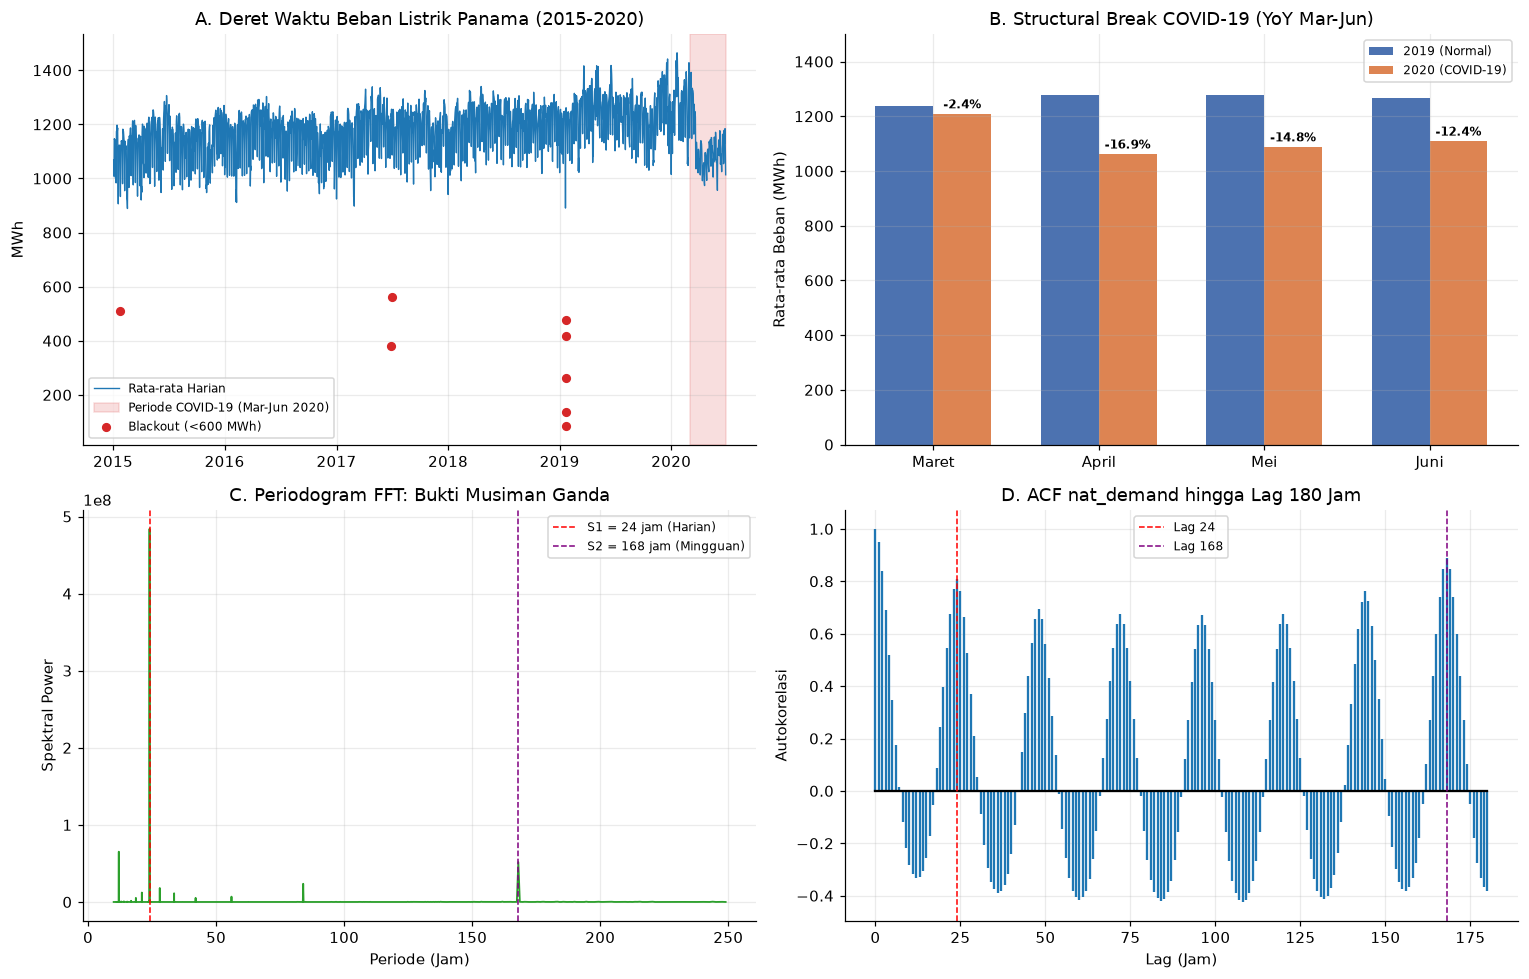

In [3]:
# 1. Uji Stasioneritas (ADF & KPSS) pada data pra-pandemi (2015-2019)
y_pre = df.loc[df["year"] <= 2019, "nat_demand"]

def run_stationarity_tests(series, name):
    adf_stat, adf_p, _, _, _, _ = adfuller(series.dropna(), maxlag=48, autolag="AIC")
    kpss_stat, kpss_p, _, _ = kpss(series.dropna(), regression="ct", nlags="auto")
    return {
        "Seri": name,
        "ADF_stat": round(adf_stat, 3),
        "ADF_p": round(adf_p, 4),
        "KPSS_stat": round(kpss_stat, 4),
        "KPSS_p": round(kpss_p, 4),
    }

stat_df = pd.DataFrame([
    run_stationarity_tests(y_pre, "Level Y_t (2015-2019)"),
    run_stationarity_tests(y_pre.diff(), "First Difference (1-B)Y_t"),
    run_stationarity_tests(y_pre.diff(24), "Seasonal Diff (1-B^24)Y_t"),
])
print("=== 1. Uji Stasioneritas ADF (H0: non-stasioner) & KPSS (H0: stasioner tren) ===")
display(stat_df)

# 2. Spektrum Frekuensi FFT untuk membuktikan Musiman Ganda (24h, 168h, tahunan)
y_centered = df["nat_demand"].values - df["nat_demand"].mean()
N_fft = len(y_centered)
yf = np.abs(rfft(y_centered)) ** 2 / N_fft
xf = rfftfreq(N_fft, d=1.0)  # siklus per jam
periods = np.where(xf > 0, 1.0 / xf, np.inf)
top_idx = np.argsort(yf)[::-1][:8]
print("\n=== 2. Puncak Spektrum Periodogram FFT (Periode dalam Jam) ===")
for idx in top_idx:
    if np.isfinite(periods[idx]):
        print(f"  Periode = {periods[idx]:8.2f} jam | Power = {yf[idx]:,.1f}")

# 3. Korelasi terhadap nat_demand & VIF 12 Variabel Cuaca 3 Kota
weather_cols = [
    "T2M_toc", "QV2M_toc", "TQL_toc", "W2M_toc",
    "T2M_san", "QV2M_san", "TQL_san", "W2M_san",
    "T2M_dav", "QV2M_dav", "TQL_dav", "W2M_dav",
]
corr_target = df[weather_cols + ["holiday", "Holiday_ID", "school", "nat_demand"]].corr()["nat_demand"].drop("nat_demand").sort_values(ascending=False)
corr_mat_w = df[weather_cols].corr().values
vifs = np.diag(np.linalg.inv(corr_mat_w))
vif_df = pd.DataFrame({"Variabel_Cuaca": weather_cols, "VIF": np.round(vifs, 2), "Corr_nat_demand": [round(corr_target[c], 4) for c in weather_cols]})
print("\n=== 3. Audit Multikolinearitas Spasial (VIF > 10 mengindikasikan kolinearitas tinggi) ===")
display(vif_df.sort_values("VIF", ascending=False))

# 4. Uji Heteroskedastisitas pada Regresi OLS Pendahuluan
X_ols = sm.add_constant(df[weather_cols + ["holiday", "school"]].astype(float))
ols_res = sm.OLS(df["nat_demand"], X_ols).fit()
bp_lm, bp_p, _, _ = het_breuschpagan(ols_res.resid, ols_res.model.exog)
arch_lm, arch_p, _, _ = het_arch(ols_res.resid, nlags=24)
print(f"\n=== 4. Uji Heteroskedastisitas Residual OLS Pendahuluan ===")
print(f"  Breusch-Pagan LM = {bp_lm:,.2f} (p = {bp_p:.4e})")
print(f"  Engle ARCH-LM(24) = {arch_lm:,.2f} (p = {arch_p:.4e})")
print(f"  Std hari biasa (holiday=0): {df.loc[df['holiday']==0, 'nat_demand'].std():.2f} MWh vs hari libur (holiday=1): {df.loc[df['holiday']==1, 'nat_demand'].std():.2f} MWh")

# Plot Diagnostik 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Panel A: Deret waktu lengkap + sorotan Blackout & COVID-19
daily = df.set_index("datetime")["nat_demand"].resample("D").mean()
axes[0, 0].plot(daily.index, daily.values, color="#1f77b4", lw=0.9, label="Rata-rata Harian")
axes[0, 0].axvspan(pd.Timestamp("2020-03-01"), df["datetime"].max(), color="#d62728", alpha=0.15, label="Periode COVID-19 (Mar-Jun 2020)")
bo = df[df["nat_demand"] < 600]
axes[0, 0].scatter(bo["datetime"], bo["nat_demand"], color="#d62728", s=25, zorder=5, label="Blackout (<600 MWh)")
axes[0, 0].set_title("A. Deret Waktu Beban Listrik Panama (2015-2020)")
axes[0, 0].set_ylabel("MWh")
axes[0, 0].legend(fontsize=8)

# Panel B: Perbandingan YoY Maret-Juni 2019 vs 2020
months = [3, 4, 5, 6]
x_pos = np.arange(len(months))
w = 0.35
axes[0, 1].bar(x_pos - w/2, mj_cmp["2019_MWh"], width=w, color="#4c72b0", label="2019 (Normal)")
axes[0, 1].bar(x_pos + w/2, mj_cmp["2020_MWh"], width=w, color="#dd8452", label="2020 (COVID-19)")
for i, pct in enumerate(mj_cmp["Perubahan_%"]):
    axes[0, 1].text(x_pos[i] + w/2, mj_cmp["2020_MWh"].iloc[i] + 20, f"{pct:+.1f}%", ha="center", fontsize=8, fontweight="bold")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(["Maret", "April", "Mei", "Juni"])
axes[0, 1].set_ylim(0, 1500)
axes[0, 1].set_title("B. Structural Break COVID-19 (YoY Mar-Jun)")
axes[0, 1].set_ylabel("Rata-rata Beban (MWh)")
axes[0, 1].legend(fontsize=8)

# Panel C: Periodogram FFT (Periode 12 - 250 jam)
mask_p = (periods >= 10) & (periods <= 250)
axes[1, 0].plot(periods[mask_p], yf[mask_p], color="#2ca02c", lw=1.2)
axes[1, 0].axvline(24, color="red", ls="--", lw=1, label="S1 = 24 jam (Harian)")
axes[1, 0].axvline(168, color="purple", ls="--", lw=1, label="S2 = 168 jam (Mingguan)")
axes[1, 0].set_title("C. Periodogram FFT: Bukti Musiman Ganda")
axes[1, 0].set_xlabel("Periode (Jam)")
axes[1, 0].set_ylabel("Spektral Power")
axes[1, 0].legend(fontsize=8)

# Panel D: ACF hingga Lag 180 jam
acf_vals = acf(df["nat_demand"], nlags=180, fft=True)
axes[1, 1].stem(np.arange(len(acf_vals)), acf_vals, linefmt="#1f77b4", markerfmt=" ", basefmt="k-")
axes[1, 1].axvline(24, color="red", ls="--", lw=1, label="Lag 24")
axes[1, 1].axvline(168, color="purple", ls="--", lw=1, label="Lag 168")
axes[1, 1].set_title("D. ACF nat_demand hingga Lag 180 Jam")
axes[1, 1].set_xlabel("Lag (Jam)")
axes[1, 1].set_ylabel("Autokorelasi")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 1.3 Skema Train–Test Split Kronologis (3 Rezim) & Penanganan *Blackout*

Karena data beban listrik per jam memiliki autokorelasi kuat antar-jam berdekatan (`t` dan `t+1`), pembagian acak (*random train-test split*) **dilarang** karena menimbulkan *data leakage* dan akurasi semu. Dataset dibagi secara **kronologis ketat** menjadi tiga rezim berikut:

| Rezim / Blok Data | Rentang Waktu | Jumlah Jam | Fungsi Metodologis |
| :--- | :--- | :---: | :--- |
| **1. Training Set (`2015–2018`)** | `2015-01-03 01:00` s.d. `2018-12-31 23:00` | `35.015` | Estimasi parameter seluruh model (*backtesting*) dan lokasi eksekusi **Cross-Validation Temporal (`TimeSeriesSplit` 3-fold)** untuk GAM & Gradient Boosting. |
| **2. Test Set 1: Rezim Normal (`2019`)** | `2019-01-01 00:00` s.d. `2019-12-31 23:00` | `8.760` | Evaluasi *out-of-sample* kondisi normal (1 tahun penuh), serta periode ***Placebo Test*** (`Maret–Juni 2019`) untuk validasi model kontrafaktual GAM. |
| **3. Test Set 2: Rezim Disrupsi (`2020`)** | `2020-01-01 00:00` s.d. `2020-06-27 00:00` | `4.273` | `Jan–Feb 2020` sebagai kontrol pra-lockdown; `Maret–Juni 2020` (`2.833` jam) menguji ketangguhan model saat *structural break* COVID-19 sekaligus objek estimasi dampak kausal. |

**Catatan Penyesuaian Jendela Latih Khusus per Model:**
- **`SARIMA` / `SARIMAX` (Tahap 2):** Di-fit dengan MLE Kalman Filter pada **6 minggu terakhir `2018` (`1.008` jam)** demi keterlaksanaan komputasi *state-space*, lalu dievaluasi *rolling weekly* (`h = 168` jam) di sepanjang `2019–2020` sebagai model dasar pembanding.
- **`HistGradientBoosting` / `LightGBM` Set B (Tahap 5):** Menggunakan `2015–2018`, namun `504` jam pertama otomatis dilewati karena pembentukan fitur `load_lag_504` (`34.511` baris latih efektif).
- **`GAM Counterfactual` (Tahap 4):** Khusus untuk proyeksi kontrafaktual `2020`, GAM di-refit pada seluruh periode pra-pandemi (`Jan 2015 – Feb 2020`).
- **Proyeksi Masa Depan (Tahap 8):** Model solusi dilatih ulang hingga titik observasi terakhir (`2020-06-27 00:00`) untuk memproyeksikan **7 hari ke depan (Jangka Pendek)** dan **12 bulan ke depan (Jangka Panjang)**.

**Penanganan 8 Titik *Blackout* (`nat_demand < 600` MWh):**
- **3 titik di blok latih (`2015–2018`):** Diimputasi di kolom `nat_demand_clean` agar estimasi varians dan fitur *lag* tidak terdistorsi.
- **5 titik di blok uji `2019` (`2019-01-20 12:00–16:00`):** Dibiarkan utuh pada target uji, dan seluruh metrik `2019` dilaporkan **dengan dan tanpa *blackout*** (`2019 All` vs `2019 No Blackout`).

#### Penjelasan Algoritma Matematis (Tahap 1.3)
1. **Partisi Kronologis Anti-Kebocoran:** Memisahkan himpunan indeks waktu secara terurut tegas:
   $$\mathcal{I}_{\text{train}} = \{t : t \le T_1\}, \qquad \mathcal{I}_{\text{test19}} = \{t : T_1 < t \le T_2\}, \qquad \mathcal{I}_{\text{test20}} = \{t : t > T_2\}$$
   dengan batas $T_1 =$ `2018-12-31 23:00` dan $T_2 =$ `2019-12-31 23:00`.
2. **Imputasi Musiman Mingguan Terbatas pada Blok Latih:** Untuk setiap titik anomali pada data latih $\mathcal{B}_{\text{train}} = \{t \in \mathcal{I}_{\text{train}} : Y_t < 600\}$, nilai target bersih didefinisikan sebagai rata-rata beban pada hari dan jam yang sama satu minggu sebelum dan sesudahnya:
   $$\tilde{Y}_t = \frac{Y_{t-168} + Y_{t+168}}{2}$$
   sehingga titik uji `2019` tidak pernah dipakai mengimputasi dirinya sendiri saat pengujian.

#### Penjelasan Algoritma Kode (Sel 6)
1. Membuat kolom indikator biner `is_blackout` (`nat_demand < 600`) dan salinan target `nat_demand_clean`.
2. Membentuk empat *boolean mask* kronologis (`train_mask`, `test_2019_mask`, `test_2020_mask`, dan `lockdown_2020_mask` mulai `2020-03-01`).
3. Menelusuri indeks *blackout* `bo_indices`; hanya baris dengan `datetime <= train_end_dt` yang diperbarui memakai `np.nanmean([Y_{idx-168}, Y_{idx+168}])`.
4. Menyusun dan menampilkan tabel `split_summary_df` berisi rentang waktu, jumlah jam, proporsi, jumlah *blackout*, dan fungsi tiap blok.

In [4]:
# Penanganan Blackout & Pembagian Kronologis 3 Rezim
df["is_blackout"] = (df["nat_demand"] < 600).astype(int)
df["nat_demand_clean"] = df["nat_demand"].copy()

# Masking & Imputasi Musiman hanya di area sebelum test (atau seri historis agar lag test tidak tercemar spike 85 MWh)
# Pada data latih (2015-2018), imputasi memakai rata-rata minggu sebelum & sesudah pada jam/hari yang sama: (Y_{t-168} + Y_{t+168})/2
train_end_dt = pd.Timestamp("2018-12-31 23:00:00")
test_norm_end_dt = pd.Timestamp("2019-12-31 23:00:00")
covid_start_dt = pd.Timestamp("2020-03-01 00:00:00")

train_mask = df["datetime"] <= train_end_dt
test_2019_mask = (df["datetime"] > train_end_dt) & (df["datetime"] <= test_norm_end_dt)
test_2020_mask = df["datetime"] > test_norm_end_dt
lockdown_2020_mask = df["datetime"] >= covid_start_dt

# Imputasi titik blackout pada training (dan seri referensi lag historis)
bo_indices = df.index[df["is_blackout"] == 1].tolist()
for idx in bo_indices:
    if df.loc[idx, "datetime"] <= train_end_dt:
        prev_val = df.loc[idx - 168, "nat_demand"] if idx - 168 >= 0 else np.nan
        next_val = df.loc[idx + 168, "nat_demand"] if idx + 168 < len(df) else np.nan
        df.loc[idx, "nat_demand_clean"] = np.nanmean([prev_val, next_val])

split_summary_df = pd.DataFrame([
    {
        "Rezim": "1. Training (2015-2018)",
        "Rentang_Waktu": f"{df.loc[train_mask, 'datetime'].min()} s.d. {df.loc[train_mask, 'datetime'].max()}",
        "Jumlah_Jam": int(train_mask.sum()),
        "Proporsi_%": round(train_mask.mean() * 100.0, 2),
        "Titik_Blackout": int((train_mask & (df["is_blackout"] == 1)).sum()),
        "Fungsi": "Estimasi parameter model & CV TimeSeriesSplit (3-fold)",
    },
    {
        "Rezim": "2. Test Normal (2019)",
        "Rentang_Waktu": f"{df.loc[test_2019_mask, 'datetime'].min()} s.d. {df.loc[test_2019_mask, 'datetime'].max()}",
        "Jumlah_Jam": int(test_2019_mask.sum()),
        "Proporsi_%": round(test_2019_mask.mean() * 100.0, 2),
        "Titik_Blackout": int((test_2019_mask & (df["is_blackout"] == 1)).sum()),
        "Fungsi": "Evaluasi normal 1 tahun (All & No Blackout) + Placebo Mar-Jun 2019",
    },
    {
        "Rezim": "3a. Test 2020 (All: Jan-Jun)",
        "Rentang_Waktu": f"{df.loc[test_2020_mask, 'datetime'].min()} s.d. {df.loc[test_2020_mask, 'datetime'].max()}",
        "Jumlah_Jam": int(test_2020_mask.sum()),
        "Proporsi_%": round(test_2020_mask.mean() * 100.0, 2),
        "Titik_Blackout": int((test_2020_mask & (df["is_blackout"] == 1)).sum()),
        "Fungsi": "Kontrol Jan-Feb 2020 + uji disrupsi COVID-19",
    },
    {
        "Rezim": "3b. Test 2020 (Lockdown: Mar-Jun)",
        "Rentang_Waktu": f"{df.loc[lockdown_2020_mask, 'datetime'].min()} s.d. {df.loc[lockdown_2020_mask, 'datetime'].max()}",
        "Jumlah_Jam": int(lockdown_2020_mask.sum()),
        "Proporsi_%": round(lockdown_2020_mask.mean() * 100.0, 2),
        "Titik_Blackout": int((lockdown_2020_mask & (df["is_blackout"] == 1)).sum()),
        "Fungsi": "Evaluasi ketangguhan STLF & dampak kausal lockdown",
    },
])
print("=== Ringkasan Pembagian Data Kronologis (Tanpa Random Split) ===")
display(split_summary_df)
print(f"Titik blackout diimputasi pada train: {(train_mask & (df['is_blackout']==1)).sum()} titik")
print(f"Titik blackout di test 2019        : {(test_2019_mask & (df['is_blackout']==1)).sum()} titik (dievaluasi dengan & tanpa blackout)")

=== Ringkasan Pembagian Data Kronologis (Tanpa Random Split) ===


,Rezim,Rentang_Waktu,Jumlah_Jam,Proporsi_%,Titik_Blackout,Fungsi
0,1. Training (2015-2018),2015-01-03 01:00:00 s.d. 2018-12-31 23:00:00,35015,72.88,3,Estimasi parameter model & CV TimeSeriesSplit ...
1,2. Test Normal (2019),2019-01-01 00:00:00 s.d. 2019-12-31 23:00:00,8760,18.23,5,Evaluasi normal 1 tahun (All & No Blackout) + ...
2,3a. Test 2020 (All: Jan-Jun),2020-01-01 00:00:00 s.d. 2020-06-27 00:00:00,4273,8.89,0,Kontrol Jan-Feb 2020 + uji disrupsi COVID-19
3,3b. Test 2020 (Lockdown: Mar-Jun),2020-03-01 00:00:00 s.d. 2020-06-27 00:00:00,2833,5.90,0,Evaluasi ketangguhan STLF & dampak kausal lock...


Titik blackout diimputasi pada train: 3 titik
Titik blackout di test 2019        : 5 titik (dievaluasi dengan & tanpa blackout)


---
## Tahap 2: Model Dasar (`Seasonal Naive`, `SARIMA`, `SARIMAX`), Evaluasi Jangka Pendek ($h = 168$ Jam), & Pembuktian Ketidakmemadaian

Tahap ini mendudukkan **`Seasonal Naive`** ($\hat{Y}_t = Y_{t-168}$), **`SARIMA`**, dan **`SARIMAX`** ($S = 24$ jam) sebagai tolok ukur klasik peramalan jangka pendek (*Short-Term Load Forecasting*, $h = 168$ jam), sekaligus membuktikan secara teoretis dan diagnostik empiris keterbatasan pendekatan linear/musiman-tunggal sebelum membandingkannya dengan model solusi di Tahap 7.

### Penjelasan Algoritma Matematis (Tahap 2)
1. **Baseline *Seasonal Naive* Mingguan:**
   $$\hat{Y}_t^{(\text{Naive})} = Y_{t-168}$$
   Memanfaatkan siklus mingguan dominan ($168$ jam = 7 hari) sebagai patokan minimum tanpa pemodelan parameter maupun kovariat cuaca.
2. **Formulasi Multiplikatif `SARIMA(1,0,1)(1,1,0)`$_{24}$ & `SARIMAX`:**
   Dengan operator *backshift* $B^k Y_t = Y_{t-k}$, model univariat didefinisikan sebagai:
   $$\Phi_1(B^{24})\,\phi_1(B)\,(1 - B^{24}) Y_t = \theta_1(B)\,\varepsilon_t, \qquad \varepsilon_t \overset{\text{i.i.d.}}{\sim} \mathcal{N}(0, \sigma^2)$$
   dan perluasan regresi linear kovariat cuaca–kalender (**SARIMAX**) terstandardisasi $z_{t,j} = (X_{t,j}-\mu_j)/\sigma_j$:
   $$Y_t = \mathbf{z}_t^\top \boldsymbol{\beta} + \eta_t, \qquad \eta_t \sim \text{SARIMA}(1,0,1)(1,1,0)_{24}$$
   Parameter $(\phi_1, \theta_1, \Phi_1, \boldsymbol{\beta}, \sigma^2)$ diestimasi dengan *Maximum Likelihood Estimation* (MLE) melalui representasi *state-space* Kalman Filter pada **6 minggu terakhir `2018` (`1.008` jam)**, lalu diuji secara *rolling weekly forecast* (*walk-forward* per `168` jam) di sepanjang `2019` dan `Jan–Jun 2020`.
3. **Audit Diagnostik Pelanggaran Asumsi Klasik:**
   - **Uji Ljung-Box (*Portmanteau*):** Menguji hipotesis nol *white noise* pada residual/galat hingga lag $h \in \{24, 48, 168\}$:
     $$Q(h) = n(n+2)\sum_{k=1}^{h} \frac{\hat{\rho}_e^2(k)}{n - k} \sim \chi^2_{h - p - q - P - Q}$$
     Nilai $p < 0{,}05$ pada lag `168` membuktikan kebocoran musiman mingguan yang gagal diserap oleh $S=24$.
   - **Uji Normalitas Jarque-Bera:** $\text{JB} = \frac{n}{6}\left(S_{\text{skew}}^2 + \frac{(K_{\text{kurt}}-3)^2}{4}\right)$ menguji apakah ekor residual simetris/Gaussian ($p < 0{,}05$ menunjukkan *heavy-tail* akibat *blackout* dan non-linearitas).
   - **Uji Heteroskedastisitas ARCH-LM(24):** Menguji autokorelasi kuadrat residual $\hat{e}_t^2$ ($p < 0{,}05$ menolak asumsi varians konstan $\sigma^2$).

### Penjelasan Algoritma Kode (Sel 8 & Sel 9)
- **Sel 8 (Fungsi Evaluasi, Model Dasar `Seasonal Naive` / `SARIMA` / `SARIMAX`, & Ringkasan Awal):**
  1. Mendefinisikan fungsi utilitas evaluasi global: `compute_metrics()` (MAE, RMSE, MAPE, sMAPE), `pinball_loss()`, `winkler_score()`, dan `diebold_mariano_test()` (dengan estimator varians jangka panjang Newey-West HAC kernel Bartlett).
  2. Menghitung baseline `df["pred_naive"] = df["nat_demand"].shift(168)`.
  3. Menstandardisasi 5 kovariat `sarimax_cols` dengan `StandardScaler()` khusus pada 6 minggu terakhir `2018` (`sarima_win = 1008` jam), lalu mem-fit `SARIMAX` tanpa eksogen (`res_sarima`) dan dengan eksogen (`res_sarimax`).
  4. Fungsi `rolling_weekly_sarima_forecast()` menggeser jendela 1.008 jam tiap 168 langkah sepanjang `2019–2020`, memperbarui *state* via `base_res.apply()`, mengambil prakiraan 168 jam ke depan ke `df["pred_sarima"]` dan `df["pred_sarimax"]`, lalu menampilkan tabel ringkasan metrik awal `rows_base` (2019 All, 2019 No Blackout, dan Mar–Jun 2020).
- **Sel 9 (Uji Diagnostik Empiris Ketidakmemadaian):**
  1. Menjalankan `acorr_ljungbox`, `stats.jarque_bera`, dan `het_arch` baik pada residual latih maupun galat uji `2019` (`mask_2019_clean`) milik `SARIMA` dan `SARIMAX`.
  2. Menghitung *error breakdown* pada hari biasa (`holiday=0`) vs hari libur (`holiday=1`) untuk memperlihatkan lonjakan error saat kalender libur.
  3. Memplot 3 panel bukti empiris: lonjakan ACF error di lag `168`, *over-forecast* persisten saat lockdown `April 2020`, dan profil RMSE per jam (`0–23`).

In [5]:
# Helper Metrik Evaluasi & Uji Diebold-Mariano (Newey-West HAC)
def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    mape = np.mean(np.abs(err / y_true)) * 100.0
    smape = np.mean(2.0 * np.abs(err) / (np.abs(y_true) + np.abs(y_pred))) * 100.0
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "sMAPE": smape}


def pinball_loss(y_true, y_pred, q):
    e = np.asarray(y_true) - np.asarray(y_pred)
    return np.mean(np.maximum(q * e, (q - 1.0) * e))


def winkler_score(y_true, lower, upper, alpha=0.10):
    y = np.asarray(y_true)
    l = np.asarray(lower)
    u = np.asarray(upper)
    width = u - l
    penalty = np.where(y < l, (2.0 / alpha) * (l - y), np.where(y > u, (2.0 / alpha) * (y - u), 0.0))
    return np.mean(width + penalty)


def diebold_mariano_test(y_true, pred_a, pred_b, h=168, loss_type="squared"):
    e_a = np.asarray(y_true, dtype=float) - np.asarray(pred_a, dtype=float)
    e_b = np.asarray(y_true, dtype=float) - np.asarray(pred_b, dtype=float)
    if loss_type == "squared":
        d = e_a ** 2 - e_b ** 2
    else:
        d = np.abs(e_a) - np.abs(e_b)
    T = len(d)
    d_bar = np.mean(d)
    dc = d - d_bar
    # Estimator varians jangka panjang Newey-West (Bartlett kernel, dijamin > 0)
    K = min(h - 1, T - 1)
    gamma0 = np.dot(dc, dc) / T
    hac = gamma0
    for k in range(1, K + 1):
        wk = 1.0 - k / (K + 1.0)
        gamma_k = np.dot(dc[k:], dc[:-k]) / T
        hac += 2.0 * wk * gamma_k
    if hac <= 0:
        hac = gamma0
    dm_stat = d_bar / np.sqrt(hac / T)
    p_val = 2.0 * (1.0 - stats.norm.cdf(abs(dm_stat)))
    return dm_stat, p_val, d_bar


# 1. Baseline 0: Seasonal Naive (Y_{t-168})
df["pred_naive"] = df["nat_demand"].shift(168)

# 2. SARIMA(1,0,1)(1,1,0)_24 & SARIMAX(1,0,1)(1,1,0)_24 dengan eksogen terstandardisasi
# Menggunakan 6 minggu terakhir 2018 (1.008 jam) untuk MLE lalu sliding Kalman filter apply per 168 jam
sarima_win = 1008
sarima_train_df = df.loc[train_mask].iloc[-sarima_win:].copy()
sarimax_cols = ["T2M_toc", "QV2M_toc", "W2M_toc", "holiday", "school"]

scaler_sx = StandardScaler()
exog_train_sx = pd.DataFrame(
    scaler_sx.fit_transform(sarima_train_df[sarimax_cols]),
    index=sarima_train_df.index,
    columns=sarimax_cols,
)

t0 = time.time()
y_sx_train = sarima_train_df["nat_demand_clean"].rename("nat_demand")
mod_sarima = SARIMAX(
    y_sx_train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 0, 24),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
res_sarima = mod_sarima.fit(disp=False, maxiter=80)

mod_sarimax = SARIMAX(
    y_sx_train,
    exog=exog_train_sx,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 0, 24),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
res_sarimax = mod_sarimax.fit(disp=False, maxiter=80)
print(f"SARIMA & SARIMAX selesai di-fit dalam {time.time()-t0:.2f} detik.")
print(f"AIC SARIMA: {res_sarima.aic:,.1f} | AIC SARIMAX: {res_sarimax.aic:,.1f}")

# Rolling Weekly 168h-Ahead Forecast mulai 2019-01-01 s.d. akhir dataset (sliding window apply)
def rolling_weekly_sarima_forecast(base_res, full_df, start_pos, exog_df=None, horizon=168, window=1008):
    preds = pd.Series(index=full_df.index[start_pos:], dtype=float)
    pos = start_pos
    while pos < len(full_df):
        end_pos = min(pos + horizon, len(full_df))
        steps = end_pos - pos
        y_win = full_df["nat_demand"].iloc[pos - window : pos]
        if exog_df is None:
            cur_res = base_res.apply(y_win)
            fc = cur_res.get_forecast(steps=steps).predicted_mean
        else:
            ex_win = exog_df.iloc[pos - window : pos]
            ex_fc = exog_df.iloc[pos:end_pos]
            cur_res = base_res.apply(y_win, exog=ex_win)
            fc = cur_res.get_forecast(steps=steps, exog=ex_fc).predicted_mean
        preds.iloc[pos - start_pos : end_pos - start_pos] = fc.values
        pos = end_pos
    return preds

exog_all_sx = pd.DataFrame(
    scaler_sx.transform(df[sarimax_cols]),
    index=df.index,
    columns=sarimax_cols,
)
start_2019_pos = int(df.index[test_2019_mask][0])

t1 = time.time()
df.loc[start_2019_pos:, "pred_sarima"] = rolling_weekly_sarima_forecast(res_sarima, df, start_2019_pos, exog_df=None)
df.loc[start_2019_pos:, "pred_sarimax"] = rolling_weekly_sarima_forecast(res_sarimax, df, start_2019_pos, exog_df=exog_all_sx)
print(f"Rolling 168h forecast (2019-2020) selesai dalam {time.time()-t1:.2f} detik.")

# Ringkasan Awal Performa Model Dasar
mask_2019_clean = test_2019_mask & (df["is_blackout"] == 0)
rows_base = []
for name, col in [
    ("Seasonal Naive (t-168)", "pred_naive"),
    ("SARIMA(1,0,1)(1,1,0)_24", "pred_sarima"),
    ("SARIMAX (Linear Covariates)", "pred_sarimax"),
]:
    m_all = compute_metrics(df.loc[test_2019_mask, "nat_demand"], df.loc[test_2019_mask, col])
    m_cln = compute_metrics(df.loc[mask_2019_clean, "nat_demand"], df.loc[mask_2019_clean, col])
    m_cov = compute_metrics(df.loc[lockdown_2020_mask, "nat_demand"], df.loc[lockdown_2020_mask, col])
    rows_base.append({
        "Model": name,
        "RMSE_2019_All": round(m_all["RMSE"], 2),
        "MAPE_2019_All_%": round(m_all["MAPE"], 2),
        "RMSE_2019_NoBlackout": round(m_cln["RMSE"], 2),
        "MAPE_2019_NoBlackout_%": round(m_cln["MAPE"], 2),
        "RMSE_MarJun2020": round(m_cov["RMSE"], 2),
        "MAPE_MarJun2020_%": round(m_cov["MAPE"], 2),
    })
display(pd.DataFrame(rows_base))

SARIMA & SARIMAX selesai di-fit dalam 27.56 detik.
AIC SARIMA: 8,846.6 | AIC SARIMAX: 8,846.6
Rolling 168h forecast (2019-2020) selesai dalam 45.46 detik.


,Model,RMSE_2019_All,MAPE_2019_All_%,RMSE_2019_NoBlackout,MAPE_2019_NoBlackout_%,RMSE_MarJun2020,MAPE_MarJun2020_%
0,Seasonal Naive (t-168),100.19,5.73,97.94,5.43,88.15,5.63
1,"SARIMA(1,0,1)(1,1,0)_24",123.52,7.19,120.38,6.80,90.31,5.87
2,SARIMAX (Linear Covariates),119.90,6.95,116.75,6.57,85.70,5.58


=== Bukti Diagnostik Empiris: Pelanggaran White Noise, Normalitas, & Homoskedastisitas ===


,Sumber Residual,LjungBox_p(lag24),LjungBox_p(lag168),JarqueBera_p,ARCH_LM_p
0,SARIMA (Train Resid),2.52e-37,1.70e-19,0.00e+00,5.56e-142
1,SARIMAX (Train Resid),7.79e-34,1.36e-17,0.00e+00,1.61e-141
2,SARIMA (Test 2019 Error),0.00e+00,0.00e+00,0.00e+00,0.00e+00
3,SARIMAX (Test 2019 Error),0.00e+00,0.00e+00,0.00e+00,0.00e+00



=== Error Breakdown SARIMAX 2019: Hari Biasa vs Hari Libur ===


,MAE,RMSE,MAPE,sMAPE
Hari Biasa (holiday=0),80.24,113.37,6.29,6.31
Hari Libur (holiday=1),119.85,158.74,10.68,9.88


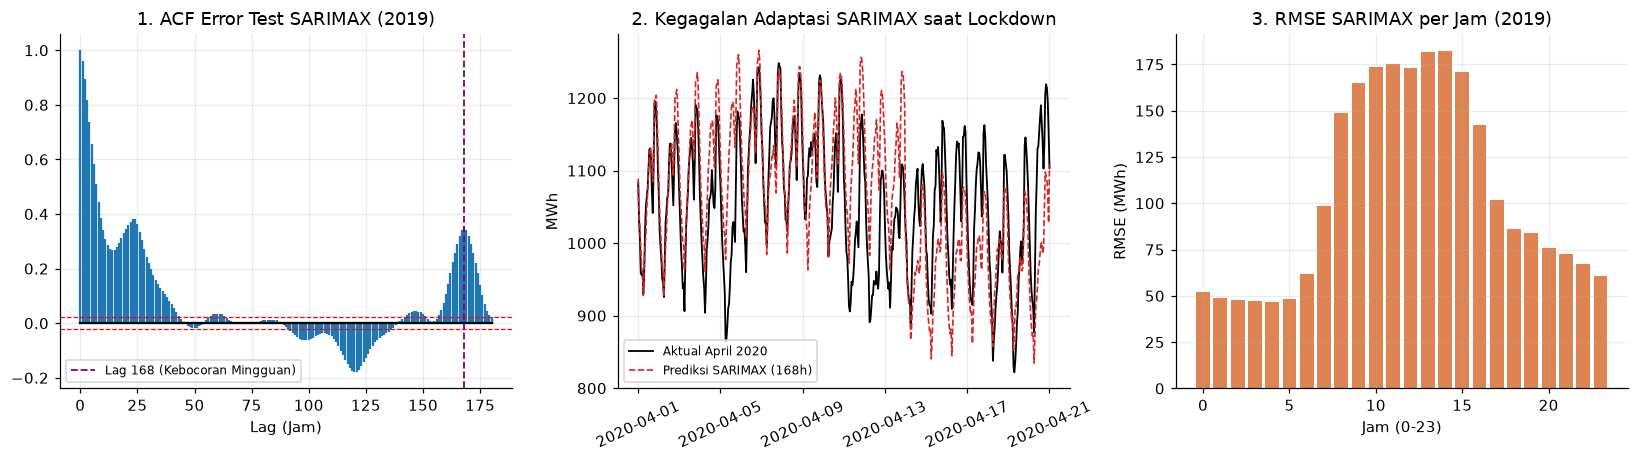

In [6]:
# Pembuktian Empiris Ketidakmemadaian SARIMA & SARIMAX
diag_rows = []
for name, res_obj, pred_col in [
    ("SARIMA (Train Resid)", res_sarima, None),
    ("SARIMAX (Train Resid)", res_sarimax, None),
    ("SARIMA (Test 2019 Error)", None, "pred_sarima"),
    ("SARIMAX (Test 2019 Error)", None, "pred_sarimax"),
]:
    if res_obj is not None:
        r = res_obj.resid.iloc[24:].values
    else:
        r = (df.loc[mask_2019_clean, "nat_demand"] - df.loc[mask_2019_clean, pred_col]).values
    lb = acorr_ljungbox(r, lags=[24, 48, 168], return_df=True)
    jb_stat, jb_p = stats.jarque_bera(r)
    arch_stat, arch_p, _, _ = het_arch(r, nlags=24)
    diag_rows.append({
        "Sumber Residual": name,
        "LjungBox_p(lag24)": f"{lb.loc[24, 'lb_pvalue']:.2e}",
        "LjungBox_p(lag168)": f"{lb.loc[168, 'lb_pvalue']:.2e}",
        "JarqueBera_p": f"{jb_p:.2e}",
        "ARCH_LM_p": f"{arch_p:.2e}",
    })

print("=== Bukti Diagnostik Empiris: Pelanggaran White Noise, Normalitas, & Homoskedastisitas ===")
display(pd.DataFrame(diag_rows))

# Error Breakdown: Hari Biasa vs Hari Libur (Test 2019 tanpa blackout)
df["err_sarimax"] = df["nat_demand"] - df["pred_sarimax"]
sub19 = df.loc[mask_2019_clean].copy()
sub19["hour"] = sub19["datetime"].dt.hour
hol_err = sub19.groupby("holiday").apply(
    lambda g: pd.Series(compute_metrics(g["nat_demand"], g["pred_sarimax"])), include_groups=False
).round(2)
hol_err.index = ["Hari Biasa (holiday=0)", "Hari Libur (holiday=1)"]
print("\n=== Error Breakdown SARIMAX 2019: Hari Biasa vs Hari Libur ===")
display(hol_err)

# Plot 3 Panel Bukti Ketidakmemadaian
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Panel 1: ACF Error Test SARIMAX 2019 (menunjukkan lonjakan di lag 168)
err_19 = (df.loc[test_2019_mask, "nat_demand"] - df.loc[test_2019_mask, "pred_sarimax"]).values
acf_err = acf(err_19, nlags=180, fft=True)
conf = 1.96 / np.sqrt(len(err_19))
axes[0].stem(np.arange(len(acf_err)), acf_err, linefmt="#1f77b4", markerfmt=" ", basefmt="k-")
axes[0].axhline(conf, color="red", ls="--", lw=0.8)
axes[0].axhline(-conf, color="red", ls="--", lw=0.8)
axes[0].axvline(168, color="purple", ls="--", lw=1.2, label="Lag 168 (Kebocoran Mingguan)")
axes[0].set_title("1. ACF Error Test SARIMAX (2019)")
axes[0].set_xlabel("Lag (Jam)")
axes[0].legend(fontsize=8)

# Panel 2: Over-forecast sistematis pada April 2020 (Structural Break)
apr20 = df[(df["datetime"] >= "2020-04-01") & (df["datetime"] <= "2020-04-21")]
axes[1].plot(apr20["datetime"], apr20["nat_demand"], label="Aktual April 2020", color="black", lw=1.2)
axes[1].plot(apr20["datetime"], apr20["pred_sarimax"], label="Prediksi SARIMAX (168h)", color="#d62728", ls="--", lw=1.1)
axes[1].set_title("2. Kegagalan Adaptasi SARIMAX saat Lockdown")
axes[1].set_ylabel("MWh")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(fontsize=8)

# Panel 3: RMSE berdasarkan jam dalam sehari (2019)
hourly_rmse = sub19.groupby("hour").apply(lambda g: np.sqrt(np.mean(g["err_sarimax"] ** 2)), include_groups=False)
axes[2].bar(hourly_rmse.index, hourly_rmse.values, color="#dd8452")
axes[2].set_title("3. RMSE SARIMAX per Jam (2019)")
axes[2].set_xlabel("Jam (0-23)")
axes[2].set_ylabel("RMSE (MWh)")

plt.tight_layout()
plt.show()

---
## Tahap 3: Rekayasa Fitur Terpisah (Set A Eksogen Murni vs Set B Prediktif Penuh)

Untuk menjamin tidak ada *data leakage* dan menghindari kontaminasi *counterfactual*, fitur dibagi menjadi dua set:
- **Set A (Eksogen Murni):** Tren makro, fitur waktu siklikal, `holiday`, kategori `Holiday_ID` (`0–22`), `school`, `pre/post_holiday`, komponen utama suhu 3 kota (`T2M_pca1` yang di-fit hanya pada data latih), serta *lag* suhu `1–3` jam. **Tanpa *lag* `nat_demand`.**
- **Set B (Prediktif Penuh, $h = 168$ jam):** Seluruh fitur cuaca 3 kota (`12` variabel), fitur waktu & kalender, ditambah *lag* beban historis (`t-168`, `t-336`, `t-504`) dan statistik bergerak yang digeser minimal 168 jam.

### Penjelasan Algoritma Matematis (Tahap 3)
1. **Transformasi Siklikal Fourier:** Mengatasi diskontinuitas batas jam (`23` ke `0`), hari (`6` ke `0`), dan hari dalam tahun (`365` ke `1`) lewat proyeksi lingkaran satuan:
   $$\sin\!\left(\frac{2\pi x}{P}\right), \qquad \cos\!\left(\frac{2\pi x}{P}\right), \qquad P \in \{24,\; 7,\; 365{,}25\}$$
2. **Reduksi Multikolinearitas Spasial dengan PCA Suhu (Fit Khusus Blok Latih):**
   Ketiga suhu kota $\mathbf{T}_t = [T2M_{\text{toc}},\, T2M_{\text{san}},\, T2M_{\text{dav}}]^\top$ distandardisasi terhadap statistik latih ($\boldsymbol{\mu}_{\text{train}}, \boldsymbol{\sigma}_{\text{train}}$), lalu diproyeksikan ke vektor eigen utama pertama $\mathbf{v}_1$:
   $$\mathbf{z}_t = \mathbf{D}_\sigma^{-1}(\mathbf{T}_t - \boldsymbol{\mu}_{\text{train}}), \qquad \text{T2M\_pca1}_t = s \cdot \mathbf{z}_t^\top \mathbf{v}_1, \qquad s \in \{-1, +1\}$$
   Faktor tanda $s$ diselaraskan positif terhadap $T2M_{\text{toc}}$ dan disimpan (`pca_t2m_sign`) agar proyeksi Tahap 8 konsisten.
3. **Inersia Termal, Interaksi, & Pengodean Libur:**
   - Menambahkan rata-rata bergerak suhu 24 jam $\overline{T2M}_{24\text{h}}(t) = \frac{1}{24}\sum_{k=0}^{23} T2M_{t-k}$ serta fitur interaksi `T2M_pca1 × cos_hour` dan `T2M_pca1 × sin_hour`.
   - Mengodekan 22 kategori hari libur spesifik (`Holiday_ID` $1\dots 22$) menjadi variabel *dummy* biner terhadap *baseline* hari biasa (`Holiday_ID = 0`), ditambah efek jembatan `pre_holiday` ($H-1$) dan `post_holiday` ($H+1$).
4. **Disiplin *Lag* Autoregresif Set B ($h = 168$ jam):**
   Karena horizon operasional adalah 1 minggu penuh, seluruh fitur beban historis dihitung dari target latih bersih (`nat_demand_clean`) yang digeser minimal $168$ jam ke belakang:
   $$Y_{t-168},\; Y_{t-336},\; Y_{t-504},\; \mu_{168\text{h}}(t-168),\; \sigma_{168\text{h}}(t-168),\; \max_{24\text{h}}(t-168)$$

### Penjelasan Algoritma Kode (Sel 11)
1. Menghitung `time_index_years` sekuensial (`np.arange(len(df)) / 8760.0`), atribut kalender (`hour`, `day_of_week`, `is_weekend`, `day_of_year`), serta enam kolom trigonometri siklikal.
2. Mengagregasi status `holiday` per tanggal dan menggeser `±1` hari untuk mengisi indikator `pre_holiday` dan `post_holiday`.
3. Melakukan `fit_transform` `StandardScaler()` dan `PCA(n_components=1)` khusus pada `df.loc[train_mask, t2m_cols]`, menyimpan arah tanda ke `pca_t2m_sign`, lalu mentransformasi seluruh dataset.
4. Membentuk *lag* suhu `1–3` jam (`.shift(lag).bfill()`), `T2M_toc_roll24`, matriks dummy `pd.get_dummies(df["Holiday_ID"], prefix="HolID", drop_first=True)`, fitur lag Set B berbasis `nat_demand_clean`, dan menyusun daftar 39 fitur `set_b_features`.

In [7]:
# Ekstraksi Fitur Waktu & Kalender
df["time_index_years"] = np.arange(len(df), dtype=float) / 8760.0
df["hour"] = df["datetime"].dt.hour.astype(float)
df["day_of_week"] = df["datetime"].dt.dayofweek.astype(float)
df["is_weekend"] = (df["day_of_week"] >= 5).astype(float)
df["day_of_year"] = df["datetime"].dt.dayofyear.astype(float)

# Fitur Siklikal (sin/cos)
df["sin_hour"] = np.sin(2 * np.pi * df["hour"] / 24.0)
df["cos_hour"] = np.cos(2 * np.pi * df["hour"] / 24.0)
df["sin_dow"] = np.sin(2 * np.pi * df["day_of_week"] / 7.0)
df["cos_dow"] = np.cos(2 * np.pi * df["day_of_week"] / 7.0)
df["sin_doy"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["cos_doy"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

# Efek H-1 dan H+1 hari libur (bridge day)
daily_hol = df.groupby(df["datetime"].dt.date)["holiday"].max()
pre_dates = set(pd.Series(daily_hol.index)[daily_hol.shift(-1, fill_value=0).values == 1])
post_dates = set(pd.Series(daily_hol.index)[daily_hol.shift(1, fill_value=0).values == 1])
df["pre_holiday"] = df["datetime"].dt.date.isin(pre_dates).astype(float)
df["post_holiday"] = df["datetime"].dt.date.isin(post_dates).astype(float)

# PCA Suhu 3 Kota (fit HANYA pada training 2015-2018 agar bebas leakage)
t2m_cols = ["T2M_toc", "T2M_san", "T2M_dav"]
scaler_t2m = StandardScaler()
pca_t2m = PCA(n_components=1)
t2m_train_scaled = scaler_t2m.fit_transform(df.loc[train_mask, t2m_cols])
pca_t2m.fit(t2m_train_scaled)
df["T2M_pca1"] = pca_t2m.transform(scaler_t2m.transform(df[t2m_cols])).ravel()
# Pastikan arah tanda T2M_pca1 positif terhadap T2M_toc dan simpan konvensi tanda untuk proyeksi Tahap 8
pca_t2m_sign = -1.0 if np.corrcoef(df.loc[train_mask, "T2M_pca1"], df.loc[train_mask, "T2M_toc"])[0, 1] < 0 else 1.0
df["T2M_pca1"] *= pca_t2m_sign
print(f"PCA Suhu 3 Kota -> Varians dijelaskan komponen pertama (T2M_pca1): {pca_t2m.explained_variance_ratio_[0]*100:.2f}%")

# Lag Suhu & Moving Average 24h (Thermal Inertia)
for lag in [1, 2, 3]:
    df[f"T2M_toc_lag{lag}"] = df["T2M_toc"].shift(lag).bfill()
df["T2M_toc_roll24"] = df["T2M_toc"].rolling(24, min_periods=1).mean()
df["T2M_pca1_x_cos_hour"] = df["T2M_pca1"] * df["cos_hour"]
df["T2M_pca1_x_sin_hour"] = df["T2M_pca1"] * df["sin_hour"]

# Dummy Holiday_ID (0 = baseline bukan libur; 1..22 kategori)
hol_dummies = pd.get_dummies(df["Holiday_ID"], prefix="HolID", drop_first=True, dtype=float)
hol_dummy_cols = list(hol_dummies.columns)
df = pd.concat([df, hol_dummies], axis=1)

# Set B Tambahan: Autoregressive Lag Beban untuk Horizon h = 168 jam
# Menggunakan nat_demand_clean hingga akhir 2018, lalu nilai riil historis >= 168 jam ke belakang
df["load_lag_168"] = df["nat_demand_clean"].shift(168)
df["load_lag_336"] = df["nat_demand_clean"].shift(336)
df["load_lag_504"] = df["nat_demand_clean"].shift(504)
df["load_roll168_mean"] = df["nat_demand_clean"].shift(168).rolling(168, min_periods=24).mean()
df["load_roll168_std"] = df["nat_demand_clean"].shift(168).rolling(168, min_periods=24).std()
df["load_roll24_max_lag168"] = df["nat_demand_clean"].shift(168).rolling(24, min_periods=1).max()

set_b_features = (
    weather_cols
    + ["T2M_pca1", "T2M_toc_lag1", "T2M_toc_lag2", "T2M_toc_lag3", "T2M_toc_roll24"]
    + ["time_index_years", "hour", "day_of_week", "is_weekend", "day_of_year",
       "sin_hour", "cos_hour", "sin_dow", "cos_dow", "sin_doy", "cos_doy",
       "holiday", "Holiday_ID", "school", "pre_holiday", "post_holiday"]
    + ["load_lag_168", "load_lag_336", "load_lag_504",
       "load_roll168_mean", "load_roll168_std", "load_roll24_max_lag168"]
)
print(f"Total fitur Set B (STLF h=168 jam): {len(set_b_features)} fitur | Dummy Holiday_ID: {len(hol_dummy_cols)} kategori")

PCA Suhu 3 Kota -> Varians dijelaskan komponen pertama (T2M_pca1): 95.58%
Total fitur Set B (STLF h=168 jam): 39 fitur | Dummy Holiday_ID: 22 kategori


---
## Tahap 4: Model Solusi 1 — GAM (*Penalized B-Splines*), CV Temporal, & Analisis Kausal COVID-19

Model GAM memodelkan $Y_t$ sebagai kombinasi efek linear (tren, `is_weekend`, `school`, 22 kategori `Holiday_ID`, dan interaksi suhu–jam) serta kurva *smooth penalized B-splines* ($f_j$):

$$\min_{\boldsymbol{\theta}} \sum_{t=1}^n (Y_t - \hat{Y}_t(\boldsymbol{\theta}))^2 + \sum_j \lambda_j \boldsymbol{\theta}_j^\top \mathbf{S}_j \boldsymbol{\theta}_j$$

Dalam arsitektur penelitian ini, GAM menjalankan **dua peran eksplisit**:
1. **Forecasting Jangka Menengah–Panjang (Eksogen Murni, tanpa *lag* target):** karena tidak bergantung pada *lag* `nat_demand` jangka pendek, GAM memproyeksikan 1 tahun penuh `2019` (`8.760` jam) sekaligus dari data `2015–2018`, memproyeksikan *counterfactual* `Jan–Jun 2020`, dan menjadi model utama proyeksi **jangka panjang 12 bulan (`Jul 2020 – Jun 2021`)** pada Tahap 8B.
2. **Validasi Temporal Eksplisit:** sebelum dilatih penuh pada `2015–2018` dan `2015–Feb 2020`, stabilitas generalisasi GAM diuji dengan **`TimeSeriesSplit` 3-fold (*expanding window* di dalam `2015–2018`)** dan dilanjutkan dengan ***Placebo Test* `Maret–Juni 2019`**.

Dalam implementasi `statsmodels.gam.api.GLMGam`:
- Variabel tren `time_index_years` diletakkan di bagian parametrik (`exog`) agar dapat mengekstrapolasi pertumbuhan makro secara aman ke tahun `2019–2021`.
- Variabel *smooth* (`hour`, `day_of_year`, `T2M_pca1`, `QV2M_toc`) pada data uji di-*clip* aman ke rentang knot data latih agar evaluasi *out-of-sample* tidak melewati batas knot B-spline.

### Penjelasan Algoritma Matematis (Tahap 4)
1. **Representasi Aditif Berpenalti (*Penalized B-Splines*):**
   $$Y_t = \beta_0 + \mathbf{x}_{\text{lin},t}^\top\boldsymbol{\beta} + \sum_{j=1}^{4} \sum_{k=1}^{K_j} \theta_{jk}\, b_{jk}(u_{t,j}) + \varepsilon_t$$
   dengan basis kubik ($d=3$) untuk `hour` ($df=14$), `day_of_year` ($df=12$), `T2M_pca1` ($df=10$), dan `QV2M_toc` ($df=8$). Solusi parameter $\hat{\boldsymbol{\theta}}$ dan *Effective Degrees of Freedom* ($\text{EDF}$) mengikuti:
   $$\hat{\boldsymbol{\theta}} = \left(\mathbf{B}^\top \mathbf{B} + \sum_{j=1}^4 \lambda_j \mathbf{S}_j\right)^{-1} \mathbf{B}^\top \mathbf{y}, \qquad \text{EDF} = \text{tr}\!\left(\mathbf{B}\left(\mathbf{B}^\top \mathbf{B} + \sum_j \lambda_j \mathbf{S}_j\right)^{-1}\mathbf{B}^\top\right)$$
   dengan penalti penghalus $\boldsymbol{\lambda} = (5,\, 5,\, 10,\, 10)$.
2. **Cross-Validation Temporal (`TimeSeriesSplit` 3-Fold):** Mempartisi blok `2015–2018` secara *expanding window* ($\mathcal{T}_1 \subset \mathcal{T}_2 \subset \mathcal{T}_3$), mem-fit ulang GAM dan batas knot tiap fold, lalu mengukur MAE, RMSE, dan MAPE pada blok validasi kronologis berikutnya.
3. **Kerangka Kausal *Potential Outcomes* COVID-19:**
   - **Uji *Placebo* (`Mar–Jun 2019`):** Memeriksa bias $\bar{e}_{\text{placebo}} = \frac{1}{|T_{\text{pl}}|}\sum_{t \in T_{\text{pl}}} (Y_t - \hat{Y}_t) \approx 0$ pada tahun normal sebelum pandemi.
   - **Estimasi *Counterfactual* (`Jan–Jun 2020`):** Mem-fit ulang GAM pada seluruh data pra-pandemi (`Jan 2015 – Feb 2020`) untuk memprediksi beban seandainya tanpa pandemi $\hat{Y}_t(0) = \hat{f}_{\text{GAM, pra-COVID}}(\mathbf{X}_t^{\text{eksogen}})$, lalu menghitung dampak per jam, persentase, dan total energi hilang (GWh):
     $$\hat{\Delta}_t = Y_t(1) - \hat{Y}_t(0), \qquad \hat{\Delta}_{t,\%} = \frac{\hat{\Delta}_t}{\hat{Y}_t(0)}\times 100\%, \qquad \hat{\Delta}_{\text{GWh}} = \frac{1}{1000}\sum_{t} \hat{\Delta}_t$$

### Penjelasan Algoritma Kode (Sel 13 & Sel 14)
- **Sel 13 (CV Temporal, Fit Penuh GAM, & Plot Efek Parsial):**
  1. `build_gam_inputs()` membangun matriks desain parametrik (`sm.add_constant`) dan matriks *smooth*, dengan opsi `clip_bounds` untuk menjaga nilai uji di dalam domain B-spline latih.
  2. `fit_panama_gam()` menyaring kolom parametrik dengan `nunique() > 1` agar lipatan CV yang tidak memiliki kategori libur langka tetap bebas matriks singular, membuat objek `BSplines`, dan memanggil `GLMGam(...).fit()`.
  3. Loop `TimeSeriesSplit(n_splits=3)` menguji model pada 3 fold kronologis dan merangkumnya ke `cv_gam_df`; selanjutnya `res_gam_18` di-fit pada seluruh `2015–2018` untuk menghasilkan `df["pred_gam"]` serta fungsi `gam_partial_grid()` untuk plot kurva suhu, siklus jam, efek `Holiday_ID`, dan tren jangka panjang.
- **Sel 14 (Uji *Placebo* & *Counterfactual* COVID-19):**
  1. Mengukur bias rata-rata dan MAE pada `placebo_mask` (`2019-03-01` s.d. `2019-06-30`).
  2. Memanggil `fit_panama_gam(pre_covid_mask)` (`Jan 2015 – Feb 2020`) dan memanggil `.get_prediction(...).summary_frame()` pada `test_2020_mask` beserta 95% CI.
  3. Mengagregasi selisih aktual vs *counterfactual* per bulan ke tabel `monthly_cf` serta memplot profil harian Jan–Jun 2020 dan pergeseran beban 24 jam hari kerja April 2020.

=== Cross-Validation Temporal GAM (TimeSeriesSplit 3-Fold pada 2015-2018) ===


,Fold,Train_Period,Val_Period,N_Train,N_Val,MAE,RMSE,MAPE_%
0,1,2015-01-03 s.d. 2016-01-02,2016-01-02 s.d. 2017-01-01,8756,8753,68.12,85.84,6.00
1,2,2015-01-03 s.d. 2017-01-01,2017-01-01 s.d. 2018-01-01,17509,8753,57.01,76.44,5.12
2,3,2015-01-03 s.d. 2018-01-01,2018-01-01 s.d. 2018-12-31,26262,8753,55.79,72.41,4.87


Rata-rata CV GAM -> MAE: 60.31 MWh | RMSE: 78.23 MWh | MAPE: 5.33%

GAM (Train 2015-2018) selesai dalam 1.75 detik.
Total EDF: 63.93 | AIC: 400,874.8 | Pseudo-R2: 0.8510
GAM Test 2019 (All)         -> MAE: 62.86 | RMSE: 84.54 | MAPE: 5.56%
GAM Test 2019 (No Blackout) -> MAE: 62.30 | RMSE: 80.72 | MAPE: 5.20%


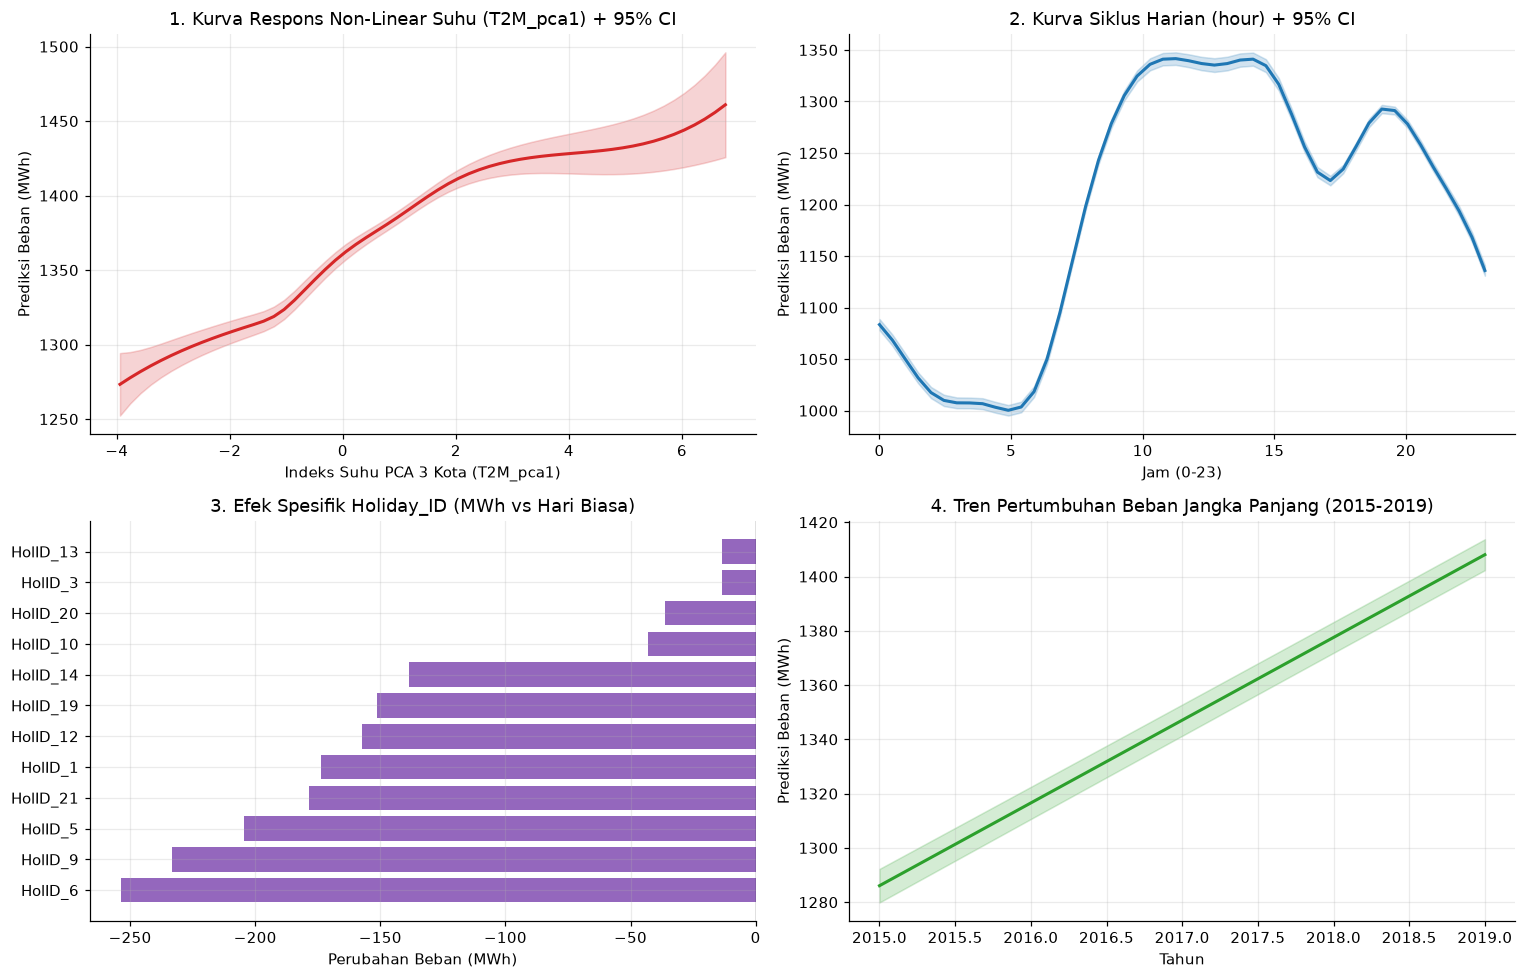

In [8]:
smooth_cols = ["hour", "day_of_year", "T2M_pca1", "QV2M_toc"]
gam_lin_cols = [
    "time_index_years", "is_weekend", "school", "pre_holiday", "post_holiday",
    "sin_dow", "cos_dow", "T2M_pca1_x_cos_hour", "T2M_pca1_x_sin_hour",
] + hol_dummy_cols


def build_gam_inputs(sub_df, clip_bounds=None, extra_lin_cols=None):
    lin_cols = gam_lin_cols + (extra_lin_cols or [])
    ex_lin = sm.add_constant(sub_df[lin_cols].astype(float), has_constant="add")
    ex_sm = sub_df[smooth_cols].astype(float).copy()
    if clip_bounds is not None:
        for col, (lo, hi) in clip_bounds.items():
            ex_sm[col] = ex_sm[col].clip(lo, hi)
    return ex_lin, ex_sm


def fit_panama_gam(fit_mask, alpha=None, extra_lin_cols=None, target_col="nat_demand_clean", df_source=None):
    src = df if df_source is None else df_source
    sub = src.loc[fit_mask].copy()
    bounds = {c: (float(sub[c].min()) + 1e-6, float(sub[c].max()) - 1e-6) for c in smooth_cols}
    ex_lin_full, ex_sm = build_gam_inputs(sub, clip_bounds=None, extra_lin_cols=extra_lin_cols)
    # Jaga agar kolom parametrik yang konstan pada fold tertentu tidak memicu singularitas
    active_cols = ["const"] + [c for c in ex_lin_full.columns if c != "const" and ex_lin_full[c].nunique() > 1]
    ex_lin = ex_lin_full[active_cols]
    bs = BSplines(ex_sm, df=[14, 12, 10, 8], degree=[3, 3, 3, 3])
    if alpha is None:
        alpha = [5.0, 5.0, 10.0, 10.0]
    gam_mod = GLMGam(sub[target_col].astype(float), exog=ex_lin, smoother=bs, alpha=alpha)
    res = gam_mod.fit()
    return res, bounds, ex_lin.columns


# 1. Cross-Validation Temporal (TimeSeriesSplit 3-fold di dalam blok latih 2015-2018)
train_idx_all = df.index[train_mask].to_numpy()
tscv_gam = TimeSeriesSplit(n_splits=3)
cv_gam_rows = []
for fold, (tr_pos, val_pos) in enumerate(tscv_gam.split(train_idx_all), 1):
    tr_idx = train_idx_all[tr_pos]
    val_idx = train_idx_all[val_pos]
    res_cv, bounds_cv, cols_cv = fit_panama_gam(tr_idx)
    val_df_cv = df.loc[val_idx]
    ex_l_val, ex_s_val = build_gam_inputs(val_df_cv, clip_bounds=bounds_cv)
    pred_val = res_cv.predict(exog=ex_l_val[cols_cv], exog_smooth=ex_s_val)
    met_cv = compute_metrics(val_df_cv["nat_demand"], pred_val)
    cv_gam_rows.append({
        "Fold": fold,
        "Train_Period": f"{df.loc[tr_idx[0], 'datetime'].strftime('%Y-%m-%d')} s.d. {df.loc[tr_idx[-1], 'datetime'].strftime('%Y-%m-%d')}",
        "Val_Period": f"{df.loc[val_idx[0], 'datetime'].strftime('%Y-%m-%d')} s.d. {df.loc[val_idx[-1], 'datetime'].strftime('%Y-%m-%d')}",
        "N_Train": len(tr_idx),
        "N_Val": len(val_idx),
        "MAE": round(met_cv["MAE"], 2),
        "RMSE": round(met_cv["RMSE"], 2),
        "MAPE_%": round(met_cv["MAPE"], 2),
    })

cv_gam_df = pd.DataFrame(cv_gam_rows)
print("=== Cross-Validation Temporal GAM (TimeSeriesSplit 3-Fold pada 2015-2018) ===")
display(cv_gam_df)
print(f"Rata-rata CV GAM -> MAE: {cv_gam_df['MAE'].mean():.2f} MWh | RMSE: {cv_gam_df['RMSE'].mean():.2f} MWh | MAPE: {cv_gam_df['MAPE_%'].mean():.2f}%\n")

# 2. Fit GAM Penuh pada 2015-2018 untuk Evaluasi Jangka Panjang Out-of-Sample 2019-2020
t0 = time.time()
res_gam_18, gam_bounds_18, gam_exog_cols = fit_panama_gam(train_mask)
print(f"GAM (Train 2015-2018) selesai dalam {time.time()-t0:.2f} detik.")
print(f"Total EDF: {res_gam_18.edf.sum():.2f} | AIC: {res_gam_18.aic:,.1f} | Pseudo-R2: {1 - res_gam_18.deviance / res_gam_18.null_deviance:.4f}")

# Prediksi GAM pada seluruh 2019 & 2020 (dari model 2015-2018 untuk evaluasi eksogen jangka panjang)
ex_lin_all, ex_sm_all = build_gam_inputs(df, clip_bounds=gam_bounds_18)
pred_gam_all = res_gam_18.get_prediction(exog=ex_lin_all[gam_exog_cols], exog_smooth=ex_sm_all).summary_frame()
df["pred_gam"] = pred_gam_all["mean"].values

m_gam_19 = compute_metrics(df.loc[test_2019_mask, "nat_demand"], df.loc[test_2019_mask, "pred_gam"])
m_gam_19_cln = compute_metrics(df.loc[mask_2019_clean, "nat_demand"], df.loc[mask_2019_clean, "pred_gam"])
print(f"GAM Test 2019 (All)         -> MAE: {m_gam_19['MAE']:.2f} | RMSE: {m_gam_19['RMSE']:.2f} | MAPE: {m_gam_19['MAPE']:.2f}%")
print(f"GAM Test 2019 (No Blackout) -> MAE: {m_gam_19_cln['MAE']:.2f} | RMSE: {m_gam_19_cln['RMSE']:.2f} | MAPE: {m_gam_19_cln['MAPE']:.2f}%")

# Plot Efek Parsial GAM (2x2) menggunakan grid prediksi
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

base_row = df.loc[train_mask].median(numeric_only=True)

def gam_partial_grid(col_name, grid_vals):
    g_df = pd.DataFrame([base_row] * len(grid_vals)).reset_index(drop=True)
    for c in hol_dummy_cols:
        g_df[c] = 0.0
    g_df["is_weekend"] = 0.0
    g_df["school"] = 1.0
    g_df["pre_holiday"] = 0.0
    g_df["post_holiday"] = 0.0
    g_df[col_name] = grid_vals
    if col_name == "hour":
        g_df["sin_hour"] = np.sin(2 * np.pi * g_df["hour"] / 24.0)
        g_df["cos_hour"] = np.cos(2 * np.pi * g_df["hour"] / 24.0)
        g_df["T2M_pca1_x_sin_hour"] = g_df["T2M_pca1"] * g_df["sin_hour"]
        g_df["T2M_pca1_x_cos_hour"] = g_df["T2M_pca1"] * g_df["cos_hour"]
    ex_l, ex_s = build_gam_inputs(g_df, clip_bounds=gam_bounds_18)
    sf = res_gam_18.get_prediction(exog=ex_l[gam_exog_cols], exog_smooth=ex_s).summary_frame()
    return sf

# 1. Sensitivitas Suhu (T2M_pca1)
t_grid = np.linspace(gam_bounds_18["T2M_pca1"][0], gam_bounds_18["T2M_pca1"][1], 60)
sf_t = gam_partial_grid("T2M_pca1", t_grid)
axes[0, 0].plot(t_grid, sf_t["mean"], color="#d62728", lw=2)
axes[0, 0].fill_between(t_grid, sf_t["mean_ci_lower"], sf_t["mean_ci_upper"], color="#d62728", alpha=0.2)
axes[0, 0].set_title("1. Kurva Respons Non-Linear Suhu (T2M_pca1) + 95% CI")
axes[0, 0].set_xlabel("Indeks Suhu PCA 3 Kota (T2M_pca1)")
axes[0, 0].set_ylabel("Prediksi Beban (MWh)")

# 2. Profil Beban Harian (hour)
h_grid = np.linspace(0, 23, 48)
sf_h = gam_partial_grid("hour", h_grid)
axes[0, 1].plot(h_grid, sf_h["mean"], color="#1f77b4", lw=2)
axes[0, 1].fill_between(h_grid, sf_h["mean_ci_lower"], sf_h["mean_ci_upper"], color="#1f77b4", alpha=0.2)
axes[0, 1].set_title("2. Kurva Siklus Harian (hour) + 95% CI")
axes[0, 1].set_xlabel("Jam (0-23)")
axes[0, 1].set_ylabel("Prediksi Beban (MWh)")

# 3. Koefisien Efek 22 Kategori Holiday_ID (Top 12 paling berpengaruh)
hol_coefs = res_gam_18.params[hol_dummy_cols].sort_values()
top_hol = pd.concat([hol_coefs.head(8), hol_coefs.tail(4)])
axes[1, 0].barh(top_hol.index, top_hol.values, color="#9467bd")
axes[1, 0].axvline(0, color="black", lw=0.8)
axes[1, 0].set_title("3. Efek Spesifik Holiday_ID (MWh vs Hari Biasa)")
axes[1, 0].set_xlabel("Perubahan Beban (MWh)")

# 4. Tren Pertumbuhan Jangka Panjang (time_index_years)
yr_grid = np.linspace(0, 4.0, 50)
sf_yr = gam_partial_grid("time_index_years", yr_grid)
axes[1, 1].plot(2015 + yr_grid, sf_yr["mean"], color="#2ca02c", lw=2)
axes[1, 1].fill_between(2015 + yr_grid, sf_yr["mean_ci_lower"], sf_yr["mean_ci_upper"], color="#2ca02c", alpha=0.2)
axes[1, 1].set_title("4. Tren Pertumbuhan Beban Jangka Panjang (2015-2019)")
axes[1, 1].set_xlabel("Tahun")
axes[1, 1].set_ylabel("Prediksi Beban (MWh)")

plt.tight_layout()
plt.show()

=== 1. Uji Validasi Placebo (Maret-Juni 2019, Pra-COVID) ===
  Rata-rata Bias (Aktual - Prediksi GAM): +6.35 MWh (+0.66%) | MAE: 61.89 MWh

=== 2. Estimasi Dampak Kausal COVID-19 per Bulan (Jan-Jun 2020) ===


,Aktual_Mean_MWh,Counterfactual_Mean_MWh,Delta_Mean_MWh,Delta_Persen,Total_Energi_Hilang_GWh
month,,,,,
1,1276.59,1256.84,19.75,1.75,14.70
2,1269.52,1252.87,16.65,1.59,11.59
3,1208.99,1284.51,-75.51,-5.40,-56.18
4,1062.04,1297.50,-235.46,-16.98,-169.53
5,1088.15,1306.20,-218.04,-15.94,-162.22
6,1109.26,1297.93,-188.68,-14.06,-117.92


Total Energi Hilang (Mar-Jun 2020): -505.86 GWh (Rata-rata -178.56 MWh/jam atau -13.02%)


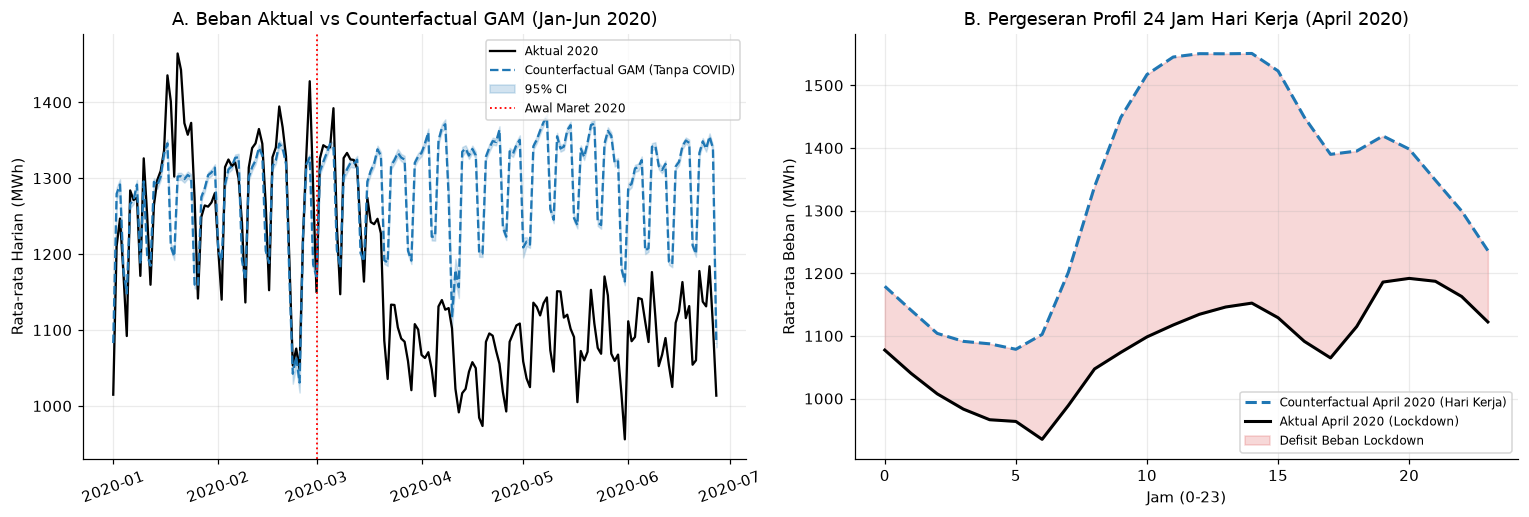

In [9]:
# 1. Uji Validasi Placebo: Maret-Juni 2019 (dari model GAM 2015-2018)
placebo_mask = (df["datetime"] >= "2019-03-01") & (df["datetime"] <= "2019-06-30 23:00:00")
diff_pl = df.loc[placebo_mask, "nat_demand"] - df.loc[placebo_mask, "pred_gam"]
bias_pl = diff_pl.mean()
bias_pl_pct = (diff_pl / df.loc[placebo_mask, "pred_gam"]).mean() * 100.0
print("=== 1. Uji Validasi Placebo (Maret-Juni 2019, Pra-COVID) ===")
print(f"  Rata-rata Bias (Aktual - Prediksi GAM): {bias_pl:+.2f} MWh ({bias_pl_pct:+.2f}%) | MAE: {np.abs(diff_pl).mean():.2f} MWh")

# 2. Refit GAM pada seluruh data Pra-Pandemi (Jan 2015 - Feb 2020)
pre_covid_mask = df["datetime"] < covid_start_dt
res_gam_pre, gam_bounds_pre, gam_cols_pre = fit_panama_gam(pre_covid_mask)

# Prediksi Counterfactual Y_hat(0) untuk 2020 (Jan-Jun 2020)
ex_lin_20, ex_sm_20 = build_gam_inputs(df.loc[test_2020_mask], clip_bounds=gam_bounds_pre)
cf_20 = res_gam_pre.get_prediction(exog=ex_lin_20[gam_cols_pre], exog_smooth=ex_sm_20).summary_frame()

df_20 = df.loc[test_2020_mask, ["datetime", "month", "hour", "is_weekend", "nat_demand"]].copy()
df_20["cf_mean"] = cf_20["mean"].values
df_20["cf_ci_lo"] = cf_20["mean_ci_lower"].values
df_20["cf_ci_hi"] = cf_20["mean_ci_upper"].values
df_20["delta_mwh"] = df_20["nat_demand"] - df_20["cf_mean"]
df_20["delta_pct"] = df_20["delta_mwh"] / df_20["cf_mean"] * 100.0

print("\n=== 2. Estimasi Dampak Kausal COVID-19 per Bulan (Jan-Jun 2020) ===")
monthly_cf = df_20.groupby("month").agg(
    Aktual_Mean_MWh=("nat_demand", "mean"),
    Counterfactual_Mean_MWh=("cf_mean", "mean"),
    Delta_Mean_MWh=("delta_mwh", "mean"),
    Delta_Persen=("delta_pct", "mean"),
    Total_Energi_Hilang_GWh=("delta_mwh", lambda s: s.sum() / 1000.0),
).round(2)
display(monthly_cf)

mar_jun = df_20[df_20["month"] >= 3]
print(f"Total Energi Hilang (Mar-Jun 2020): {mar_jun['delta_mwh'].sum()/1000.0:,.2f} GWh (Rata-rata {mar_jun['delta_mwh'].mean():+.2f} MWh/jam atau {mar_jun['delta_pct'].mean():+.2f}%)")

# Plot Dampak Kausal COVID-19
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Panel A: Aktual vs Counterfactual Harian (Jan-Jun 2020)
d20_daily = df_20.set_index("datetime")[["nat_demand", "cf_mean", "cf_ci_lo", "cf_ci_hi"]].resample("D").mean()
axes[0].plot(d20_daily.index, d20_daily["nat_demand"], color="black", lw=1.5, label="Aktual 2020")
axes[0].plot(d20_daily.index, d20_daily["cf_mean"], color="#1f77b4", ls="--", lw=1.5, label="Counterfactual GAM (Tanpa COVID)")
axes[0].fill_between(d20_daily.index, d20_daily["cf_ci_lo"], d20_daily["cf_ci_hi"], color="#1f77b4", alpha=0.2, label="95% CI")
axes[0].axvline(covid_start_dt, color="red", ls=":", lw=1.2, label="Awal Maret 2020")
axes[0].set_title("A. Beban Aktual vs Counterfactual GAM (Jan-Jun 2020)")
axes[0].set_ylabel("Rata-rata Harian (MWh)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=8)

# Panel B: Pergeseran Kurva Intraharian 24 Jam pada April 2020 (Hari Kerja)
apr_wd = df_20[(df_20["month"] == 4) & (df_20["is_weekend"] == 0)].groupby("hour")[["nat_demand", "cf_mean"]].mean()
axes[1].plot(apr_wd.index, apr_wd["cf_mean"], color="#1f77b4", ls="--", lw=2, label="Counterfactual April 2020 (Hari Kerja)")
axes[1].plot(apr_wd.index, apr_wd["nat_demand"], color="black", lw=2, label="Aktual April 2020 (Lockdown)")
axes[1].fill_between(apr_wd.index, apr_wd["nat_demand"], apr_wd["cf_mean"], color="#d62728", alpha=0.18, label="Defisit Beban Lockdown")
axes[1].set_title("B. Pergeseran Profil 24 Jam Hari Kerja (April 2020)")
axes[1].set_xlabel("Jam (0-23)")
axes[1].set_ylabel("Rata-rata Beban (MWh)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Tahap 5: Model Solusi 2 — Forecasting Jangka Pendek (STLF, $h=168$ Jam) dengan *Gradient Boosted Trees* (`LightGBM` / `HistGradientBoosting`) + CV Temporal + *Quantile Loss*

Tahap ini merupakan model utama untuk **Forecasting Jangka Pendek (STLF, horizon operasional $h = 168$ jam / 1 minggu)** menggunakan **Set B** (cuaca 3 kota, kalender, dan *lag* beban historis minimal 168 jam). Model berbasis pohon gradien mengoptimalkan objektif Taylor orde kedua dengan regularisasi $L_2$:

$$w_l^* = -\frac{\sum_{t \in I_l} g_t}{\sum_{t \in I_l} q_t + \lambda_{\text{L2}}}$$

Sebelum pelatihan model final pada seluruh blok `2015–2018`, dilakukan **Cross-Validation Temporal (`TimeSeriesSplit` 3-fold *expanding window*)** di dalam `2015–2018` dengan konfigurasi *hyperparameter* identik (`lr=0.05`, `max_iter=350`) untuk memverifikasi stabilitas error antar-tahun tanpa *data leakage*.

Untuk menjawab **heteroskedastisitas** serta ***outlier* *blackout***, selain prediksi titik (*L2*), kita melatih model dengan **Pinball Loss** pada kuantil $\tau \in \{0{,}05, 0{,}50, 0{,}95\}$ untuk menghasilkan interval prediksi 90%, lalu membedah kontribusi fitur (*TreeSHAP* atau *Grouped Permutation Importance & Partial Dependence*).

### Penjelasan Algoritma Matematis (Tahap 5)
1. **Boosting Aditif & Bobot Daun Orde Kedua:**
   Prediksi pada iterasi ke-$M$ adalah penjumlahan berbobot $M$ pohon regresi $\hat{Y}_t^{(M)} = \sum_{m=1}^{M} \eta\, h_m(\mathbf{z}_t)$, dengan fungsi objektif teregularisasi ($\lambda_{\text{L2}} = 5{,}0$):
   $$\mathcal{L}^{(m)} \approx \sum_{t=1}^{n}\left[ g_t h_m(\mathbf{z}_t) + \frac{1}{2} q_t h_m^2(\mathbf{z}_t) \right] + \frac{1}{2}\lambda_{\text{L2}}\sum_{l=1}^{T} w_l^2, \qquad g_t = \frac{\partial \ell}{\partial \hat{Y}_t^{(m-1)}},\quad q_t = \frac{\partial^2 \ell}{\partial (\hat{Y}_t^{(m-1)})^2}$$
2. **Fungsi Rugi Titik & Kuantil (*Pinball Loss*) + Metrik Interval:**
   - Model titik meminimalkan *Squared Error* $\ell_{L_2}(y,\hat{y}) = \frac{1}{2}(y-\hat{y})^2$.
   - Tiga model kuantil ($\tau \in \{0{,}05,\, 0{,}50,\, 0{,}95\}$) meminimalkan **Pinball Loss**:
     $$\ell_\tau(y, \hat{y}) = \max\left(\tau(y - \hat{y}),\; (\tau - 1)(y - \hat{y})\right)$$
   - Kualitas interval 90% $[\hat{L}_t, \hat{U}_t] = [\hat{Q}_{0.05}, \hat{Q}_{0.95}]$ ($\alpha = 0{,}10$) diukur lewat cakupan empiris (**PICP**) dan **Winkler Score**:
     $$\text{PICP} = \frac{1}{n}\sum_{t=1}^{n}\mathbb{I}(\hat{L}_t \le Y_t \le \hat{U}_t), \qquad W_t = (\hat{U}_t - \hat{L}_t) + \frac{2}{\alpha}(\hat{L}_t - Y_t)_+ + \frac{2}{\alpha}(Y_t - \hat{U}_t)_+$$
3. **Interpretabilitas Model (`TreeSHAP` / `Permutation Importance` & `PDP`):**
   - Jika `shap` tersedia, kontribusi aditif fitur dihitung eksak dengan nilai Shapley $\hat{Y}_t = \phi_0 + \sum_{i} \phi_i(\mathbf{z}_t)$; jika tidak, digunakan *Permutation Importance* ($\Delta\text{RMSE}_j = \text{RMSE}_{\text{acak},j} - \text{RMSE}_{\text{awal}}$) yang diagregasikan per kelompok semantik, serta *Partial Dependence Plot* $\hat{f}_S(x_S) = \frac{1}{n}\sum_{t=1}^n \hat{f}(x_S, \mathbf{x}_{C,t})$ untuk suhu `T2M_toc`.

### Penjelasan Algoritma Kode (Sel 16 & Sel 17)
- **Sel 16 (CV Temporal, Pelatihan Titik & Kuantil, serta Evaluasi Probabilistik):**
  1. Menyaring baris latih valid (`train_b_mask`, melewati 504 jam pertama akibat `load_lag_504`) menjadi `X_train_b` dan `y_train_b`.
  2. Fungsi `make_gbm(loss_mode, alpha_q, ...)` membangkitkan `LGBMRegressor` jika `HAS_LGBM=True`, atau otomatis `HistGradientBoostingRegressor` dengan `categorical_features=["Holiday_ID"]` dan `l2_regularization=5.0`.
  3. Menjalankan `TimeSeriesSplit(n_splits=3)` menggunakan parameter identik model final (`lr=0.05, max_iter=350`) dan mencetak tabel `cv_gbm_df`.
  4. Melatih 4 model (`model_pt`, `model_q05`, `model_q50`, `model_q95`), memprediksi `2019` dan `2020`, mencetak metrik titik + probabilistik (Pinball, PICP, Winkler), dan memplot interval prediksi 90% pada 1 minggu normal (Mei 2019) vs 1 minggu lockdown (April 2020).
- **Sel 17 (XAI & Profil Sensitivitas Suhu):**
  1. Mengambil sub-sampel sistematis tiap 4 jam (`X_19_sample`) dari `X_test_19`.
  2. Memilih cabang `shap.TreeExplainer` (jika `HAS_SHAP` & `HAS_LGBM`) atau `permutation_importance(..., n_repeats=5, scoring="neg_root_mean_squared_error")`, lalu mengelompokkan fitur lewat `map_feature_group()`.
  3. Menghitung `partial_dependence(model_pt, X_19_sample, features=["T2M_toc"])` dan menampilkan 3 panel plot.

=== Cross-Validation Temporal HistGradientBoosting (TimeSeriesSplit 3-Fold pada 2015-2018) ===


,Fold,Train_Period,Val_Period,N_Train,N_Val,MAE,RMSE,MAPE_%
0,1,2015-01-24 s.d. 2016-01-18,2016-01-18 s.d. 2017-01-12,8630,8627,35.34,47.33,3.09
1,2,2015-01-24 s.d. 2017-01-12,2017-01-12 s.d. 2018-01-06,17257,8627,35.79,48.02,3.04
2,3,2015-01-24 s.d. 2018-01-06,2018-01-06 s.d. 2018-12-31,25884,8627,38.90,47.91,3.20


Rata-rata CV HistGradientBoosting -> MAE: 36.68 MWh | RMSE: 47.75 MWh | MAPE: 3.11%

Seluruh model HistGradientBoosting (Point + Q05/Q50/Q95) selesai dilatih dalam 142.34 detik.
[HistGradientBoosting - 2019 (All)        ] MAE:  41.67 | RMSE:  58.25 | MAPE:  3.62% | Pinball: 12.57 | PICP(90%):  66.0% | Winkler: 331.89
[HistGradientBoosting - 2019 (No Blackout)] MAE:  41.18 | RMSE:  54.05 | MAPE:  3.31% | Pinball: 12.32 | PICP(90%):  66.0% | Winkler: 321.97
[HistGradientBoosting - Mar-Jun 2020 (COVID)] MAE:  82.88 | RMSE: 111.65 | MAPE:  7.55% | Pinball: 25.46 | PICP(90%):  53.2% | Winkler: 700.26


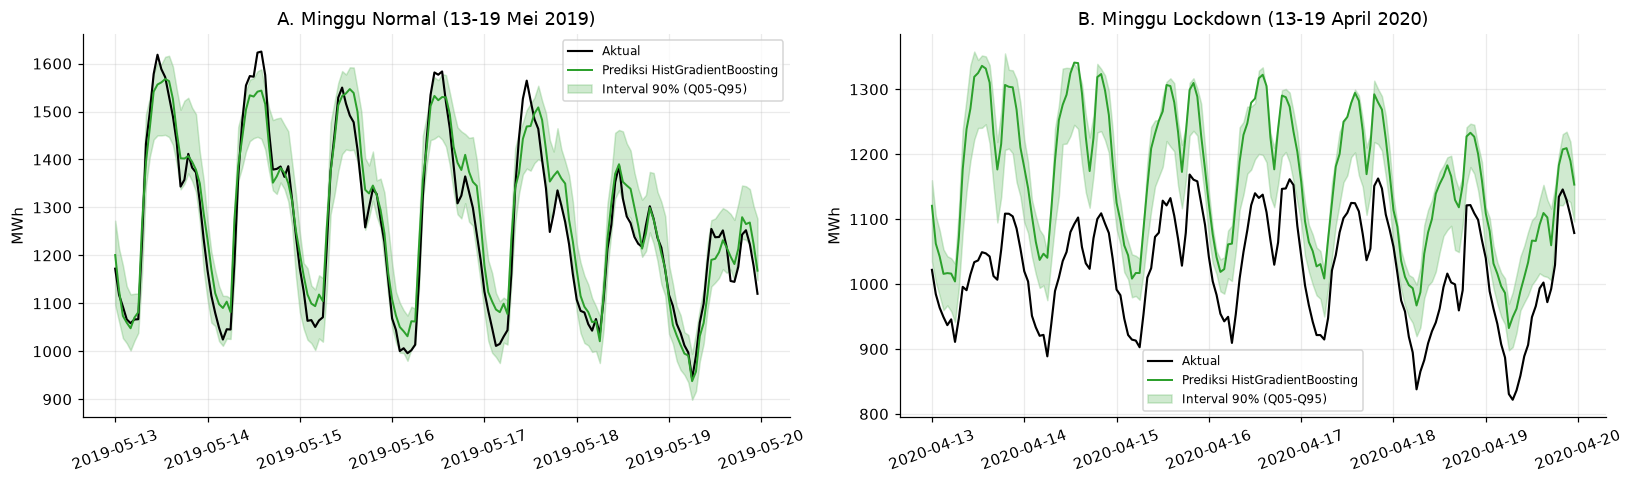

In [10]:
# Siapkan Set B yang valid (buang 504 baris pertama akibat lag 504 pada train)
train_b_mask = train_mask & df[set_b_features].notna().all(axis=1)
X_train_b = df.loc[train_b_mask, set_b_features]
y_train_b = df.loc[train_b_mask, "nat_demand_clean"]
dt_train_b = df.loc[train_b_mask, "datetime"]

X_test_19 = df.loc[test_2019_mask, set_b_features]
X_test_20 = df.loc[test_2020_mask, set_b_features]

def make_gbm(loss_mode="squared", alpha_q=0.5, lr=0.05, max_iter=350, max_leaf=63):
    if HAS_LGBM:
        import lightgbm as lgb
        obj_map = {"squared": "regression", "absolute": "regression_l1", "quantile": "quantile"}
        params = dict(
            objective=obj_map[loss_mode],
            learning_rate=lr,
            n_estimators=max_iter,
            num_leaves=max_leaf,
            min_child_samples=40,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=1.0,
            reg_lambda=5.0,
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        )
        if loss_mode == "quantile":
            params["alpha"] = alpha_q
        return lgb.LGBMRegressor(**params)
    else:
        loss_sk = {"squared": "squared_error", "absolute": "absolute_error", "quantile": "quantile"}[loss_mode]
        params = dict(
            loss=loss_sk,
            learning_rate=lr,
            max_iter=max_iter,
            max_leaf_nodes=max_leaf,
            min_samples_leaf=40,
            l2_regularization=5.0,
            categorical_features=["Holiday_ID"],
            random_state=42,
        )
        if loss_mode == "quantile":
            params["quantile"] = alpha_q
        return HistGradientBoostingRegressor(**params)

# Validasi Temporal (TimeSeriesSplit 3-fold pada 2015-2018) dengan hyperparameter identik model final
gbm_name = "LightGBM" if HAS_LGBM else "HistGradientBoosting"
tscv = TimeSeriesSplit(n_splits=3)
cv_gbm_rows = []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_b), 1):
    m_cv = make_gbm("squared", lr=0.05, max_iter=350)
    m_cv.fit(X_train_b.iloc[tr_idx], y_train_b.iloc[tr_idx])
    p_cv = m_cv.predict(X_train_b.iloc[val_idx])
    met_cv = compute_metrics(y_train_b.iloc[val_idx], p_cv)
    cv_gbm_rows.append({
        "Fold": fold,
        "Train_Period": f"{dt_train_b.iloc[tr_idx[0]].strftime('%Y-%m-%d')} s.d. {dt_train_b.iloc[tr_idx[-1]].strftime('%Y-%m-%d')}",
        "Val_Period": f"{dt_train_b.iloc[val_idx[0]].strftime('%Y-%m-%d')} s.d. {dt_train_b.iloc[val_idx[-1]].strftime('%Y-%m-%d')}",
        "N_Train": len(tr_idx),
        "N_Val": len(val_idx),
        "MAE": round(met_cv["MAE"], 2),
        "RMSE": round(met_cv["RMSE"], 2),
        "MAPE_%": round(met_cv["MAPE"], 2),
    })

cv_gbm_df = pd.DataFrame(cv_gbm_rows)
print(f"=== Cross-Validation Temporal {gbm_name} (TimeSeriesSplit 3-Fold pada 2015-2018) ===")
display(cv_gbm_df)
print(f"Rata-rata CV {gbm_name} -> MAE: {cv_gbm_df['MAE'].mean():.2f} MWh | RMSE: {cv_gbm_df['RMSE'].mean():.2f} MWh | MAPE: {cv_gbm_df['MAPE_%'].mean():.2f}%\n")

# Fit Model Titik (L2) + 3 Model Kuantil (0.05, 0.50, 0.95)
t0 = time.time()
model_pt = make_gbm("squared")
model_pt.fit(X_train_b, y_train_b)

model_q05 = make_gbm("quantile", alpha_q=0.05)
model_q50 = make_gbm("quantile", alpha_q=0.50)
model_q95 = make_gbm("quantile", alpha_q=0.95)
model_q05.fit(X_train_b, y_train_b)
model_q50.fit(X_train_b, y_train_b)
model_q95.fit(X_train_b, y_train_b)
print(f"Seluruh model {gbm_name} (Point + Q05/Q50/Q95) selesai dilatih dalam {time.time()-t0:.2f} detik.")

for m_mask, X_m in [(test_2019_mask, X_test_19), (test_2020_mask, X_test_20)]:
    df.loc[m_mask, "pred_gbm"] = model_pt.predict(X_m)
    df.loc[m_mask, "pred_gbm_q05"] = model_q05.predict(X_m)
    df.loc[m_mask, "pred_gbm_q50"] = model_q50.predict(X_m)
    df.loc[m_mask, "pred_gbm_q95"] = model_q95.predict(X_m)

# Evaluasi Titik & Probabilistik
for lbl, msk in [("2019 (All)", test_2019_mask), ("2019 (No Blackout)", mask_2019_clean), ("Mar-Jun 2020 (COVID)", lockdown_2020_mask)]:
    yt = df.loc[msk, "nat_demand"]
    yp = df.loc[msk, "pred_gbm"]
    ql = df.loc[msk, "pred_gbm_q05"]
    qm = df.loc[msk, "pred_gbm_q50"]
    qh = df.loc[msk, "pred_gbm_q95"]
    met = compute_metrics(yt, yp)
    avg_pb = np.mean([pinball_loss(yt, ql, 0.05), pinball_loss(yt, qm, 0.50), pinball_loss(yt, qh, 0.95)])
    picp = np.mean((yt >= ql) & (yt <= qh)) * 100.0
    ws = winkler_score(yt, ql, qh, alpha=0.10)
    print(f"[{gbm_name} - {lbl:18s}] MAE: {met['MAE']:6.2f} | RMSE: {met['RMSE']:6.2f} | MAPE: {met['MAPE']:5.2f}% | Pinball: {avg_pb:5.2f} | PICP(90%): {picp:5.1f}% | Winkler: {ws:6.2f}")

# Plot Interval Prediksi 90% pada 1 Minggu Normal (Mei 2019) vs 1 Minggu Lockdown (April 2020)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (title, t_start, t_end) in zip(axes, [
    ("A. Minggu Normal (13-19 Mei 2019)", "2019-05-13", "2019-05-19 23:00"),
    ("B. Minggu Lockdown (13-19 April 2020)", "2020-04-13", "2020-04-19 23:00"),
]):
    w_df = df[(df["datetime"] >= t_start) & (df["datetime"] <= t_end)]
    ax.plot(w_df["datetime"], w_df["nat_demand"], color="black", lw=1.4, label="Aktual")
    ax.plot(w_df["datetime"], w_df["pred_gbm"], color="#2ca02c", lw=1.3, label=f"Prediksi {gbm_name}")
    ax.fill_between(w_df["datetime"], w_df["pred_gbm_q05"], w_df["pred_gbm_q95"], color="#2ca02c", alpha=0.22, label="Interval 90% (Q05-Q95)")
    ax.set_title(title)
    ax.set_ylabel("MWh")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

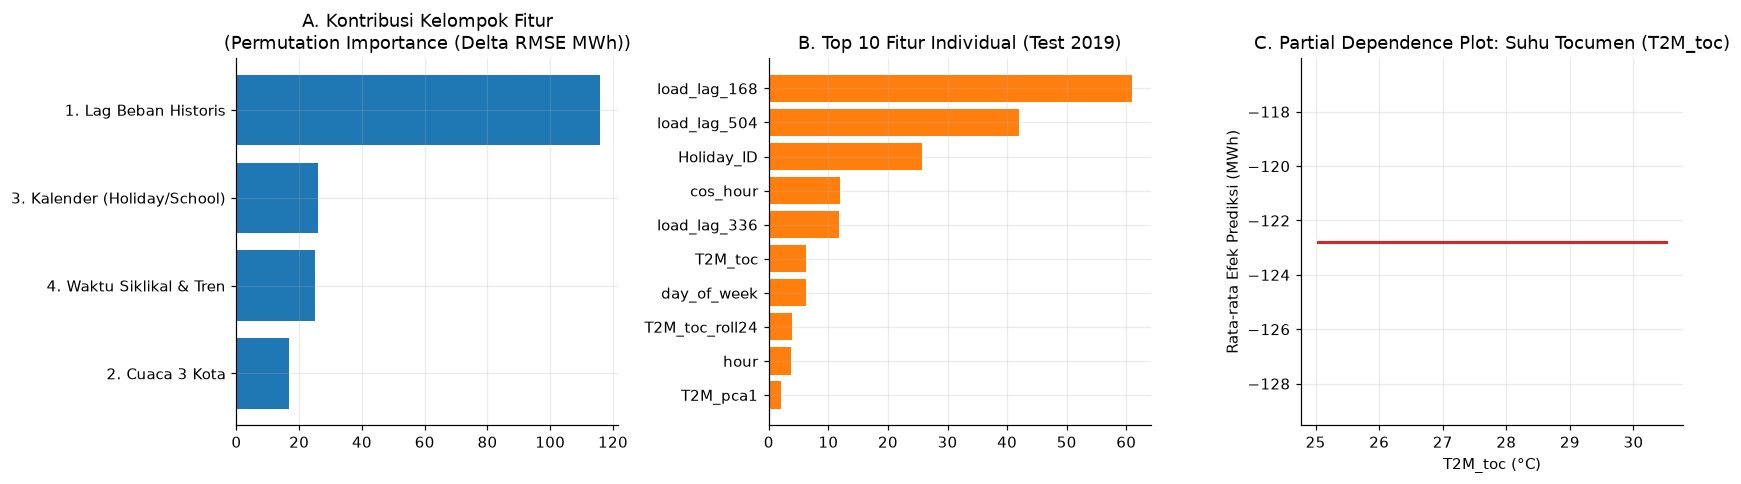

In [11]:
# Interpretabilitas Model Boosting (TreeSHAP jika terpasang, atau Grouped Permutation Importance + PDP)
X_19_sample = X_test_19.iloc[::4].copy()  # subsampling tiap 4 jam (~2.190 titik) agar cepat & representatif
y_19_sample = df.loc[test_2019_mask, "nat_demand"].iloc[::4].copy()

def map_feature_group(col):
    if col.startswith("load_"):
        return "1. Lag Beban Historis"
    if any(col.startswith(p) for p in ["T2M_", "QV2M_", "TQL_", "W2M_"]):
        return "2. Cuaca 3 Kota"
    if col in ["holiday", "Holiday_ID", "school", "pre_holiday", "post_holiday"]:
        return "3. Kalender (Holiday/School)"
    return "4. Waktu Siklikal & Tren"

if HAS_SHAP and HAS_LGBM:
    import shap
    explainer = shap.TreeExplainer(model_pt)
    shap_vals = explainer.shap_values(X_19_sample)
    imp_series = pd.Series(np.abs(shap_vals).mean(axis=0), index=set_b_features)
    method_label = "Mean |SHAP| (MWh)"
else:
    perm = permutation_importance(model_pt, X_19_sample, y_19_sample, n_repeats=5, random_state=42, scoring="neg_root_mean_squared_error")
    imp_series = pd.Series(perm.importances_mean, index=set_b_features)
    method_label = "Permutation Importance (Delta RMSE MWh)"

grouped_imp = imp_series.groupby([map_feature_group(c) for c in imp_series.index]).sum().sort_values(ascending=True)
top10_feat = imp_series.sort_values(ascending=True).tail(10)

# Partial Dependence untuk T2M_toc pada model Boosting
pdp_res = partial_dependence(model_pt, X_19_sample, features=["T2M_toc"], grid_resolution=40)
t2m_grid = pdp_res["grid_values"][0]
t2m_pdp = pdp_res["average"][0]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5))

axes[0].barh(grouped_imp.index, grouped_imp.values, color="#1f77b4")
axes[0].set_title(f"A. Kontribusi Kelompok Fitur\n({method_label})")

axes[1].barh(top10_feat.index, top10_feat.values, color="#ff7f0e")
axes[1].set_title("B. Top 10 Fitur Individual (Test 2019)")

axes[2].plot(t2m_grid, t2m_pdp, color="#d62728", lw=2)
axes[2].set_title("C. Partial Dependence Plot: Suhu Tocumen (T2M_toc)")
axes[2].set_xlabel("T2M_toc (°C)")
axes[2].set_ylabel("Rata-rata Efek Prediksi (MWh)")

plt.tight_layout()
plt.show()

---
## Tahap 6 (Opsional Lanjutan): *Temporal Fusion Transformer* (TFT)

Arsitektur TFT memisahkan secara eksplisit *observed past inputs* (`nat_demand` sepanjang *encoder window*) dari *known future inputs* (waktu, kalender, dan cuaca 3 kota pada *decoder horizon*), lalu menggabungkan *LSTM Encoder-Decoder* dan *Interpretable Multi-Head Attention*:

$$\text{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{softmax}\left( \frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}} \right)\mathbf{V}$$

Sel kode di bawah bersifat **opsional terproteksi** (`if HAS_TFT:`): akan langsung berjalan apabila `pytorch-forecasting` dan `torch` terpasang (disarankan di GPU), dan dilewati secara aman tanpa error pada eksekusi CPU standar.

### Penjelasan Algoritma Matematis (Tahap 6)
1. **Pemrosesan Sekuens *Multi-Horizon*:** TFT memetakan input historis tak diketahui (`nat_demand_clean` pada jendela *encoder* $L = 336$ jam) dan fitur masa depan diketahui (waktu, kalender, cuaca pada *decoder* $H = 168$ jam) melalui *Variable Selection Network* (VSN), *LSTM Encoder-Decoder*, serta *Multi-Head Attention* ber-4 kepala (`attention_head_size=4`).
2. **Fungsi Rugi Kuantil Multi-Horizon:** Melatih proyeksi $\tau \in \{0{,}05,\, 0{,}50,\, 0{,}95\}$ secara simultan di sepanjang 168 jam ke depan:
   $$\mathcal{L}_{\text{TFT}} = \sum_{t} \sum_{\tau \in \mathcal{Q}} \sum_{h=1}^{168} \ell_\tau\left(Y_{t+h},\, \hat{Y}_{t+h}^{(\tau)}\right)$$

### Penjelasan Algoritma Kode (Sel 19)
1. Mengecek flag `if HAS_TFT:` agar eksekusi tetap portabel tanpa ketergantungan wajib pada PyTorch.
2. Jika tersedia, menyiapkan `df_tft` dengan `time_idx` berurutan, membungkus dataset ke `TimeSeriesDataSet(max_encoder_length=336, max_prediction_length=168)` pada periode latih `<= training_cutoff`, lalu menginisialisasi `TemporalFusionTransformer.from_dataset()` dan melatih 10 *epoch* dengan `lightning.pytorch.Trainer`.

In [12]:
if HAS_TFT:
    import torch
    from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet
    from pytorch_forecasting.metrics import QuantileLoss
    import lightning.pytorch as pl

    df_tft = df.copy()
    df_tft["time_idx"] = np.arange(len(df_tft))
    df_tft["series_id"] = "panama_grid"
    df_tft["Holiday_ID_str"] = df_tft["Holiday_ID"].astype(str)

    max_encoder_length = 168 * 2
    max_prediction_length = 168
    training_cutoff = int(df_tft.loc[train_mask, "time_idx"].max())

    training_tft = TimeSeriesDataSet(
        df_tft[df_tft["time_idx"] <= training_cutoff],
        time_idx="time_idx",
        target="nat_demand_clean",
        group_ids=["series_id"],
        max_encoder_length=max_encoder_length,
        max_prediction_length=max_prediction_length,
        time_varying_known_categoricals=["Holiday_ID_str"],
        time_varying_known_reals=["time_index_years", "sin_hour", "cos_hour", "sin_dow", "cos_dow", "holiday", "school"] + weather_cols,
        time_varying_unknown_reals=["nat_demand_clean"],
        add_relative_time_idx=True,
        add_target_scales=True,
    )
    train_dl = training_tft.to_dataloader(train=True, batch_size=128, num_workers=0)
    tft = TemporalFusionTransformer.from_dataset(
        training_tft,
        learning_rate=1e-3,
        hidden_size=32,
        attention_head_size=4,
        dropout=0.1,
        loss=QuantileLoss(quantiles=[0.05, 0.50, 0.95]),
    )
    trainer = pl.Trainer(max_epochs=10, gradient_clip_val=0.1, accelerator="auto")
    trainer.fit(tft, train_dataloaders=train_dl)
    print("TFT selesai dilatih.")
else:
    print("Tahap 6 (TFT) dilewati: `pytorch_forecasting` / `torch` tidak terpasang. Pipeline inti (Baseline -> SARIMA/SARIMAX -> GAM -> Boosting) tetap lengkap.")

Tahap 6 (TFT) dilewati: `pytorch_forecasting` / `torch` tidak terpasang. Pipeline inti (Baseline -> SARIMA/SARIMAX -> GAM -> Boosting) tetap lengkap.


---
## Tahap 7: Evaluasi Komparatif Lengkap (Metode Dasar vs Model Solusi) & Uji *Diebold-Mariano*

Seluruh model yang dilatih pada `2015–2018` dibandingkan secara langsung pada evaluasi *backtesting* terhadap data uji sesungguhnya (`2019` normal dan `Mar–Jun 2020` pandemi), dengan pemisahan peran horizon yang eksplisit:
- **Forecasting Jangka Pendek (STLF, $h = 168$ jam / 1 minggu):** model dasar (`Seasonal Naive`, `SARIMA`, `SARIMAX`) dibandingkan terhadap model solusi (`HistGradientBoosting` / `LightGBM`, Set B).
- **Forecasting Jangka Panjang / Eksogen Murni (1 tahun penuh tanpa *lag* target):** `GAM` (Set A).

### Penjelasan Algoritma Matematis (Tahap 7)
1. **Metrik Akurasi Titik (*Backtesting*):**
   $$\text{MAE} = \frac{1}{n}\sum_{t=1}^n |Y_t - \hat{Y}_t|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^n (Y_t - \hat{Y}_t)^2}, \qquad \text{MAPE} = \frac{100\%}{n}\sum_{t=1}^n \left|\frac{Y_t - \hat{Y}_t}{Y_t}\right|$$
2. **Uji Signifikansi *Diebold-Mariano* (DM) dengan Varians Newey-West (HAC):**
   Untuk menguji apakah keunggulan akurasi suatu model atas referensi (`SARIMAX` atau `Seasonal Naive`) signifikan secara statistik di tengah autokorelasi galat multi-langkah $h = 168$ jam, definisikan selisih kerugian kuadratik $d_t = e_{\text{Ref},t}^2 - e_{m,t}^2$. Hipotesis nol $H_0: E[d_t] = 0$ diuji dengan estimator varians jangka panjang Newey-West kernel Bartlett ($K = h - 1 = 167$):
   $$\widehat{\text{Var}}_{\text{HAC}}(\bar{d}) = \frac{1}{T}\left[ \hat{\gamma}_0 + 2\sum_{k=1}^{K}\left(1 - \frac{k}{K+1}\right)\hat{\gamma}_k \right], \qquad DM = \frac{\bar{d}}{\sqrt{\widehat{\text{Var}}_{\text{HAC}}(\bar{d})}} \xrightarrow{d} \mathcal{N}(0, 1)$$
   Nilai $DM > +1{,}96$ ($p < 0{,}05$) menandakan model $m$ secara statistik lebih akurat dibanding referensi.
3. **Diagnostik Residual Uji:** Mengukur `acorr_ljungbox` (lag 168) dan `het_arch` (lag 24) pada error uji `2019` seluruh 5 model.

### Penjelasan Algoritma Kode (Sel 21)
1. Mendefinisikan `models_eval` untuk kelima model (`Seasonal Naive`, `SARIMA`, `SARIMAX`, `GAM`, dan `{gbm_name}`) beserta label `Kategori_Forecast`.
2. Mengiterasi kelima model untuk menghitung `compute_metrics()` pada `test_2019_mask`, `mask_2019_clean` (tanpa 5 titik *blackout*), dan `lockdown_2020_mask` (`Mar–Jun 2020`), menghitung $p$-value Ljung-Box dan ARCH-LM, serta memanggil `diebold_mariano_test(..., h=168)` terhadap referensi `SARIMAX` (`DM_vs_SARIMAX`) maupun `Seasonal Naive` (`DM_vs_Naive`).
3. Menampilkan tabel `summary_df` dan memplot dua panel perbandingan (diagram batang RMSE/MAE `2019` untuk 5 model serta kurva ACF error lag `1–174` antara `SARIMAX`, `GAM`, dan `{gbm_name}`).

=== TABEL PERBANDINGAN KOMPARATIF BACKTESTING (Catatan: DM > 0 berarti Model lebih baik dari Referensi) ===


,Model,Paradigma,Kategori_Forecast,MAE_2019_All,RMSE_2019_All,MAE_2019_NoBO,RMSE_2019_NoBO,MAPE_2019_NoBO_%,MAPE_MarJun2020_%,LjungBox_lag168_p,ARCH_LM_p,DM_vs_SARIMAX,DM_vs_Naive
0,Seasonal Naive (Y_t-168),Baseline,Jangka Pendek (h=168j),67.79,100.19,67.33,97.94,5.43,5.63,0.00e+00,0.00e+00,+3.47 (p=5.15e-04),Ref
1,"SARIMA(1,0,1)(1,1,0)_24",Statistik Univariat,Jangka Pendek (h=168j),86.04,123.52,85.43,120.38,6.80,5.87,0.00e+00,0.00e+00,-3.01 (p=2.58e-03),-3.99 (p=6.69e-05)
2,SARIMAX (Linear),Statistik Multivariat,Jangka Pendek (h=168j),83.33,119.90,82.73,116.75,6.57,5.58,0.00e+00,0.00e+00,Ref,-3.47 (p=5.15e-04)
3,GAM (Set A Eksogen),Spline Non-Linear,Jangka Panjang / Eksogen (1 thn),62.86,84.54,62.30,80.72,5.20,17.46,0.00e+00,0.00e+00,+6.57 (p=5.15e-11),+3.19 (p=1.44e-03)
4,HistGradientBoosting (Set B h=168),Gradient Boosted Trees,Jangka Pendek (h=168j),41.67,58.25,41.18,54.05,3.31,7.55,0.00e+00,0.00e+00,+9.31 (p=0.00e+00),+6.44 (p=1.20e-10)


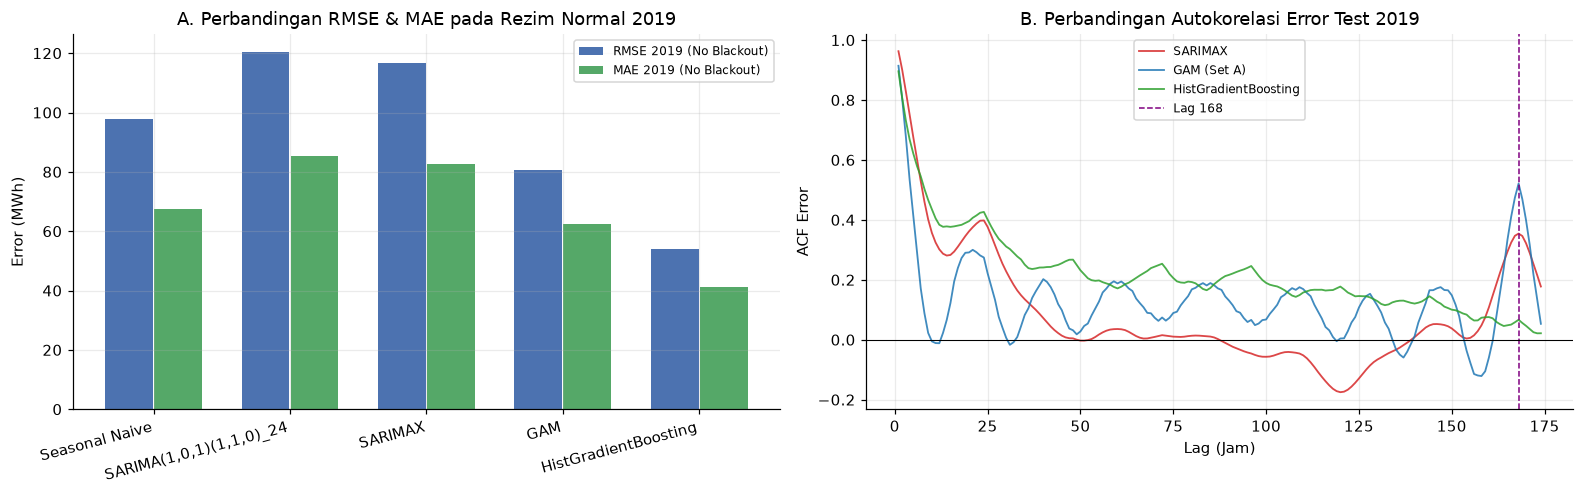

In [13]:
# Tahap 7: Evaluasi Komparatif Lengkap & Uji Signifikansi Diebold-Mariano
models_eval = [
    ("Seasonal Naive (Y_t-168)", "pred_naive", "Baseline", "Jangka Pendek (h=168j)"),
    ("SARIMA(1,0,1)(1,1,0)_24", "pred_sarima", "Statistik Univariat", "Jangka Pendek (h=168j)"),
    ("SARIMAX (Linear)", "pred_sarimax", "Statistik Multivariat", "Jangka Pendek (h=168j)"),
    ("GAM (Set A Eksogen)", "pred_gam", "Spline Non-Linear", "Jangka Panjang / Eksogen (1 thn)"),
    (f"{gbm_name} (Set B h=168)", "pred_gbm", "Gradient Boosted Trees", "Jangka Pendek (h=168j)"),
]

summary_rows = []
y_19_cln = df.loc[mask_2019_clean, "nat_demand"].values
pred_sx_19 = df.loc[mask_2019_clean, "pred_sarimax"].values
pred_nv_19 = df.loc[mask_2019_clean, "pred_naive"].values

for m_name, col, paradigm, horizon_cat in models_eval:
    m19_all = compute_metrics(df.loc[test_2019_mask, "nat_demand"], df.loc[test_2019_mask, col])
    m19_cln = compute_metrics(y_19_cln, df.loc[mask_2019_clean, col])
    m20_cov = compute_metrics(df.loc[lockdown_2020_mask, "nat_demand"], df.loc[lockdown_2020_mask, col])
    err_19 = y_19_cln - df.loc[mask_2019_clean, col].values
    lb_p = acorr_ljungbox(err_19, lags=[168], return_df=True).loc[168, "lb_pvalue"]
    _, arch_p, _, _ = het_arch(err_19, nlags=24)

    if col == "pred_sarimax":
        dm_sx_str = "Ref"
    else:
        dm_s, dm_p, _ = diebold_mariano_test(y_19_cln, pred_sx_19, df.loc[mask_2019_clean, col].values, h=168, loss_type="squared")
        dm_sx_str = f"{dm_s:+.2f} (p={dm_p:.2e})"

    if col == "pred_naive":
        dm_nv_str = "Ref"
    else:
        dm_s2, dm_p2, _ = diebold_mariano_test(y_19_cln, pred_nv_19, df.loc[mask_2019_clean, col].values, h=168, loss_type="squared")
        dm_nv_str = f"{dm_s2:+.2f} (p={dm_p2:.2e})"

    summary_rows.append({
        "Model": m_name,
        "Paradigma": paradigm,
        "Kategori_Forecast": horizon_cat,
        "MAE_2019_All": round(m19_all["MAE"], 2),
        "RMSE_2019_All": round(m19_all["RMSE"], 2),
        "MAE_2019_NoBO": round(m19_cln["MAE"], 2),
        "RMSE_2019_NoBO": round(m19_cln["RMSE"], 2),
        "MAPE_2019_NoBO_%": round(m19_cln["MAPE"], 2),
        "MAPE_MarJun2020_%": round(m20_cov["MAPE"], 2),
        "LjungBox_lag168_p": f"{lb_p:.2e}",
        "ARCH_LM_p": f"{arch_p:.2e}",
        "DM_vs_SARIMAX": dm_sx_str,
        "DM_vs_Naive": dm_nv_str,
    })

summary_df = pd.DataFrame(summary_rows)
print("=== TABEL PERBANDINGAN KOMPARATIF BACKTESTING (Catatan: DM > 0 berarti Model lebih baik dari Referensi) ===")
display(summary_df)

# Visualisasi Perbandingan Akhir: Bar Chart RMSE/MAE & ACF Residual
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))

x = np.arange(len(summary_df))
axes[0].bar(x - 0.18, summary_df["RMSE_2019_NoBO"], width=0.35, color="#4c72b0", label="RMSE 2019 (No Blackout)")
axes[0].bar(x + 0.18, summary_df["MAE_2019_NoBO"], width=0.35, color="#55a868", label="MAE 2019 (No Blackout)")
axes[0].set_xticks(x)
axes[0].set_xticklabels([m.split(" (")[0] for m in summary_df["Model"]], rotation=15, ha="right")
axes[0].set_ylabel("Error (MWh)")
axes[0].set_title("A. Perbandingan RMSE & MAE pada Rezim Normal 2019")
axes[0].legend(fontsize=8)

# ACF Error di lag 1..174 (SARIMAX vs GAM vs Boosting)
lags_show = np.arange(1, 175)
for lbl, col, color in [
    ("SARIMAX", "pred_sarimax", "#d62728"),
    ("GAM (Set A)", "pred_gam", "#1f77b4"),
    (gbm_name, "pred_gbm", "#2ca02c"),
]:
    e_vec = (df.loc[mask_2019_clean, "nat_demand"] - df.loc[mask_2019_clean, col]).values
    acf_e = acf(e_vec, nlags=175, fft=True)[1:175]
    axes[1].plot(lags_show, acf_e, label=lbl, color=color, lw=1.2, alpha=0.85)
axes[1].axvline(168, color="purple", ls="--", lw=1, label="Lag 168")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set_title("B. Perbandingan Autokorelasi Error Test 2019")
axes[1].set_xlabel("Lag (Jam)")
axes[1].set_ylabel("ACF Error")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Tahap 8: Hasil Forecasting Eksplisit ke Masa Depan (*Out-of-Dataset*: Jangka Pendek 7 Hari & Jangka Panjang 12 Bulan)

Seluruh hasil pada **Tahap 2–7** di atas adalah *out-of-sample backtesting* terhadap data historis `2019–Juni 2020`. Pada tahap ini, model solusi dilatih ulang hingga titik observasi terakhir (`2020-06-27 00:00:00`) untuk menghasilkan **proyeksi nyata ke masa depan (*out-of-dataset*)** yang dipisahkan tegas menjadi dua horizon:

1. **Forecasting Jangka Pendek (STLF — 7 Hari / `168` Jam: `2020-06-27 01:00` s.d. `2020-07-04 00:00`):**
   - Menggunakan **`HistGradientBoosting` / `LightGBM` (Set B)** yang di-refit pada seluruh data `2015–27 Jun 2020` (`nat_demand_clean_full`, ke-8 titik *blackout* diimputasi).
   - Seluruh fitur *lag* beban (`t-168`, `t-336`, `t-504`, statistik bergerak 168 jam) **100% berasal dari data aktual historis** tanpa rekursi berantai, menghasilkan prediksi titik (`L2`) beserta interval ketidakpastian 90% (`Q05–Q95`).
   - *Asumsi cuaca & kalender:* Cuaca `168` jam mendatang memakai *climatological weather baseline* (rata-rata historis `2015–2019` per `(month, day, hour)` dengan transisi lag suhu mulus dari 24 jam aktual terakhir); kalender akhir Juni–awal Juli mengikuti pola historis `2015–2020` (`holiday=0`, `Holiday_ID=0`, `school=1`).

2. **Forecasting Jangka Panjang (LTLF — 12 Bulan: `Juli 2020 – Juni 2021`, `8.760` Jam):**
   - Menggunakan **`GAM` (Set A eksogen murni, tanpa *lag* target)** karena tidak bergantung pada *lag* beban jangka pendek dan aman mengekstrapolasi tren makro + musiman tahunan + sensitivitas suhu pada horizon 1 tahun penuh.
   - Cuaca memakai klimatologi `2015–2019` per `(month, day, hour)`, sedangkan struktur kalender (`holiday`, `Holiday_ID`, `school`) dipetakan dari templat tahun normal penuh `2019`.
   - Disajikan dalam **2 skenario eksplisit** lengkap dengan interval kepercayaan 95%:
     - **Skenario A — Pemulihan Normal Pra-COVID:** menggunakan `res_gam_pre` (`Jan 2015 – Feb 2020`).
     - **Skenario B — Tekanan Pandemi Berkelanjutan (Rezim COVID-19):** melatih ulang GAM pada seluruh data `Jan 2015 – Jun 2020` dengan indikator rezim `is_covid_regime` (`datetime >= 2020-03-01`) dan mengevaluasi proyeksi dengan `is_covid_regime = 1`.

### Penjelasan Algoritma Matematis (Tahap 8A & 8B)
1. **Tahap 8A — Proyeksi Jangka Pendek Non-Rekursif ($h \in \{1,\dots,168\}$):**
   - Seluruh 8 titik *blackout* diimputasi ke dalam seri penuh $\tilde{Y}_t^{\text{full}}$, sehingga fitur *lag* pada waktu masa depan $T + h$ (dengan $T =$ `2020-06-27 00:00`) tetap merujuk murni ke data observasi historis ($T + h - 168 \le T$).
   - Kovariat cuaca masa depan memakai profil klimatologi historis:
     $$\bar{\mathbf{W}}_{(m,d,\text{hr})} = \frac{1}{5}\sum_{y=2015}^{2019} \mathbf{W}_{y,m,d,\text{hr}}$$
   - Prediksi titik $\hat{Y}_{T+h} = \hat{f}_{L_2}(\mathbf{z}_{T+h})$ disertai kuantil $\hat{Q}_\tau(\mathbf{z}_{T+h})$ yang diurutkan ulang (*quantile rearrangement*) agar monoton $\hat{Q}_{0.05} \le \hat{Q}_{0.50} \le \hat{Q}_{0.95}$.
2. **Tahap 8B — Proyeksi Jangka Panjang 12 Bulan (2 Skenario GAM):**
   - **Skenario A (Pemulihan Normal):** $\hat{Y}_t^{(A)} = \hat{f}_{\text{GAM, pra-COVID}}(\mathbf{X}_t^{\text{clim, cal}})$ beserta interval kepercayaan 95% posterior.
   - **Skenario B (Tekanan Pandemi Berkelanjutan):** Memperluas persamaan GAM penuh (`Jan 2015 – Jun 2020`) dengan parameter pergeseran rezim $\beta_{\text{COVID}}\,\mathbb{I}(t \ge \text{2020-03-01})$, lalu mengevaluasi proyeksi `Jul 2020 – Jun 2021` pada kondisi $\mathbb{I}_{\text{COVID}} = 1$.
   - Total energi bulanan dan tahunan dihitung lewat integrasi diskret per jam $E_m = \frac{1}{1000}\sum_{t \in m} \hat{Y}_t$ (dalam satuan GWh).

### Penjelasan Algoritma Kode (Sel 23 & Sel 24)
- **Sel 23 (Tahap 8A — Jangka Pendek 7 Hari / 168 Jam):**
  1. Membentuk `df["nat_demand_clean_full"]`, menyalin ke `df_full_b`, menghitung ulang fitur lag Set B, dan melatih ulang 4 model (`model_st_pt`, `model_st_q05`, `model_st_q50`, `model_st_q95`) pada `47.544` jam valid.
  2. Membentuk `future_st` sepanjang `168` jam via `pd.date_range`, menggabungkan `clim_mdh` (rata-rata cuaca `2015–2019`), menyambungkan 24 jam suhu aktual terakhir untuk `T2M_toc_lag1..3` dan `T2M_toc_roll24`, memproyeksikan `T2M_pca1` dengan `pca_t2m_sign`, dan menyambungkan 672 jam terakhir `nat_demand_clean_full` untuk menghitung *lag* beban Set B tanpa kebocoran/rekursi.
  3. Melakukan `assert` bebas `NaN`, memprediksi titik & kuantil, mengurutkan kuantil dengan `np.sort(..., axis=1)`, mencetak ringkasan 7 hari, menampilkan `st_daily_df` & `st_first24_df`, dan memplot 2 panel proyeksi jangka pendek.
- **Sel 24 (Tahap 8B — Jangka Panjang 12 Bulan):**
  1. Membentuk `future_lt` per jam dari `2020-06-27 01:00` hingga `2021-06-30 23:00`, menggabungkan klimatologi `clim_mdh` serta templat kalender penuh `2019` (`cal_19`), lalu membangun `time_index_years` kontinu, `pre/post_holiday`, `T2M_pca1`, dan 22 dummy `HolID_*`.
  2. Menghitung prediksi **Skenario A** melalui `res_gam_pre` (`gam_bounds_pre`), lalu memanggil `fit_panama_gam(..., extra_lin_cols=["is_covid_regime"], target_col="nat_demand_clean_full")` pada seluruh data untuk menghasilkan **Skenario B** (`res_gam_covid`).
  3. Mengambil irisan tepat `12` bulan penuh (`Jul 2020 – Jun 2021`, `8.760` jam), menampilkan tabel `lt_monthly_display` dan ringkasan tahunan vs aktual `2019`, serta memplot perbandingan bulanan (kurva rata-rata beban & batang energi GWh).

Refit penuh HistGradientBoosting (Jan 2015 - 27 Jun 2020, 47,544 jam) selesai dalam 46.96 detik.

=== HASIL FORECASTING JANGKA PENDEK (7 Hari / 168 Jam: 2020-06-27 01:00 s.d. 2020-07-04 00:00) ===
  Rata-rata Beban Prediksi : 1,107.01 MWh
  Minimum - Maksimum       : 911.11 s.d. 1,306.46 MWh
  Total Energi 7 Hari      : 185.98 GWh
  Rata-rata Lebar PI 90%   : 137.47 MWh

--- Ringkasan Harian Forecast Jangka Pendek ---


,Tanggal,Hari,Jumlah_Jam,Mean_MWh,Min_MWh,Peak_MWh,Q05_Mean,Q95_Mean,Total_GWh
0,2020-06-27,Sabtu,23,1062.82,911.11,1167.46,1026.06,1136.87,24.44
1,2020-06-28,Minggu,24,1056.76,911.75,1198.86,1003.61,1132.22,25.36
2,2020-06-29,Senin,24,1136.75,946.66,1291.49,1074.74,1219.10,27.28
3,2020-06-30,Selasa,24,1123.40,952.94,1283.19,1044.94,1198.88,26.96
4,2020-07-01,Rabu,24,1112.47,925.76,1300.24,1040.54,1192.36,26.70
5,2020-07-02,Kamis,24,1133.62,949.33,1306.46,1062.66,1207.34,27.21
6,2020-07-03,Jumat,24,1124.38,955.72,1260.17,1049.25,1177.19,26.99
7,2020-07-04,Sabtu,1,1035.03,1035.03,1035.03,966.89,1080.02,1.04



--- Cuplikan 24 Jam Pertama Forecast Jangka Pendek (2020-06-27 01:00 s.d. 2020-06-28 00:00) ---


,datetime,pred_st_mean,pred_st_q05,pred_st_q50,pred_st_q95
0,2020-06-27 01:00:00,1005.71,974.19,1022.33,1069.05
1,2020-06-27 02:00:00,979.59,941.99,996.24,1040.14
2,2020-06-27 03:00:00,952.44,925.58,969.44,1012.27
3,2020-06-27 04:00:00,932.29,920.75,950.22,989.98
4,2020-06-27 05:00:00,930.28,921.41,952.13,991.62
5,2020-06-27 06:00:00,911.11,898.00,930.87,969.66
6,2020-06-27 07:00:00,959.26,947.81,962.07,1018.80
7,2020-06-27 08:00:00,1028.43,996.66,1022.48,1082.71
8,2020-06-27 09:00:00,1062.34,1025.72,1062.34,1138.18
9,2020-06-27 10:00:00,1092.66,1072.39,1090.54,1182.45


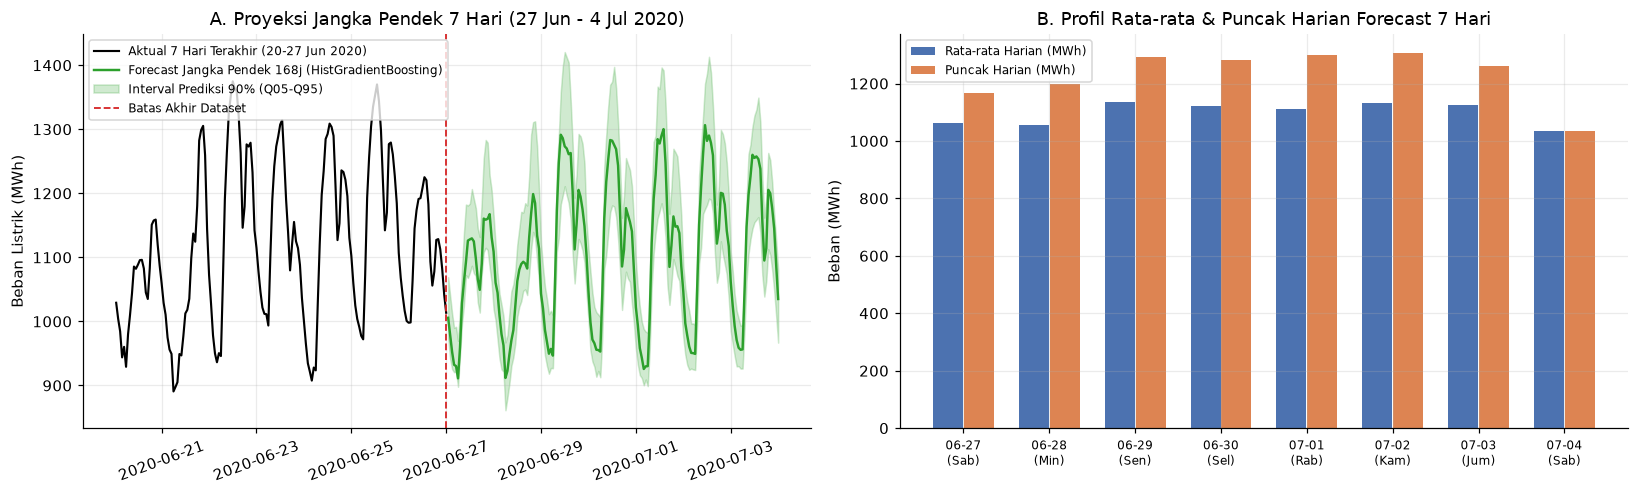

In [14]:
# Tahap 8A: Forecasting Jangka Pendek (STLF 7 Hari / 168 Jam: 2020-06-27 01:00 s.d. 2020-07-04 00:00)
# 1. Buat nat_demand_clean_full (mengimputasi seluruh 8 titik blackout agar lag historis bersih)
df["nat_demand_clean_full"] = df["nat_demand"].copy()
for idx in bo_indices:
    prev_val = df.loc[idx - 168, "nat_demand"] if idx - 168 >= 0 else np.nan
    next_val = df.loc[idx + 168, "nat_demand"] if idx + 168 < len(df) else np.nan
    df.loc[idx, "nat_demand_clean_full"] = np.nanmean([prev_val, next_val])

# Bangun ulang fitur lag Set B berbasis nat_demand_clean_full pada salinan penuh
df_full_b = df.copy()
s_full = df_full_b["nat_demand_clean_full"]
df_full_b["load_lag_168"] = s_full.shift(168)
df_full_b["load_lag_336"] = s_full.shift(336)
df_full_b["load_lag_504"] = s_full.shift(504)
df_full_b["load_roll168_mean"] = s_full.shift(168).rolling(168, min_periods=24).mean()
df_full_b["load_roll168_std"] = s_full.shift(168).rolling(168, min_periods=24).std()
df_full_b["load_roll24_max_lag168"] = s_full.shift(168).rolling(24, min_periods=1).max()

valid_full_b = df_full_b[set_b_features].notna().all(axis=1)
X_full_b = df_full_b.loc[valid_full_b, set_b_features]
y_full_b = df_full_b.loc[valid_full_b, "nat_demand_clean_full"]

t0 = time.time()
model_st_pt = make_gbm("squared")
model_st_q05 = make_gbm("quantile", alpha_q=0.05)
model_st_q50 = make_gbm("quantile", alpha_q=0.50)
model_st_q95 = make_gbm("quantile", alpha_q=0.95)

model_st_pt.fit(X_full_b, y_full_b)
model_st_q05.fit(X_full_b, y_full_b)
model_st_q50.fit(X_full_b, y_full_b)
model_st_q95.fit(X_full_b, y_full_b)
print(f"Refit penuh {gbm_name} (Jan 2015 - 27 Jun 2020, {len(X_full_b):,} jam) selesai dalam {time.time()-t0:.2f} detik.")

# 2. Bangun kerangka 168 jam ke depan dengan climatological weather baseline (2015-2019)
future_st_dt = pd.date_range(start=df["datetime"].max() + pd.Timedelta(hours=1), periods=168, freq="h")
future_st = pd.DataFrame({"datetime": future_st_dt})
future_st["month"] = future_st["datetime"].dt.month
future_st["day"] = future_st["datetime"].dt.day
future_st["hour_int"] = future_st["datetime"].dt.hour

clim_base = df[df["year"] <= 2019].copy()
clim_base["day"] = clim_base["datetime"].dt.day
clim_base["hour_int"] = clim_base["datetime"].dt.hour
clim_mdh = clim_base.groupby(["month", "day", "hour_int"], as_index=False)[weather_cols].mean()

future_st = future_st.merge(clim_mdh, on=["month", "day", "hour_int"], how="left")

# Transisi mulus lag suhu & roll24 dari 24 jam aktual terakhir
t2m_cont = pd.concat([df["T2M_toc"].iloc[-24:], future_st["T2M_toc"]], ignore_index=True)
for lag in [1, 2, 3]:
    future_st[f"T2M_toc_lag{lag}"] = t2m_cont.shift(lag).iloc[24:].values
future_st["T2M_toc_roll24"] = t2m_cont.rolling(24, min_periods=1).mean().iloc[24:].values
future_st["T2M_pca1"] = pca_t2m.transform(scaler_t2m.transform(future_st[t2m_cols])).ravel() * pca_t2m_sign

# Fitur waktu & kalender (akhir Juni - awal Juli: hari kerja/akhir pekan normal sekolah tanpa hari libur)
future_st["time_index_years"] = (len(df) + np.arange(len(future_st), dtype=float)) / 8760.0
future_st["hour"] = future_st["datetime"].dt.hour.astype(float)
future_st["day_of_week"] = future_st["datetime"].dt.dayofweek.astype(float)
future_st["is_weekend"] = (future_st["day_of_week"] >= 5).astype(float)
future_st["day_of_year"] = future_st["datetime"].dt.dayofyear.astype(float)
future_st["sin_hour"] = np.sin(2 * np.pi * future_st["hour"] / 24.0)
future_st["cos_hour"] = np.cos(2 * np.pi * future_st["hour"] / 24.0)
future_st["sin_dow"] = np.sin(2 * np.pi * future_st["day_of_week"] / 7.0)
future_st["cos_dow"] = np.cos(2 * np.pi * future_st["day_of_week"] / 7.0)
future_st["sin_doy"] = np.sin(2 * np.pi * future_st["day_of_year"] / 365.25)
future_st["cos_doy"] = np.cos(2 * np.pi * future_st["day_of_year"] / 365.25)
future_st["holiday"] = 0
future_st["Holiday_ID"] = 0
future_st["school"] = 1
future_st["pre_holiday"] = 0.0
future_st["post_holiday"] = 0.0

# Fitur lag beban historis 100% dari data aktual terakhir (tanpa rekursi)
tail_load = pd.concat([s_full.iloc[-672:], pd.Series(np.nan, index=range(168))], ignore_index=True)
future_st["load_lag_168"] = tail_load.shift(168).iloc[-168:].values
future_st["load_lag_336"] = tail_load.shift(336).iloc[-168:].values
future_st["load_lag_504"] = tail_load.shift(504).iloc[-168:].values
future_st["load_roll168_mean"] = tail_load.shift(168).rolling(168, min_periods=24).mean().iloc[-168:].values
future_st["load_roll168_std"] = tail_load.shift(168).rolling(168, min_periods=24).std().iloc[-168:].values
future_st["load_roll24_max_lag168"] = tail_load.shift(168).rolling(24, min_periods=1).max().iloc[-168:].values

X_future_st = future_st[set_b_features].copy()
for col in X_full_b.columns:
    X_future_st[col] = X_future_st[col].astype(X_full_b[col].dtype)
assert int(X_future_st.isna().sum().sum()) == 0, "Masih terdapat NaN pada fitur forecast jangka pendek!"

# 3. Prediksi Titik & Interval Kuantil 90%
future_st["pred_st_mean"] = model_st_pt.predict(X_future_st)
q_raw = np.column_stack([
    model_st_q05.predict(X_future_st),
    model_st_q50.predict(X_future_st),
    model_st_q95.predict(X_future_st),
])
q_sorted = np.sort(q_raw, axis=1)
future_st["pred_st_q05"] = q_sorted[:, 0]
future_st["pred_st_q50"] = q_sorted[:, 1]
future_st["pred_st_q95"] = q_sorted[:, 2]
future_st["pi_width_90"] = future_st["pred_st_q95"] - future_st["pred_st_q05"]

print("\n=== HASIL FORECASTING JANGKA PENDEK (7 Hari / 168 Jam: 2020-06-27 01:00 s.d. 2020-07-04 00:00) ===")
print(f"  Rata-rata Beban Prediksi : {future_st['pred_st_mean'].mean():,.2f} MWh")
print(f"  Minimum - Maksimum       : {future_st['pred_st_mean'].min():,.2f} s.d. {future_st['pred_st_mean'].max():,.2f} MWh")
print(f"  Total Energi 7 Hari      : {future_st['pred_st_mean'].sum() / 1000.0:,.2f} GWh")
print(f"  Rata-rata Lebar PI 90%   : {future_st['pi_width_90'].mean():,.2f} MWh")

# Ringkasan per tanggal (27 Jun - 4 Jul 2020)
day_names_id = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat", 5: "Sabtu", 6: "Minggu"}
future_st["Tanggal"] = future_st["datetime"].dt.date
future_st["Hari"] = future_st["datetime"].dt.dayofweek.map(day_names_id)
st_daily_df = (
    future_st.groupby(["Tanggal", "Hari"], sort=False)
    .agg(
        Jumlah_Jam=("pred_st_mean", "count"),
        Mean_MWh=("pred_st_mean", "mean"),
        Min_MWh=("pred_st_mean", "min"),
        Peak_MWh=("pred_st_mean", "max"),
        Q05_Mean=("pred_st_q05", "mean"),
        Q95_Mean=("pred_st_q95", "mean"),
        Total_GWh=("pred_st_mean", lambda s: s.sum() / 1000.0),
    )
    .reset_index()
)
for c in ["Mean_MWh", "Min_MWh", "Peak_MWh", "Q05_Mean", "Q95_Mean", "Total_GWh"]:
    st_daily_df[c] = st_daily_df[c].round(2)

print("\n--- Ringkasan Harian Forecast Jangka Pendek ---")
display(st_daily_df)

st_first24_df = future_st[["datetime", "pred_st_mean", "pred_st_q05", "pred_st_q50", "pred_st_q95"]].head(24).copy()
for c in ["pred_st_mean", "pred_st_q05", "pred_st_q50", "pred_st_q95"]:
    st_first24_df[c] = st_first24_df[c].round(2)
print("\n--- Cuplikan 24 Jam Pertama Forecast Jangka Pendek (2020-06-27 01:00 s.d. 2020-06-28 00:00) ---")
display(st_first24_df)

# Plot Forecasting Jangka Pendek
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

hist_7d = df.iloc[-168:]
axes[0].plot(hist_7d["datetime"], hist_7d["nat_demand"], color="black", lw=1.4, label="Aktual 7 Hari Terakhir (20-27 Jun 2020)")
axes[0].plot(future_st["datetime"], future_st["pred_st_mean"], color="#2ca02c", lw=1.6, label=f"Forecast Jangka Pendek 168j ({gbm_name})")
axes[0].fill_between(future_st["datetime"], future_st["pred_st_q05"], future_st["pred_st_q95"], color="#2ca02c", alpha=0.22, label="Interval Prediksi 90% (Q05-Q95)")
axes[0].axvline(df["datetime"].max(), color="#d62728", ls="--", lw=1.2, label="Batas Akhir Dataset")
axes[0].set_title("A. Proyeksi Jangka Pendek 7 Hari (27 Jun - 4 Jul 2020)")
axes[0].set_ylabel("Beban Listrik (MWh)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=8)

x_d = np.arange(len(st_daily_df))
axes[1].bar(x_d - 0.18, st_daily_df["Mean_MWh"], width=0.35, color="#4c72b0", label="Rata-rata Harian (MWh)")
axes[1].bar(x_d + 0.18, st_daily_df["Peak_MWh"], width=0.35, color="#dd8452", label="Puncak Harian (MWh)")
axes[1].set_xticks(x_d)
axes[1].set_xticklabels([f"{str(t)[5:]}\n({h[:3]})" for t, h in zip(st_daily_df["Tanggal"], st_daily_df["Hari"])], fontsize=8)
axes[1].set_ylabel("Beban (MWh)")
axes[1].set_title("B. Profil Rata-rata & Puncak Harian Forecast 7 Hari")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

Koefisien Rezim COVID-19 pada GAM Penuh (Jan 2015 - Jun 2020): -177.44 MWh (p = 0.00e+00)

=== HASIL FORECASTING JANGKA PANJANG 12 BULAN (Juli 2020 - Juni 2021, 8.760 Jam) ===


,Bulan,Jam,Normal_Mean_MWh,Normal_CI95_MWh,Normal_Energi_GWh,COVID_Mean_MWh,COVID_Energi_GWh,Selisih_GWh
0,2020-07,744,1287.10,"[1,283.1, 1,291.1]",957.60,1108.29,824.57,-133.03
1,2020-08,744,1267.41,"[1,262.9, 1,271.9]",942.95,1090.57,811.39,-131.57
2,2020-09,720,1280.45,"[1,276.2, 1,284.7]",921.93,1104.13,794.98,-126.95
3,2020-10,744,1269.31,"[1,265.1, 1,273.5]",944.36,1090.28,811.17,-133.20
4,2020-11,720,1242.01,"[1,235.7, 1,248.3]",894.24,1066.29,767.73,-126.52
5,2020-12,744,1300.58,"[1,293.8, 1,307.3]",967.63,1123.73,836.06,-131.58
6,2021-01,744,1267.92,"[1,262.2, 1,273.6]",943.33,1091.40,812.00,-131.33
7,2021-02,672,1298.49,"[1,293.9, 1,303.0]",872.58,1126.64,757.10,-115.48
8,2021-03,744,1303.35,"[1,297.0, 1,309.7]",969.69,1136.18,845.32,-124.37
9,2021-04,720,1329.13,"[1,322.9, 1,335.3]",956.97,1144.12,823.77,-133.20



Ringkasan Tahunan (Jul 2020 - Jun 2021 vs Referensi Aktual 2019):
  Referensi Aktual 2019          : Mean 1,243.58 MWh | Total 10,893.77 GWh (10.894 TWh)
  Skenario A (Pemulihan Normal)  : Mean 1,291.65 MWh | Peak 1,617.27 MWh | Total 11,314.86 GWh (11.315 TWh)
  Skenario B (Tekanan COVID-19)  : Mean 1,114.34 MWh | Peak 1,438.98 MWh | Total 9,761.60 GWh (9.762 TWh)
  Selisih Antar-Skenario (B - A) : -1,553.26 GWh (-13.73%)


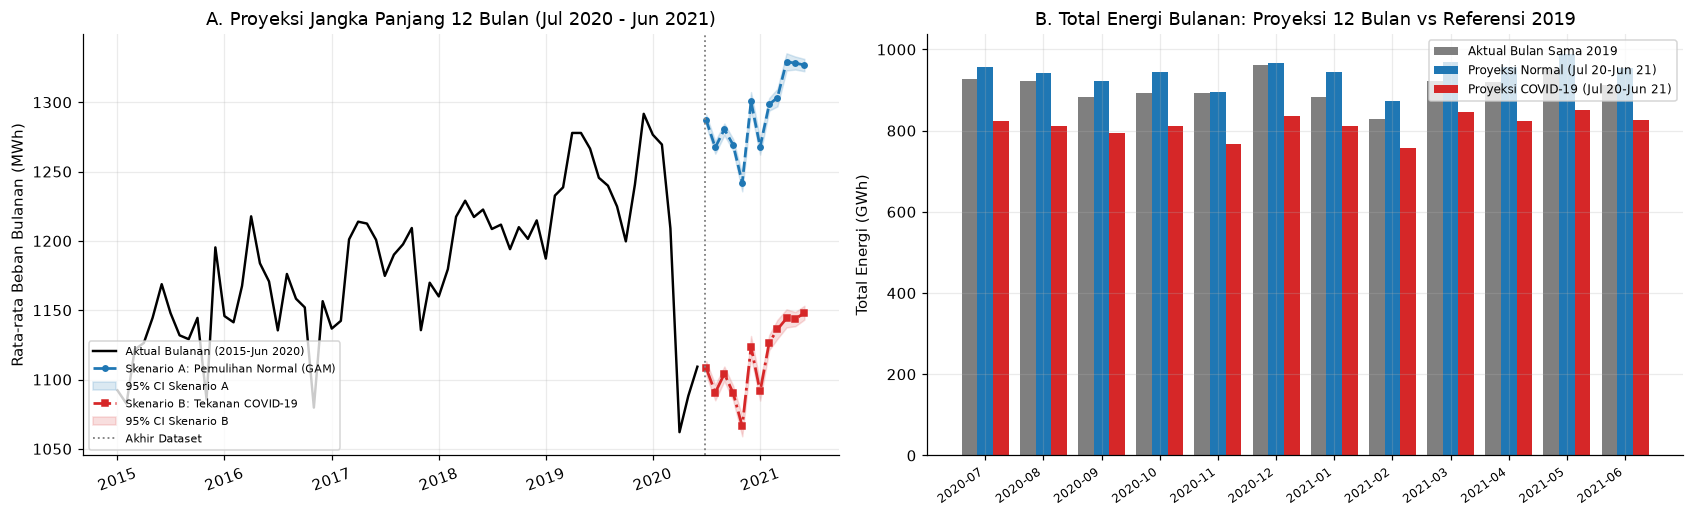

In [15]:
# Tahap 8B: Forecasting Jangka Panjang (LTLF 12 Bulan: Juli 2020 - Juni 2021)
# 1. Bangun kerangka waktu per jam dari 2020-06-27 01:00 s.d. 2021-06-30 23:00
future_lt_dt = pd.date_range(start=df["datetime"].max() + pd.Timedelta(hours=1), end="2021-06-30 23:00:00", freq="h")
future_lt = pd.DataFrame({"datetime": future_lt_dt})
future_lt["month"] = future_lt["datetime"].dt.month
future_lt["day"] = future_lt["datetime"].dt.day
future_lt["hour_int"] = future_lt["datetime"].dt.hour

# Klimatologi cuaca 2015-2019 per (month, day, hour)
future_lt = future_lt.merge(clim_mdh, on=["month", "day", "hour_int"], how="left")

# Templat kalender 1 tahun penuh dari tahun normal 2019 per (month, day, hour)
cal_19 = df[df["year"] == 2019].copy()
cal_19["day"] = cal_19["datetime"].dt.day
cal_19["hour_int"] = cal_19["datetime"].dt.hour
cal_19 = cal_19[["month", "day", "hour_int", "holiday", "Holiday_ID", "school"]].drop_duplicates(subset=["month", "day", "hour_int"])
future_lt = future_lt.merge(cal_19, on=["month", "day", "hour_int"], how="left")
assert int(future_lt[["T2M_toc", "QV2M_toc", "holiday", "Holiday_ID", "school"]].isna().sum().sum()) == 0, "NaN pada template klimatologi/kalender jangka panjang!"

# Fitur waktu, siklikal, pre/post_holiday, PCA suhu, dan dummy Holiday_ID (selaras Set A)
future_lt["time_index_years"] = (future_lt["datetime"] - df["datetime"].iloc[0]).dt.total_seconds() / 3600.0 / 8760.0
future_lt["hour"] = future_lt["datetime"].dt.hour.astype(float)
future_lt["day_of_week"] = future_lt["datetime"].dt.dayofweek.astype(float)
future_lt["is_weekend"] = (future_lt["day_of_week"] >= 5).astype(float)
future_lt["day_of_year"] = future_lt["datetime"].dt.dayofyear.astype(float)
future_lt["sin_hour"] = np.sin(2 * np.pi * future_lt["hour"] / 24.0)
future_lt["cos_hour"] = np.cos(2 * np.pi * future_lt["hour"] / 24.0)
future_lt["sin_dow"] = np.sin(2 * np.pi * future_lt["day_of_week"] / 7.0)
future_lt["cos_dow"] = np.cos(2 * np.pi * future_lt["day_of_week"] / 7.0)

daily_hol_lt = future_lt.groupby(future_lt["datetime"].dt.date)["holiday"].max()
pre_lt = set(pd.Series(daily_hol_lt.index)[daily_hol_lt.shift(-1, fill_value=0).values == 1])
post_lt = set(pd.Series(daily_hol_lt.index)[daily_hol_lt.shift(1, fill_value=0).values == 1])
future_lt["pre_holiday"] = future_lt["datetime"].dt.date.isin(pre_lt).astype(float)
future_lt["post_holiday"] = future_lt["datetime"].dt.date.isin(post_lt).astype(float)

future_lt["T2M_pca1"] = pca_t2m.transform(scaler_t2m.transform(future_lt[t2m_cols])).ravel() * pca_t2m_sign
future_lt["T2M_pca1_x_cos_hour"] = future_lt["T2M_pca1"] * future_lt["cos_hour"]
future_lt["T2M_pca1_x_sin_hour"] = future_lt["T2M_pca1"] * future_lt["sin_hour"]

for col in hol_dummy_cols:
    hol_id_val = int(col.split("_")[1])
    future_lt[col] = (future_lt["Holiday_ID"] == hol_id_val).astype(float)

# 2. Skenario A: Baseline / Pemulihan Normal Pra-COVID (menggunakan res_gam_pre dari Jan 2015 - Feb 2020)
ex_lin_lt_a, ex_sm_lt_a = build_gam_inputs(future_lt, clip_bounds=gam_bounds_pre)
sf_lt_a = res_gam_pre.get_prediction(exog=ex_lin_lt_a[gam_cols_pre], exog_smooth=ex_sm_lt_a).summary_frame()
future_lt["lt_base_mean"] = sf_lt_a["mean"].values
future_lt["lt_base_lo"] = sf_lt_a["mean_ci_lower"].values
future_lt["lt_base_hi"] = sf_lt_a["mean_ci_upper"].values

# 3. Skenario B: Tekanan Pandemi Berkelanjutan (refit GAM pada Jan 2015 - Jun 2020 dengan indikator is_covid_regime)
df_lt_fit = df.copy()
df_lt_fit["is_covid_regime"] = (df_lt_fit["datetime"] >= covid_start_dt).astype(float)
res_gam_covid, gam_bounds_cov, gam_cols_cov = fit_panama_gam(
    pd.Series(True, index=df_lt_fit.index),
    extra_lin_cols=["is_covid_regime"],
    target_col="nat_demand_clean_full",
    df_source=df_lt_fit,
)
cov_coef = float(res_gam_covid.params["is_covid_regime"])
cov_pval = float(res_gam_covid.pvalues["is_covid_regime"])
print(f"Koefisien Rezim COVID-19 pada GAM Penuh (Jan 2015 - Jun 2020): {cov_coef:+.2f} MWh (p = {cov_pval:.2e})")

future_lt["is_covid_regime"] = 1.0
ex_lin_lt_b, ex_sm_lt_b = build_gam_inputs(future_lt, clip_bounds=gam_bounds_cov, extra_lin_cols=["is_covid_regime"])
sf_lt_b = res_gam_covid.get_prediction(exog=ex_lin_lt_b[gam_cols_cov], exog_smooth=ex_sm_lt_b).summary_frame()
future_lt["lt_cov_mean"] = sf_lt_b["mean"].values
future_lt["lt_cov_lo"] = sf_lt_b["mean_ci_lower"].values
future_lt["lt_cov_hi"] = sf_lt_b["mean_ci_upper"].values

# 4. Ringkasan 12 Bulan Penuh (Juli 2020 - Juni 2021 = 8.760 jam)
lt_12m = future_lt[future_lt["datetime"] >= "2020-07-01 00:00:00"].copy()
lt_12m["Bulan"] = lt_12m["datetime"].dt.to_period("M").astype(str)
lt_monthly_df = (
    lt_12m.groupby("Bulan", sort=False)
    .agg(
        Jam=("lt_base_mean", "count"),
        Normal_Mean_MWh=("lt_base_mean", "mean"),
        Normal_CI_Lo=("lt_base_lo", "mean"),
        Normal_CI_Hi=("lt_base_hi", "mean"),
        Normal_Energi_GWh=("lt_base_mean", lambda s: s.sum() / 1000.0),
        COVID_Mean_MWh=("lt_cov_mean", "mean"),
        COVID_Energi_GWh=("lt_cov_mean", lambda s: s.sum() / 1000.0),
    )
    .reset_index()
)
lt_monthly_df["Selisih_GWh"] = lt_monthly_df["COVID_Energi_GWh"] - lt_monthly_df["Normal_Energi_GWh"]
lt_monthly_df["Normal_CI95_MWh"] = [f"[{lo:,.1f}, {hi:,.1f}]" for lo, hi in zip(lt_monthly_df["Normal_CI_Lo"], lt_monthly_df["Normal_CI_Hi"])]
for c in ["Normal_Mean_MWh", "Normal_Energi_GWh", "COVID_Mean_MWh", "COVID_Energi_GWh", "Selisih_GWh"]:
    lt_monthly_df[c] = lt_monthly_df[c].round(2)

lt_monthly_display = lt_monthly_df[["Bulan", "Jam", "Normal_Mean_MWh", "Normal_CI95_MWh", "Normal_Energi_GWh", "COVID_Mean_MWh", "COVID_Energi_GWh", "Selisih_GWh"]]

print("\n=== HASIL FORECASTING JANGKA PANJANG 12 BULAN (Juli 2020 - Juni 2021, 8.760 Jam) ===")
display(lt_monthly_display)

norm_tot_gwh = lt_12m["lt_base_mean"].sum() / 1000.0
cov_tot_gwh = lt_12m["lt_cov_mean"].sum() / 1000.0
actual_19_gwh = df.loc[test_2019_mask, "nat_demand"].sum() / 1000.0
actual_19_mean = df.loc[test_2019_mask, "nat_demand"].mean()

print(f"\nRingkasan Tahunan (Jul 2020 - Jun 2021 vs Referensi Aktual 2019):")
print(f"  Referensi Aktual 2019          : Mean {actual_19_mean:,.2f} MWh | Total {actual_19_gwh:,.2f} GWh ({actual_19_gwh/1000.0:.3f} TWh)")
print(f"  Skenario A (Pemulihan Normal)  : Mean {lt_12m['lt_base_mean'].mean():,.2f} MWh | Peak {lt_12m['lt_base_mean'].max():,.2f} MWh | Total {norm_tot_gwh:,.2f} GWh ({norm_tot_gwh/1000.0:.3f} TWh)")
print(f"  Skenario B (Tekanan COVID-19)  : Mean {lt_12m['lt_cov_mean'].mean():,.2f} MWh | Peak {lt_12m['lt_cov_mean'].max():,.2f} MWh | Total {cov_tot_gwh:,.2f} GWh ({cov_tot_gwh/1000.0:.3f} TWh)")
print(f"  Selisih Antar-Skenario (B - A) : {cov_tot_gwh - norm_tot_gwh:,.2f} GWh ({(cov_tot_gwh - norm_tot_gwh)/norm_tot_gwh*100.0:+.2f}%)")

# Plot Forecasting Jangka Panjang 12 Bulan
fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

# Panel A: Historis bulanan (2015-01 s.d. 2020-06) + proyeksi 12 bulan (2020-07 s.d. 2021-06)
hist_m = df.set_index("datetime")["nat_demand"].resample("MS").mean()
lt_m = lt_12m.set_index("datetime")[["lt_base_mean", "lt_base_lo", "lt_base_hi", "lt_cov_mean", "lt_cov_lo", "lt_cov_hi"]].resample("MS").mean()

axes[0].plot(hist_m.index, hist_m.values, color="black", lw=1.6, label="Aktual Bulanan (2015-Jun 2020)")
axes[0].plot(lt_m.index, lt_m["lt_base_mean"], color="#1f77b4", ls="--", lw=1.8, marker="o", ms=3.5, label="Skenario A: Pemulihan Normal (GAM)")
axes[0].fill_between(lt_m.index, lt_m["lt_base_lo"], lt_m["lt_base_hi"], color="#1f77b4", alpha=0.16, label="95% CI Skenario A")
axes[0].plot(lt_m.index, lt_m["lt_cov_mean"], color="#d62728", ls="-.", lw=1.8, marker="s", ms=3.5, label="Skenario B: Tekanan COVID-19")
axes[0].fill_between(lt_m.index, lt_m["lt_cov_lo"], lt_m["lt_cov_hi"], color="#d62728", alpha=0.15, label="95% CI Skenario B")
axes[0].axvline(pd.Timestamp("2020-06-27"), color="gray", ls=":", lw=1.2, label="Akhir Dataset")
axes[0].set_title("A. Proyeksi Jangka Panjang 12 Bulan (Jul 2020 - Jun 2021)")
axes[0].set_ylabel("Rata-rata Beban Bulanan (MWh)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=7.5, loc="lower left")

# Panel B: Perbandingan Energi Bulanan (GWh) vs Bulan yang Sama Tahun 2019
ref_19_m = df.loc[test_2019_mask].groupby("month")["nat_demand"].sum() / 1000.0
lt_12m_months = lt_12m.groupby("Bulan", sort=False)["month"].first().values
ref_19_aligned = [ref_19_m.loc[m] for m in lt_12m_months]

xm = np.arange(len(lt_monthly_df))
w = 0.27
axes[1].bar(xm - w, ref_19_aligned, width=w, color="#7f7f7f", label="Aktual Bulan Sama 2019")
axes[1].bar(xm, lt_monthly_df["Normal_Energi_GWh"], width=w, color="#1f77b4", label="Proyeksi Normal (Jul 20-Jun 21)")
axes[1].bar(xm + w, lt_monthly_df["COVID_Energi_GWh"], width=w, color="#d62728", label="Proyeksi COVID-19 (Jul 20-Jun 21)")
axes[1].set_xticks(xm)
axes[1].set_xticklabels(lt_monthly_df["Bulan"], rotation=35, ha="right", fontsize=8)
axes[1].set_ylabel("Total Energi (GWh)")
axes[1].set_title("B. Total Energi Bulanan: Proyeksi 12 Bulan vs Referensi 2019")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Tahap 9: Eksperimen Transfer Learning Antar-Rezim (Pra-Pandemi → Adaptasi COVID-19 2020)

Saat pandemi COVID-19 memicu perubahan struktur konsumsi listrik sejak pertengahan Maret 2020 (*regime / domain shift*), model yang hanya dilatih pada kondisi normal pra-pandemi mengalami lonjakan error akibat pergeseran distribusi target $P_T(Y \mid \mathbf{X}) \neq P_S(Y \mid \mathbf{X})$. Pada tahap ini diterapkan **Domain Transfer Learning** menggunakan 22 fitur eksogen murni (tanpa *lag* beban) dengan pembagian kronologis bebas *data leakage*:
- **Source Domain ($\mathcal{D}_S$):** Data pra-lockdown hingga `2020-03-15 23:00` (`45.575` jam, target bersih `nat_demand_clean_full`).
- **Target Adaptation Set ($\mathcal{D}_T^{\text{adapt}}$):** `1` bulan awal *lockdown* (`2020-03-16 00:00` s.d. `2020-04-15 23:00`, hanya `744` jam = `1,63%` dari data sumber).
- **Target Evaluation Set ($\mathcal{D}_T^{\text{test}}$):** Sisa periode *lockdown* (`2020-04-16 00:00` s.d. `2020-06-27 00:00`, `1.729` jam).

### Penjelasan Algoritma Matematis (Tahap 9)
Tiga paradigma *Transfer Learning* dibandingkan terhadap *Direct Transfer* (tanpa adaptasi) dan *Target-Only Scratch* (latih dari nol di `744` jam target):

1. **TL-1 — Neural Network Parameter Fine-Tuning (`MLPRegressor` `warm_start=True`):**
   Bobot representasi sumber $\Theta_S = \{(\mathbf{W}_S^{(l)}, \mathbf{b}_S^{(l)})\}$ beserta skala fitur beku $\mu_S, \sigma_S$ dari $\mathcal{D}_S$ diinisialisasi ulang lalu di-*fine-tune* pada $\mathcal{D}_T^{\text{adapt}}$ dengan laju belajar lebih kecil ($\eta_{\text{FT}} = 8\times 10^{-4} < \eta_S$) dan regularisasi $L_2$:
   $$\Theta_T = \arg\min_{\Theta} \frac{1}{|\mathcal{D}_T^{\text{adapt}}|} \sum_{t \in \mathcal{D}_T^{\text{adapt}}} \bigl(y_t - f_{\Theta}(\tilde{\mathbf{x}}_t)\bigr)^2 + \alpha \|\Theta\|_2^2, \quad \Theta^{(0)} = \Theta_S$$
2. **TL-2 — Tree-Based Warm-Start Transfer (`HistGradientBoostingRegressor` `warm_start=True`):**
   Ansambel $M_S = 180$ pohon yang telah mempelajari respons cuaca & kalender dari `5` tahun data sumber diperluas dengan $K = 60$ pohon residu baru pada $\mathcal{D}_T^{\text{adapt}}$:
   $$\hat{F}_T(\mathbf{x}_t) = \underbrace{\sum_{m=1}^{M_S} \nu_S h_m(\mathbf{x}_t)}_{\text{Pengetahuan Sumber } \mathcal{D}_S} + \underbrace{\sum_{m=M_S+1}^{M_S+K} \nu_T h_m^{\text{adapt}}(\mathbf{x}_t)}_{\text{Adaptasi Rezim Target } \mathcal{D}_T^{\text{adapt}}}$$
3. **TL-3 — Frozen Backbone + Residual Adapter Transfer (`Frozen GAM + Ridge Adapter`):**
   Model `GAM` pra-COVID dipertahankan beku sebagai *backbone* $\hat{f}_S(\mathbf{x}_t)$ (`cf_mean`), kemudian *adapter* linear berregularisasi (`Ridge`) dilatih untuk memetakan pergeseran residual $r_t = y_t - \hat{f}_S(\mathbf{x}_t)$ terhadap fitur intraharian, akhir pekan, hari libur, sekolah, suhu PCA, dan kelembapan:
   $$\hat{y}_t^{\text{TL-3}} = \hat{f}_S(\mathbf{x}_t) + \hat{g}_T(\mathbf{z}_t), \qquad \hat{\boldsymbol{\beta}} = \arg\min_{\boldsymbol{\beta}} \sum_{t \in \mathcal{D}_T^{\text{adapt}}} (r_t - \mathbf{z}_t^\top \boldsymbol{\beta})^2 + \lambda \|\boldsymbol{\beta}\|_2^2$$

### Penjelasan Algoritma Kode (Tahap 9)
1. Menambahkan fitur siklikal harmonik (`sin_hour`, `cos_hour`, `sin_2hour`, `cos_2hour`, `sin_dow`, `cos_dow`, `sin_doy`, `cos_doy`) dan menyusun matriks `22` fitur eksogen seragam.
2. Melatih 2 model *Direct Transfer* (`Boosting Source` & `MLP Source`) serta 1 model *Target-Only Scratch* (`744` jam) sebagai pembanding.
3. Menerapkan `copy.deepcopy` + `warm_start=True` (`early_stopping=False`) untuk **TL-1 (MLP)** dan **TL-2 (Boosting)** serta `Ridge(alpha=15.0)` residual adapter di atas `cf_mean` untuk **TL-3**.
4. Mengevaluasi `MAE`, `RMSE`, `MAPE_%`, `Bias_MWh`, dan `% Reduksi RMSE` pada `1.729` jam masa uji *lockdown*, lalu memplot perbandingan skor & kurva harian.


Split Transfer Learning -> Source: 45,575 jam | Adapt: 744 jam | Test: 1,729 jam
                                    Model          Kategori    MAE   RMSE  MAPE_%  Bias_MWh  Reduksi_RMSE_vs_Direct_%
TL-2: Tree Warm-Start Transfer (Boosting) Transfer Learning  56.28  73.88    5.07     -7.60                     57.64
       TL-1: Neural Net Fine-Tuning (MLP) Transfer Learning  62.23  79.35    5.74     35.63                     54.50
          Latih dari Nol di Target (744j)    Tanpa Transfer  70.11  92.28    6.13    -56.60                     47.09
      TL-3: Frozen GAM + Residual Adapter Transfer Learning  94.44 116.46    8.48    -79.47                     33.23
         Tanpa Adaptasi (Boosting Source)    Tanpa Adaptasi 133.77 174.41   12.08    123.15                      0.00
              Tanpa Adaptasi (MLP Source)    Tanpa Adaptasi 135.29 175.07   12.22    126.04                     -0.38


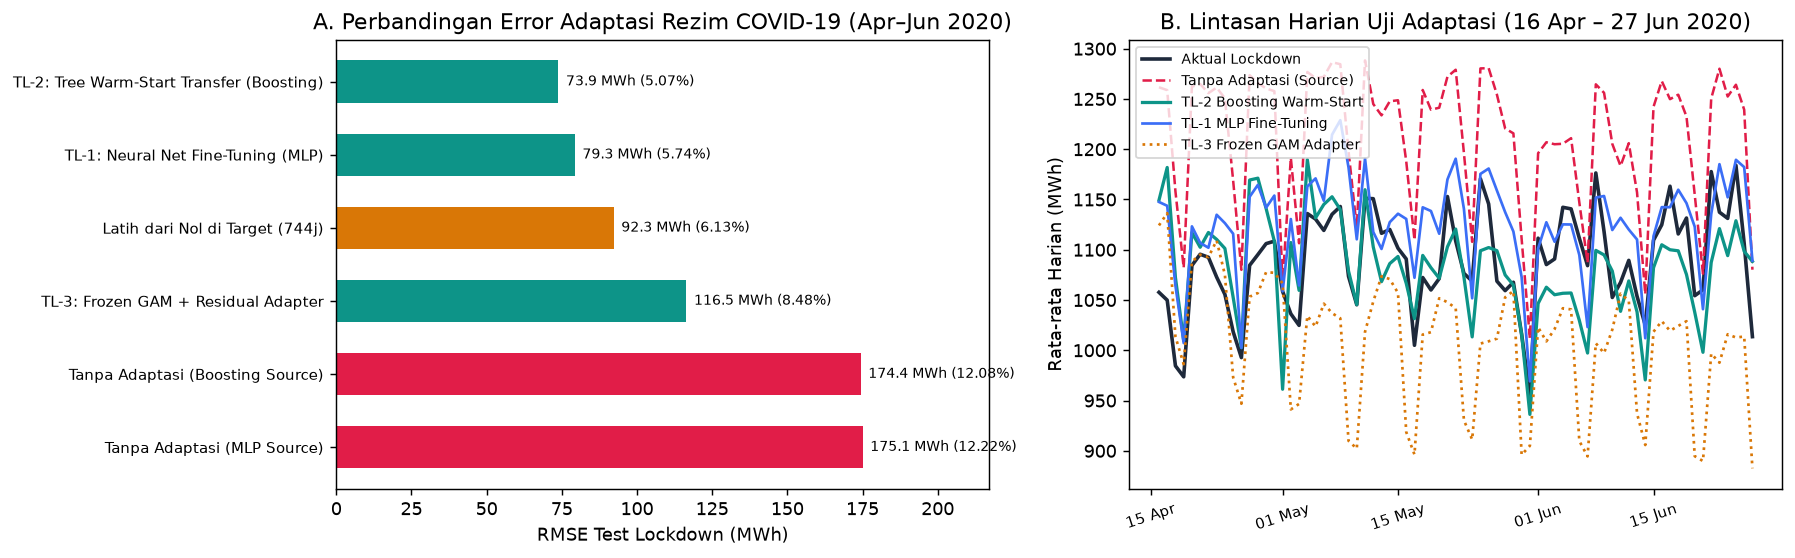

In [25]:
# Tahap 9: Eksperimen Transfer Learning Antar-Rezim (Pra-Pandemi -> Adaptasi COVID-19 2020)
import copy
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Gunakan df dari notebook jika sudah tersedia, atau muat dari artifacts/master_hourly.parquet
if "df" in globals() and {"cf_mean", "T2M_pca1", "nat_demand_clean_full"}.issubset(df.columns):
    df_tl = df.copy()
else:
    df_tl = pd.read_parquet("artifacts/master_hourly.parquet")

df_tl["datetime"] = pd.to_datetime(df_tl["datetime"])
df_tl["sin_hour"] = np.sin(2 * np.pi * df_tl["hour"] / 24.0)
df_tl["cos_hour"] = np.cos(2 * np.pi * df_tl["hour"] / 24.0)
df_tl["sin_2hour"] = np.sin(4 * np.pi * df_tl["hour"] / 24.0)
df_tl["cos_2hour"] = np.cos(4 * np.pi * df_tl["hour"] / 24.0)
df_tl["sin_dow"] = np.sin(2 * np.pi * df_tl["day_of_week"] / 7.0)
df_tl["cos_dow"] = np.cos(2 * np.pi * df_tl["day_of_week"] / 7.0)
df_tl["sin_doy"] = np.sin(2 * np.pi * df_tl["day_of_year"] / 365.25)
df_tl["cos_doy"] = np.cos(2 * np.pi * df_tl["day_of_year"] / 365.25)

tl_exog_cols = [
    "hour", "sin_hour", "cos_hour",
    "day_of_week", "sin_dow", "cos_dow", "is_weekend",
    "sin_doy", "cos_doy", "holiday", "school",
    "T2M_toc", "QV2M_toc", "TQL_toc", "W2M_toc",
    "T2M_san", "QV2M_san", "TQL_san", "W2M_san",
    "T2M_dav", "QV2M_dav", "T2M_pca1",
]
tl_adapter_cols = [
    "sin_hour", "cos_hour", "sin_2hour", "cos_2hour",
    "is_weekend", "holiday", "school", "T2M_pca1", "QV2M_toc",
]

src_tl = df_tl[df_tl["datetime"] <= "2020-03-15 23:00:00"]
adapt_tl = df_tl[(df_tl["datetime"] >= "2020-03-16 00:00:00") & (df_tl["datetime"] <= "2020-04-15 23:00:00")]
test_tl = df_tl[df_tl["datetime"] >= "2020-04-16 00:00:00"]

X_src_tl, y_src_tl = src_tl[tl_exog_cols].to_numpy(float), src_tl["nat_demand_clean_full"].to_numpy(float)
X_adp_tl, y_adp_tl = adapt_tl[tl_exog_cols].to_numpy(float), adapt_tl["nat_demand"].to_numpy(float)
X_tst_tl, y_tst_tl = test_tl[tl_exog_cols].to_numpy(float), test_tl["nat_demand"].to_numpy(float)

# 1. Baseline Direct Transfer (Boosting & MLP Source-Only) + Target-Only Scratch
gbm_src_tl = HistGradientBoostingRegressor(max_iter=180, max_depth=6, learning_rate=0.06, early_stopping=False, random_state=42)
gbm_src_tl.fit(X_src_tl, y_src_tl)
pred_direct_gbm = gbm_src_tl.predict(X_tst_tl)

sc_tl = StandardScaler()
X_src_sc, X_adp_sc, X_tst_sc = sc_tl.fit_transform(X_src_tl), sc_tl.transform(X_adp_tl), sc_tl.transform(X_tst_tl)
mlp_src_tl = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=60, learning_rate_init=3e-3, early_stopping=False, random_state=42)
mlp_src_tl.fit(X_src_sc, y_src_tl)
pred_direct_mlp = mlp_src_tl.predict(X_tst_sc)

gbm_scratch_tl = HistGradientBoostingRegressor(max_iter=120, max_depth=5, learning_rate=0.06, early_stopping=False, random_state=42)
gbm_scratch_tl.fit(X_adp_tl, y_adp_tl)
pred_scratch_gbm = gbm_scratch_tl.predict(X_tst_tl)

# 2. TL-1: Neural Net Parameter Fine-Tuning (MLP warm_start)
mlp_ft_tl = copy.deepcopy(mlp_src_tl)
if getattr(mlp_ft_tl, "best_loss_", None) is None:
    mlp_ft_tl.best_loss_ = float(mlp_ft_tl.loss_)
mlp_ft_tl.set_params(warm_start=True, early_stopping=False, learning_rate_init=8e-4, alpha=1e-2, max_iter=mlp_src_tl.n_iter_ + 25)
mlp_ft_tl.fit(X_adp_sc, y_adp_tl)
pred_tl_mlp = mlp_ft_tl.predict(X_tst_sc)

# 3. TL-2: Tree-Based Warm-Start Transfer (Boosting warm_start)
gbm_ft_tl = copy.deepcopy(gbm_src_tl)
gbm_ft_tl.set_params(warm_start=True, early_stopping=False, learning_rate=0.05, max_iter=gbm_src_tl.n_iter_ + 60)
gbm_ft_tl.fit(X_adp_tl, y_adp_tl)
pred_tl_gbm = gbm_ft_tl.predict(X_tst_tl)

# 4. TL-3: Frozen GAM Backbone + Ridge Residual Adapter
res_adp = y_adp_tl - adapt_tl["cf_mean"].to_numpy(float)
adapter_tl = Pipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=15.0))])
adapter_tl.fit(adapt_tl[tl_adapter_cols].to_numpy(float), res_adp)
pred_tl_gam = test_tl["cf_mean"].to_numpy(float) + adapter_tl.predict(test_tl[tl_adapter_cols].to_numpy(float))

ref_rmse_tl = float(np.sqrt(np.mean((y_tst_tl - pred_direct_gbm) ** 2)))
tl_rows = []
for lbl, kat, pred in [
    ("Tanpa Adaptasi (Boosting Source)", "Tanpa Adaptasi", pred_direct_gbm),
    ("Tanpa Adaptasi (MLP Source)", "Tanpa Adaptasi", pred_direct_mlp),
    ("Latih dari Nol di Target (744j)", "Tanpa Transfer", pred_scratch_gbm),
    ("TL-1: Neural Net Fine-Tuning (MLP)", "Transfer Learning", pred_tl_mlp),
    ("TL-2: Tree Warm-Start Transfer (Boosting)", "Transfer Learning", pred_tl_gbm),
    ("TL-3: Frozen GAM + Residual Adapter", "Transfer Learning", pred_tl_gam),
]:
    err = y_tst_tl - pred
    rmse_v = float(np.sqrt(np.mean(err ** 2)))
    tl_rows.append({
        "Model": lbl,
        "Kategori": kat,
        "MAE": round(float(np.mean(np.abs(err))), 2),
        "RMSE": round(rmse_v, 2),
        "MAPE_%": round(float(np.mean(np.abs(err / y_tst_tl)) * 100.0), 2),
        "Bias_MWh": round(float(np.mean(pred - y_tst_tl)), 2),
        "Reduksi_RMSE_vs_Direct_%": round((ref_rmse_tl - rmse_v) / ref_rmse_tl * 100.0, 2),
    })

tl_summary_df = pd.DataFrame(tl_rows).sort_values("RMSE").reset_index(drop=True)
print(f"Split Transfer Learning -> Source: {len(src_tl):,} jam | Adapt: {len(adapt_tl)} jam | Test: {len(test_tl):,} jam")
print(tl_summary_df.to_string(index=False))

# Visualisasi 2 Panel Tahap 9
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
clrs_tl = ["#0D9488" if k == "Transfer Learning" else ("#D97706" if k == "Tanpa Transfer" else "#E11D48") for k in tl_summary_df["Kategori"]]
y_pos = np.arange(len(tl_summary_df))
bars = axes[0].barh(y_pos, tl_summary_df["RMSE"], color=clrs_tl, height=0.58)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(tl_summary_df["Model"], fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlim(0, tl_summary_df["RMSE"].max() * 1.24)
axes[0].set_xlabel("RMSE Test Lockdown (MWh)")
axes[0].set_title("A. Perbandingan Error Adaptasi Rezim COVID-19 (Apr–Jun 2020)")
for b, (_, r) in zip(bars, tl_summary_df.iterrows()):
    axes[0].text(r["RMSE"] + 2.5, b.get_y() + b.get_height() / 2, f"{r['RMSE']:.1f} MWh ({r['MAPE_%']:.2f}%)", va="center", fontsize=8)

daily_tl = pd.DataFrame({
    "datetime": test_tl["datetime"].values,
    "Aktual": y_tst_tl,
    "Tanpa Adaptasi (Boosting)": pred_direct_gbm,
    "TL-2 Boosting Warm-Start": pred_tl_gbm,
    "TL-1 MLP Fine-Tuning": pred_tl_mlp,
    "TL-3 Frozen GAM Adapter": pred_tl_gam,
}).set_index("datetime").resample("D").mean()

axes[1].plot(daily_tl.index, daily_tl["Aktual"], color="#1E293B", lw=2.0, label="Aktual Lockdown")
axes[1].plot(daily_tl.index, daily_tl["Tanpa Adaptasi (Boosting)"], color="#E11D48", ls="--", lw=1.4, label="Tanpa Adaptasi (Source)")
axes[1].plot(daily_tl.index, daily_tl["TL-2 Boosting Warm-Start"], color="#0D9488", lw=1.8, label="TL-2 Boosting Warm-Start")
axes[1].plot(daily_tl.index, daily_tl["TL-1 MLP Fine-Tuning"], color="#3B6EF6", lw=1.5, label="TL-1 MLP Fine-Tuning")
axes[1].plot(daily_tl.index, daily_tl["TL-3 Frozen GAM Adapter"], color="#D97706", ls=":", lw=1.5, label="TL-3 Frozen GAM Adapter")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].tick_params(axis="x", rotation=18, labelsize=8.5)
axes[1].set_title("B. Lintasan Harian Uji Adaptasi (16 Apr – 27 Jun 2020)")
axes[1].set_ylabel("Rata-rata Harian (MWh)")
axes[1].legend(fontsize=7.8, loc="upper left")
plt.tight_layout()
plt.show()


---
## Ringkasan Temuan, Evaluasi Validasi, & Peta Hasil Forecasting

1. **Train–Test Split Kronologis & Validasi Temporal (*Anti-Leakage*):**
   - Data dibagi ketat secara kronologis menjadi **Training (`2015–2018`, `35.015` jam)**, **Test Normal (`2019`, `8.760` jam)**, dan **Test Disrupsi COVID-19 (`2020`, `4.273` jam; `Mar–Jun 2020` = `2.833` jam)** dengan penanganan 8 titik *blackout*.
   - **Cross-Validation (`TimeSeriesSplit` 3-fold *expanding window*)** dieksekusi di dalam blok `2015–2018` untuk **GAM (Tahap 4)** dan **`HistGradientBoosting`/`LightGBM` (Tahap 5)**, dilengkapi *rolling weekly origin* ($h=168$ jam) untuk `SARIMA`/`SARIMAX` (Tahap 2) dan *placebo test* `Maret–Juni 2019` untuk `GAM` (Tahap 4).
2. **Ketidakmemadaian Model Dasar (`SARIMA`/`SARIMAX`) vs Keunggulan Model Solusi (*Backtesting* Tahap 2–7):**
   - Residual `SARIMA`/`SARIMAX` ($S=24$) gagal melewati uji **Ljung-Box** (kebocoran autokorelasi pada lag `168`), **Jarque-Bera**, dan **ARCH-LM**, serta mengalami lonjakan error pada hari libur dan masa lockdown `Maret–Juni 2020`.
   - **GAM (Set A Eksogen)** berperan sebagai model **jangka panjang / kontrafaktual** yang mengungkap kurva non-linear suhu, efek 22 `Holiday_ID`, lolos uji *placebo* `Maret–Juni 2019`, dan mengkuantifikasi defisit beban murni COVID-19 `Maret–Juni 2020`.
   - **Gradient Boosting (Set B $h=168$ jam)** menghasilkan akurasi peramalan **jangka pendek (STLF)** terbaik secara statistik dibanding `Seasonal Naive`, `SARIMA`, dan `SARIMAX` (diverifikasi **Diebold-Mariano Test** Newey-West HAC), lengkap dengan interval ketidakpastian 90% (**Pinball Loss**, **PICP**, **Winkler Score**) dan interpretabilitas (*SHAP* / *Permutation Importance & PDP*).
3. **Hasil Forecasting Eksplisit ke Masa Depan (Tahap 8):**
   - **Jangka Pendek (`7` hari / `168` jam: `2020-06-27 01:00` – `2020-07-04 00:00`):** proyeksi titik & interval 90% dengan model Set B (`HistGradientBoosting`/`LightGBM`) yang di-refit hingga `27 Jun 2020`.
   - **Jangka Panjang (`12` bulan: `Juli 2020 – Juni 2021`):** proyeksi bulanan & tahunan dengan `GAM` Set A pada skenario **Pemulihan Normal** maupun **Tekanan COVID-19 Berkelanjutan** (asumsi klimatologi cuaca `2015–2019` dan templat kalender `2019`).

4. **Eksperimen Transfer Learning Antar-Rezim (Tahap 9):**
   - Diuji pada pergeseran rezim dari pra-pandemi (`2015 – 15 Mar 2020`, `45.575` jam) → adaptasi 1 bulan awal *lockdown* (`16 Mar – 15 Apr 2020`, `744` jam) → evaluasi masa depan *lockdown* (`16 Apr – 27 Jun 2020`, `1.729` jam).
   - **TL-2 (`Tree Warm-Start Boosting`):** menekan RMSE dari `174,41` MWh (`MAPE 12,08%`) tanpa adaptasi menjadi **`73,88` MWh (`MAPE 5,07%`, reduksi error `57,64%`)**; **TL-1 (`MLP Fine-Tuning`)** mencapai **`79,35` MWh (`MAPE 5,74%`, reduksi `54,50%`)**; keduanya unggul dibanding model *Target-Only Scratch* (`92,28` MWh) maupun **TL-3 (`Frozen GAM + Ridge Residual Adapter`, `116,46` MWh)**.
